# QAOA as the Binary-Subproblem Solver in ADMM: Matched-Budget Benchmark (v7)

Reproduces every result in the manuscript and adds the revision experiments: stronger classical baselines, fixed-budget scaling to $n=24$, a penalty sweep including $\rho=1$, a mixed-binary family that does not reduce to a QUBO, a hardware study at $n=12$ with best-sample scoring and readout mitigation, exact paired tests, equivalence tests, and effect sizes in natural units.

Set `QUICK_TEST = True` (Section 9) for a fast end-to-end check. Every experiment is cached to CSV; with `RESUME = True` an interrupted run continues where it stopped.

## 1. Setup

In [2]:
import os
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("IBM_QUANTUM_TOKEN", UserSecretsClient().get_secret("IBM_QUANTUM_TOKEN"))
except Exception:
    pass

In [3]:
!pip install -q "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.49.0" networkx numpy scipy matplotlib pandas cvxpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.2/110.2 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 53.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 72.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 47.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.7/94.7 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.6/472.6 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 49.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.6/76.6 

## 2. Figure style

Times New Roman (or a metric-compatible fallback), STIX mathematics, IEEE column widths, 600 dpi PNG and vector PDF with embedded fonts.

In [4]:
import shutil, subprocess, warnings
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

TARGET_FONT = "Times New Roman"
FONT_DIRS = ["/usr/share/fonts/truetype/msttcorefonts", "/usr/share/fonts/truetype/mscorefonts",
             "/kaggle/input/times-new-roman", "/kaggle/input/fonts", "./fonts"]

def _register_fonts(dirs):
    for d in dirs:
        if os.path.isdir(d):
            for root, _, files in os.walk(d):
                for f in files:
                    if f.lower().endswith((".ttf", ".otf")):
                        try:
                            fm.fontManager.addfont(os.path.join(root, f))
                        except Exception:
                            pass

def _have(name):
    return name in {f.name for f in fm.fontManager.ttflist}

def ensure_times_new_roman(try_install=True):
    _register_fonts(FONT_DIRS)
    if _have(TARGET_FONT):
        return TARGET_FONT
    if try_install and shutil.which("apt-get"):
        cmd = ("echo 'ttf-mscorefonts-installer msttcorefonts/accepted-mscorefonts-eula select true' "
               "| debconf-set-selections; DEBIAN_FRONTEND=noninteractive apt-get -qq update && "
               "DEBIAN_FRONTEND=noninteractive apt-get -qq install -y ttf-mscorefonts-installer fontconfig "
               "&& fc-cache -f")
        try:
            subprocess.run(cmd, shell=True, capture_output=True, timeout=900)
        except Exception as e:
            print(f"Font installation failed: {e}")
        _register_fonts(FONT_DIRS)
        if _have(TARGET_FONT):
            return TARGET_FONT
    for alt in ["Liberation Serif", "Nimbus Roman", "TeX Gyre Termes", "Tinos"]:
        if _have(alt):
            warnings.warn(f"Times New Roman not available; using '{alt}'.")
            return alt
    warnings.warn("No Times-compatible font found; using DejaVu Serif.")
    return "DejaVu Serif"

FONT = ensure_times_new_roman()
mpl.rcParams.update({
    "font.family": "serif", "font.serif": [FONT, "Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.linewidth": 0.6, "lines.linewidth": 1.1, "lines.markersize": 3.5,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.4,
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
COL1, COL2 = 3.5, 7.16
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)

def save_figure(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=600)
    fig.savefig(os.path.join(FIG_DIR, f"{name}.pdf"))
    plt.show(); plt.close(fig)
    print(f"Saved {FIG_DIR}/{name}.png and .pdf")

def panel_label(ax, letter):
    ax.text(-0.02, 1.02, f"({letter})", transform=ax.transAxes, fontweight="bold", ha="right", va="bottom")

print("Figure font:", FONT)

Figure font: Times New Roman


## 3. Imports and reproducibility

In [5]:
import time, json, hashlib
import numpy as np
import pandas as pd
import networkx as nx
import cvxpy as cp
from scipy.optimize import minimize, lsq_linear
from scipy.stats import wilcoxon, spearmanr, friedmanchisquare, rankdata

from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit_aer.noise import NoiseModel, depolarizing_error

MASTER_SEED = 42
np.random.seed(MASTER_SEED)
np.set_printoptions(precision=4, suppress=True)

C = {"Exact": "#000000", "SA": "#009E73", "Random": "#E69F00", "SDP": "#CC79A7", "GW": "#CC79A7",
     "QAOA": "#0072B2", "QAOA-T": "#56B4E9", "QAOA-MS": "#D55E00", "QAOA-W": "#882255",
     "QAOA-raw": "#999999", "Noise": "#D55E00", "HW": "#0072B2", "Sim": "#E69F00",
     "SA-R": "#117733", "SA-T": "#44AA99", "Tabu": "#AA4499", "LS": "#661100"}

def seeded_sampler(seed, noise_model=None):
    if noise_model is not None:
        return SamplerV2.from_backend(AerSimulator(noise_model=noise_model), seed=seed)
    return SamplerV2(seed=seed)
print("Imports complete.")

Imports complete.


## 4. Problem families, exact statistics, and the QUBO-to-Ising conversion

Normalized gap $g_{\mathrm{unif}}=(C-C^*)/(\bar C-C^*)$: 0 at the optimum, 1 for a uniform guess. QAOA uses the cost Hamiltonian divided by the root-mean-square of its Pauli coefficients. `cost_vector_big` is a chunked float64 enumeration used for $n>16$.

In [6]:
def generate_instance(n, seed):
    rng = np.random.default_rng(seed)
    Q = rng.uniform(-1, 1, size=(n, n)); Q = (Q + Q.T) / 2
    np.fill_diagonal(Q, rng.uniform(-1, 1, size=n))
    c = rng.uniform(-1, 1, size=n)
    B = rng.uniform(-0.7, 0.7, size=(n, n))
    b = rng.uniform(-1, 1, size=n)
    return Q, c, B, b

def generate_instance_sparse(n, seed, p_link):
    rng = np.random.default_rng(seed)
    mask = rng.random((n, n)) < p_link
    mask = np.triu(mask, 1); mask = mask + mask.T
    Q = rng.uniform(-1, 1, size=(n, n)) * mask; Q = (Q + Q.T) / 2
    np.fill_diagonal(Q, rng.uniform(-1, 1, size=n))
    c = rng.uniform(-1, 1, size=n)
    B = rng.uniform(-0.7, 0.7, size=(n, n)) * (rng.random((n, n)) < p_link)
    b = rng.uniform(-1, 1, size=n)
    return Q, c, B, b

def generate_maxcut_instance(n, p_edge, seed):
    G = nx.erdos_renyi_graph(n, p_edge, seed=seed)
    Qp = np.zeros((n, n)); h = np.zeros(n)
    for (i, j) in G.edges():
        Qp[i, j] = 1.0; Qp[j, i] = 1.0; h[i] -= 1.0; h[j] -= 1.0
    return Qp, h, G

def build_qubo_subproblem(x, lam, Q, B, b, rho):
    Qp = Q + (rho / 2.0) * (B.T @ B); Qp = (Qp + Qp.T) / 2.0
    h = B.T @ lam + rho * (B.T @ (x - b))
    return Qp, h

def x_update(z, lam, c, B, b, rho):
    return (c - lam - rho * (B @ z - b)) / (1.0 + rho)

def first_zupdate(n, seed, rho=2.0, gen="dense", p_link=None):
    Q, c, B, b = generate_instance(n, seed) if gen == "dense" else generate_instance_sparse(n, seed, p_link)
    return build_qubo_subproblem(np.zeros(n), np.zeros(n), Q, B, b, rho)

def qubo_cost(z, Qp, h):
    z = np.asarray(z, dtype=float); return float(z @ Qp @ z + h @ z)

def qubo_density(Qp, tol=1e-9):
    n = Qp.shape[0]; off = Qp - np.diag(np.diag(Qp))
    return float(np.sum(np.abs(off) > tol)) / (n * (n - 1))

def all_bits(n, dtype):
    idx = np.arange(2 ** n, dtype=np.int64)
    return ((idx[:, None] >> np.arange(n)) & 1).astype(dtype)

def z_from_index(k, n):
    return ((int(k) >> np.arange(n)) & 1).astype(float)

def z_to_index(z):
    return int(sum(int(v) << i for i, v in enumerate(np.asarray(z).astype(int))))

def cost_vector(Qp, h):
    # index k has z_i = bit i of k (Qiskit little-endian order)
    n = len(h); dt = np.float64 if n <= 16 else np.float32
    bits = all_bits(n, dt)
    return np.einsum("ij,jk,ik->i", bits, Qp.astype(dt), bits) + bits @ h.astype(dt)

def cost_vector_big(Qp, h, chunk=2 ** 18):
    n = len(h); N_ = 2 ** n; out = np.empty(N_, dtype=np.float64); sh = np.arange(n)
    for a in range(0, N_, chunk):
        idx = np.arange(a, min(a + chunk, N_), dtype=np.int64)
        Z = ((idx[:, None] >> sh) & 1).astype(np.float64)
        out[a:a + len(idx)] = np.einsum("ij,ij->i", Z @ Qp, Z) + Z @ h
    return out

def exact_stats(Qp, h, keep=False):
    Cv = cost_vector(Qp, h); k = int(np.argmin(Cv)); n = len(h)
    zs = z_from_index(k, n)
    out = {"Cstar": qubo_cost(zs, Qp, h), "zstar": zs, "Cmax": float(Cv.max()), "Cmean": float(Cv.mean())}
    if keep:
        out["C"] = Cv.astype(np.float64)
    return out

def exact_stats_big(Qp, h, keep=True):
    Cv = cost_vector_big(Qp, h); k = int(np.argmin(Cv)); n = len(h)
    out = {"Cstar": float(Cv[k]), "zstar": z_from_index(k, n), "Cmax": float(Cv.max()), "Cmean": float(Cv.mean())}
    if keep:
        out["C"] = Cv
    return out

def gaps(cost, st, tol=1e-7):
    g = float(cost) - st["Cstar"]
    if g <= tol * max(1.0, abs(st["Cstar"])):
        g = 0.0
    du, dr = st["Cmean"] - st["Cstar"], st["Cmax"] - st["Cstar"]
    return {"gap": g, "gap_unif": g / du if du > tol else np.nan,
            "gap_range": g / dr if dr > tol else np.nan, "hit": float(g == 0.0)}

def qubo_to_ising_coeffs(Qp, h, defective=False):
    # z_i = (1 - s_i)/2; each off-diagonal term feeds the linear terms of both spins.
    # defective=True reproduces the historical one-sided update (Section 22 only).
    n = len(h); off = 0.0; cs = np.zeros(n); css = np.zeros((n, n))
    for i in range(n):
        off += h[i] / 2.0 + Qp[i, i] / 2.0
        cs[i] += -h[i] / 2.0 - Qp[i, i] / 2.0
    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            off += Qp[i, j] / 4.0
            cs[i] += -Qp[i, j] / 4.0
            if not defective:
                cs[j] += -Qp[i, j] / 4.0
            css[i, j] += Qp[i, j] / 4.0
    return cs, css, off

def pauli_op(cs, css):
    n = len(cs); terms = []
    for i in range(n):
        if abs(cs[i]) > 1e-12:
            lab = ["I"] * n; lab[n - 1 - i] = "Z"; terms.append(("".join(lab), cs[i]))
    for i in range(n):
        for j in range(i + 1, n):
            cij = css[i, j] + css[j, i]
            if abs(cij) > 1e-12:
                lab = ["I"] * n; lab[n - 1 - i] = "Z"; lab[n - 1 - j] = "Z"; terms.append(("".join(lab), cij))
    return SparsePauliOp.from_list(terms or [("I" * n, 0.0)])

def qubo_to_ising_paulis(Qp, h):
    cs, css, off = qubo_to_ising_coeffs(Qp, h); return pauli_op(cs, css), off

def qubo_to_ising_paulis_DEFECTIVE(Qp, h):
    cs, css, off = qubo_to_ising_coeffs(Qp, h, defective=True); return pauli_op(cs, css), off

def ising_scale(H):
    c = np.real(H.coeffs); c = c[np.abs(c) > 1e-12]
    return float(np.sqrt(np.mean(c ** 2))) if len(c) else 1.0

def ising_scale_offset(Qp, h):
    cs, css, off = qubo_to_ising_coeffs(Qp, h)
    n = len(h); iu = np.triu_indices(n, 1)
    v = np.concatenate([cs, (css + css.T)[iu]]); v = v[np.abs(v) > 1e-12]
    return (float(np.sqrt(np.mean(v ** 2))) if len(v) else 1.0), off

def scaled_diagonal(Qp, h, Cv, normalize=True):
    sc, off = ising_scale_offset(Qp, h)
    return (Cv - off) / (sc if normalize else 1.0)

def qaoa_ansatz(Qp, h, reps, converter=None, normalize=True, measure=True):
    H, off = (converter or qubo_to_ising_paulis)(Qp, h)
    scale = ising_scale(H) if normalize else 1.0
    ans = QAOAAnsatz(cost_operator=H * (1.0 / scale), reps=reps).decompose(reps=2)
    if measure:
        ans.measure_all()
    return ans, scale, off, H

def qaoa_probs_fast(d_scaled, params, p, n):
    # parameter order as QAOAAnsatz: [beta_1..beta_p, gamma_1..gamma_p]
    psi = np.full(2 ** n, 2 ** (-n / 2), dtype=complex)
    for l in range(p):
        psi = psi * np.exp(-1j * params[p + l] * d_scaled)
        psi = psi.reshape([2] * n)
        cb, sb = np.cos(params[l]), -1j * np.sin(params[l])
        for ax in range(n):
            psi = cb * psi + sb * np.flip(psi, axis=ax)
        psi = psi.reshape(-1)
    return np.abs(psi) ** 2

class FastSampler:
    # exact QAOA distribution with multinomial shot sampling (verified against Qiskit in Section 5)
    def __init__(self, d_scaled, reps, seed):
        self.d, self.p = d_scaled, reps; self.n = int(round(np.log2(len(d_scaled))))
        self.rng = np.random.default_rng(seed)
    def probs(self, params):
        pr = qaoa_probs_fast(self.d, np.asarray(params, float), self.p, self.n); return pr / pr.sum()
    def sample(self, params, shots):
        ks = self.rng.choice(len(self.d), size=int(shots), p=self.probs(params))
        u, c_ = np.unique(ks, return_counts=True); return u.astype(np.int64), c_.astype(np.int64)

def counts_to_arrays(counts):
    ks = np.fromiter((int(b.replace(" ", ""), 2) for b in counts), dtype=np.int64, count=len(counts))
    cts = np.fromiter(counts.values(), dtype=np.int64, count=len(counts))
    return ks, cts

def counts_to_probs(counts, n):
    ks, cts = counts_to_arrays(counts); p = np.zeros(2 ** n); np.add.at(p, ks, cts); return p / p.sum()
print("Building blocks defined.")

Building blocks defined.


## 5. Correctness gate

Matrix level (diagonal of $H_C$ plus offset equals the QUBO cost), circuit level (cost layer and $p=2$ ansatz against exact references), sampling level (sampled mean cost against the exact mean), the fast sampler used for $n>12$, and the chunked cost enumeration. The notebook halts on any failure.

In [7]:
def run_correctness_gate():
    rows = []
    for fam in ("ADMM", "MaxCut"):
        for n in (4, 6, 8, 12, 16):
            Qp, h = first_zupdate(n, 1) if fam == "ADMM" else generate_maxcut_instance(n, 0.5, 1)[:2]
            H, off = qubo_to_ising_paulis(Qp, h)
            d = np.real(H.to_matrix(sparse=True).diagonal())
            err = float(np.max(np.abs(d + off - cost_vector(Qp, h))))
            rows.append({"check": "matrix diagonal = QUBO cost", "family": fam, "n": n, "value": err, "pass": err < 1e-9})
        for n in (4, 8, 12):
            Qp, h = first_zupdate(n, 2) if fam == "ADMM" else generate_maxcut_instance(n, 0.5, 2)[:2]
            ans, scale, off, H = qaoa_ansatz(Qp, h, reps=1, measure=False)
            d = (cost_vector(Qp, h) - off) / scale
            gamma = 0.73
            sv = Statevector(ans.assign_parameters([0.0, gamma])).data
            fid = abs(np.vdot(np.exp(-1j * gamma * d) / 2 ** (n / 2), sv))
            rows.append({"check": "cost layer = exp(-i gamma H)", "family": fam, "n": n, "value": 1 - fid, "pass": 1 - fid < 1e-9})
            ans2, _, _, _ = qaoa_ansatz(Qp, h, reps=2, measure=False)
            prm = np.random.default_rng(n).uniform(-1, 1, 4)
            psi = Statevector(ans2.assign_parameters(prm)).data
            probs_err = float(np.max(np.abs(np.abs(psi) ** 2 - qaoa_probs_fast(d, prm, 2, n))))
            rows.append({"check": "p=2 ansatz = fast simulator", "family": fam, "n": n, "value": probs_err, "pass": probs_err < 1e-10})
            d2 = scaled_diagonal(Qp, h, cost_vector(Qp, h).astype(np.float64))
            err2 = float(np.max(np.abs(d2 - d)))
            rows.append({"check": "scaled diagonal (no Pauli build) = Qiskit", "family": fam, "n": n, "value": err2, "pass": err2 < 1e-9})
    Qp, h = first_zupdate(8, 3); Cv = cost_vector(Qp, h)
    ans, scale, off, _ = qaoa_ansatz(Qp, h, reps=2)
    prm = np.array([0.4, -0.3, 0.8, 0.5])
    exact = float(qaoa_probs_fast((Cv - off) / scale, prm, 2, 8) @ Cv)
    counts = SamplerV2(seed=7).run([(ans, prm)], shots=40000).result()[0].data.meas.get_counts()
    ks, cts = counts_to_arrays(counts)
    emp = float((Cv[ks] * cts).sum() / cts.sum())
    se = float(np.sqrt(((Cv[ks] - emp) ** 2 * cts).sum() / cts.sum() / cts.sum()))
    rows.append({"check": "sampled mean = exact mean (bit order)", "family": "ADMM", "n": 8,
                 "value": abs(emp - exact) / se, "pass": abs(emp - exact) < 5 * se})
    ks, cts = FastSampler((Cv - off) / scale, 2, 7).sample(prm, 40000)
    emp = float((Cv[ks] * cts).sum() / cts.sum()); se = float(np.sqrt(((Cv[ks] - emp) ** 2 * cts).sum() / cts.sum() / cts.sum()))
    rows.append({"check": "fast sampler mean = exact mean", "family": "ADMM", "n": 8,
                 "value": abs(emp - exact) / se, "pass": abs(emp - exact) < 5 * se})
    Qp, h = first_zupdate(16, 4); err = float(np.max(np.abs(cost_vector_big(Qp, h, chunk=4096) - cost_vector(Qp, h))))
    rows.append({"check": "chunked enumeration = direct enumeration", "family": "ADMM", "n": 16, "value": err, "pass": err < 1e-9})
    df = pd.DataFrame(rows)
    print(df.to_string(index=False))
    assert df["pass"].all(), "Correctness gate failed."
    print("\nCorrectness gate passed.")
    return df

df_gate = run_correctness_gate(); df_gate.to_csv("S0_correctness_gate.csv", index=False)

                                    check family  n         value  pass
              matrix diagonal = QUBO cost   ADMM  4  4.440892e-16  True
              matrix diagonal = QUBO cost   ADMM  6  1.776357e-15  True
              matrix diagonal = QUBO cost   ADMM  8  5.329071e-15  True
              matrix diagonal = QUBO cost   ADMM 12  4.263256e-14  True
              matrix diagonal = QUBO cost   ADMM 16  6.394885e-14  True
             cost layer = exp(-i gamma H)   ADMM  4  0.000000e+00  True
              p=2 ansatz = fast simulator   ADMM  4  1.110223e-16  True
scaled diagonal (no Pauli build) = Qiskit   ADMM  4  0.000000e+00  True
             cost layer = exp(-i gamma H)   ADMM  8 -2.220446e-16  True
              p=2 ansatz = fast simulator   ADMM  8  2.775558e-17  True
scaled diagonal (no Pauli build) = Qiskit   ADMM  8  0.000000e+00  True
             cost layer = exp(-i gamma H)   ADMM 12  0.000000e+00  True
              p=2 ansatz = fast simulator   ADMM 12  1.073360e-1

## 6. Solvers under a matched objective-evaluation budget

One evaluation is one cost query; for QAOA, one shot. Every QAOA shot is logged. Primary score: the best bitstring sampled anywhere within the budget (the rule applied to all solvers). Secondary score: the best bitstring of the final read-out. Budget left by early optimizer termination is spent sampling at the final angles. `sim="fast"` uses the exact-distribution sampler of Section 5. Tabu search and local search charge $n$ evaluations per full neighborhood scan.

In [8]:
def _aggregate(cs, cts, objective="mean", alpha=0.1):
    if objective == "cvar":
        o = np.argsort(cs); cs, cts = cs[o], cts[o]
        k = max(1, int(np.ceil(alpha * cts.sum())))
        before = np.cumsum(cts) - cts
        take = np.minimum(cts, np.maximum(0, k - before))
        return float((cs * take).sum() / k)
    return float((cs * cts).sum() / cts.sum())

class ShotLog:
    def __init__(self, Cv):
        self.C, self.used, self.best, self.best_k = Cv, 0, np.inf, None
    def add_arrays(self, ks, cts, shots):
        cs = self.C[ks]; self.used += int(shots)
        i = int(np.argmin(cs))
        if cs[i] < self.best:
            self.best, self.best_k = float(cs[i]), int(ks[i])
        return ks, cs, cts
    def add(self, counts, shots):
        ks, cts = counts_to_arrays(counts); return self.add_arrays(ks, cts, shots)

def run_qaoa(Qp, h, Cv=None, reps=2, shots=32, maxiter=24, seed=0, optimizer="COBYLA", objective="mean",
             cvar_alpha=0.1, init="random", x0=None, readout_shots=None, budget=None, spend_remaining=True,
             normalize=True, converter=None, noise_model=None, rhobeg=1.0, tol=1e-4, sim="qiskit"):
    n = len(h); Cv = cost_vector(Qp, h).astype(np.float64) if Cv is None else Cv
    if sim == "fast":
        fs = FastSampler(scaled_diagonal(Qp, h, Cv, normalize), reps, seed); npar = 2 * reps
    else:
        ans, scale, _, _ = qaoa_ansatz(Qp, h, reps, converter, normalize)
        sampler = seeded_sampler(seed, noise_model); npar = ans.num_parameters
    R = shots if readout_shots is None else readout_shots
    B = shots * maxiter if budget is None else budget
    opt_budget = B - R
    log = ShotLog(Cv); rng = np.random.default_rng(seed)
    st = {"last": np.inf, "nfev": 0}

    def sample(params, k):
        if sim == "fast":
            ks, cts = fs.sample(params, k); return log.add_arrays(ks, cts, k)
        counts = sampler.run([(ans, params)], shots=int(k)).result()[0].data.meas.get_counts()
        return log.add(counts, k)

    def obj(params):
        if log.used + shots > opt_budget:
            return st["last"]
        _, cs, cts = sample(params, shots); st["nfev"] += 1
        st["last"] = _aggregate(cs, cts, objective, cvar_alpha); return st["last"]

    if init == "given" and x0 is not None:
        xi = np.asarray(x0, float).copy()
    elif init == "linear_ramp":
        xi = np.concatenate([np.linspace(0.5, 0.5 / reps, reps), np.linspace(0.5 / reps, 0.5, reps)])
    else:
        xi = rng.uniform(-np.pi / 4, np.pi / 4, npar)
    max_evals = opt_budget // shots if shots > 0 else 0
    xbest = xi
    if max_evals >= 1:
        if optimizer == "COBYLA":
            xbest = minimize(obj, xi, method="COBYLA",
                             options={"maxiter": max(max_evals, npar + 2), "rhobeg": rhobeg, "tol": tol}).x
        elif optimizer == "Nelder-Mead":
            xbest = minimize(obj, xi, method="Nelder-Mead",
                             options={"maxfev": max(max_evals, npar + 2), "xatol": 1e-3, "fatol": 1e-3}).x
        elif optimizer == "SPSA":
            a, c0, A, al, ga = 0.2, 0.1, max(1, max_evals // 10), 0.602, 0.101
            x = xi.copy(); fbest = np.inf; k = 0
            while log.used + 2 * shots <= opt_budget:
                ak, ck = a / ((k + 1 + A) ** al), c0 / ((k + 1) ** ga)
                dlt = rng.choice([-1.0, 1.0], size=npar)
                fp, fm_ = obj(x + ck * dlt), obj(x - ck * dlt)
                x = x - ak * ((fp - fm_) / (2 * ck)) * dlt
                if 0.5 * (fp + fm_) < fbest:
                    fbest, xbest = 0.5 * (fp + fm_), x.copy()
                k += 1
        else:
            raise ValueError(optimizer)
    ro_best = ro_mean = np.nan; ro_k = None
    if R > 0:
        ks, cs, cts = sample(xbest, R); i = int(np.argmin(cs))
        ro_best, ro_k, ro_mean = float(cs[i]), int(ks[i]), float((cs * cts).sum() / cts.sum())
    used_before_topup = log.used
    if spend_remaining and B - log.used > 0:
        sample(xbest, B - log.used)
    return {"best": log.best, "z": z_from_index(log.best_k, n), "readout_best": ro_best,
            "readout_z": z_from_index(ro_k, n) if ro_k is not None else None, "readout_mean": ro_mean,
            "evals": log.used, "evals_before_topup": used_before_topup, "nfev": st["nfev"],
            "x": np.asarray(xbest, float), "final_obj": st["last"]}

def run_qaoa_fixed(Qp, h, params, Cv=None, reps=2, budget=768, seed=0, normalize=True, noise_model=None,
                   converter=None, sim="qiskit"):
    n = len(h); Cv = cost_vector(Qp, h).astype(np.float64) if Cv is None else Cv
    log = ShotLog(Cv)
    if sim == "fast":
        ks, cts = FastSampler(scaled_diagonal(Qp, h, Cv, normalize), reps, seed).sample(params, budget)
        ks, cs, cts = log.add_arrays(ks, cts, budget)
    else:
        ans, _, _, _ = qaoa_ansatz(Qp, h, reps, converter, normalize)
        counts = seeded_sampler(seed, noise_model).run([(ans, np.asarray(params))], shots=int(budget)).result()[0].data.meas.get_counts()
        ks, cs, cts = log.add(counts, budget)
    return {"best": log.best, "z": z_from_index(log.best_k, n), "readout_best": log.best,
            "readout_z": z_from_index(log.best_k, n), "readout_mean": float((cs * cts).sum() / cts.sum()),
            "evals": int(budget), "evals_before_topup": int(budget), "nfev": 0, "x": np.asarray(params), "final_obj": np.nan}

def run_qaoa_multistart(Qp, h, Cv=None, n_restarts=4, reps=2, shots=16, budget=768, mode="pooled",
                        readout_shots=16, seed=0, **kw):
    # pooled: each restart has its own read-out; best: one read-out at the restart with the lowest final estimate
    n = len(h); Cv = cost_vector(Qp, h).astype(np.float64) if Cv is None else Cv
    runs = []
    if mode == "pooled":
        per = budget // n_restarts
        for r in range(n_restarts):
            runs.append(run_qaoa(Qp, h, Cv, reps=reps, shots=shots, budget=per, readout_shots=readout_shots,
                                 seed=seed * 100 + r, spend_remaining=True, **kw))
        b = min(runs, key=lambda d: d["best"]); ro = min(runs, key=lambda d: d["readout_best"])
        return {"best": b["best"], "z": b["z"], "readout_best": ro["readout_best"], "readout_z": ro["readout_z"],
                "readout_mean": float(np.mean([d["readout_mean"] for d in runs])),
                "evals": sum(d["evals"] for d in runs), "evals_before_topup": sum(d["evals_before_topup"] for d in runs),
                "nfev": sum(d["nfev"] for d in runs), "x": b["x"], "final_obj": np.nan}
    per = ((budget - readout_shots) // n_restarts) // shots * shots
    for r in range(n_restarts):
        runs.append(run_qaoa(Qp, h, Cv, reps=reps, shots=shots, budget=per, readout_shots=0,
                             seed=seed * 100 + r, spend_remaining=False, **kw))
    sel = min(runs, key=lambda d: d["final_obj"])
    norm = kw.get("normalize", True)
    ro = run_qaoa_fixed(Qp, h, sel["x"], Cv, reps, readout_shots, seed * 100 + 98, norm)
    used = sum(d["evals"] for d in runs) + readout_shots
    extra = [run_qaoa_fixed(Qp, h, sel["x"], Cv, reps, budget - used, seed * 100 + 99, norm)] if budget - used > 0 else []
    allr = runs + [ro] + extra; b = min(allr, key=lambda d: d["best"])
    return {"best": b["best"], "z": b["z"], "readout_best": ro["best"], "readout_z": ro["z"],
            "readout_mean": ro["readout_mean"], "evals": budget, "evals_before_topup": used,
            "nfev": sum(d["nfev"] for d in runs), "x": sel["x"], "final_obj": sel["final_obj"]}

def run_sa(Qp, h, budget, seed=0, T0=2.0, Tmin=0.01):
    n = len(h); rng = np.random.default_rng(seed)
    z = rng.integers(0, 2, size=n).astype(float); cur = qubo_cost(z, Qp, h)
    bz, bc = z.copy(), cur; steps = max(int(budget), 1)
    for s in range(steps):
        T = T0 * ((Tmin / T0) ** (s / max(steps - 1, 1)))
        i = rng.integers(0, n); zn = z.copy(); zn[i] = 1.0 - zn[i]
        nc = qubo_cost(zn, Qp, h); dlt = nc - cur
        if dlt <= 0 or rng.random() < np.exp(-dlt / max(T, 1e-9)):
            z, cur = zn, nc
            if cur < bc:
                bz, bc = z.copy(), cur
    return {"best": bc, "z": bz, "evals": steps}

def run_sa_restarts(Qp, h, budget, seed=0, restarts=4, T0=2.0, Tmin=0.01):
    per = int(budget) // restarts; runs = [run_sa(Qp, h, per, seed * 100 + r, T0, Tmin) for r in range(restarts)]
    b = min(runs, key=lambda d: d["best"]); return {"best": b["best"], "z": b["z"], "evals": per * restarts}

def _flip_deltas(Qp, h, z, dQ):
    s = 1.0 - 2.0 * z
    return s * (2.0 * (Qp @ z) + h) + dQ

def run_tabu(Qp, h, budget, seed=0, tenure=None):
    n = len(h); rng = np.random.default_rng(seed); dQ = np.diag(Qp).copy()
    z = rng.integers(0, 2, size=n).astype(float); cur = qubo_cost(z, Qp, h); used = 1
    bz, bc = z.copy(), cur; tabu = np.zeros(n, dtype=int); ten = tenure or max(2, n // 4); it = 0
    while used + n <= budget:
        d = _flip_deltas(Qp, h, z, dQ); used += n; it += 1
        ok = (tabu <= it) | (cur + d < bc - 1e-12)
        if not ok.any():
            ok[:] = True
        i = int(np.argmin(np.where(ok, d, np.inf)))
        z[i] = 1.0 - z[i]; cur += d[i]; tabu[i] = it + ten
        if cur < bc - 1e-12:
            bz, bc = z.copy(), cur
    return {"best": qubo_cost(bz, Qp, h), "z": bz, "evals": used}

def run_local_search(Qp, h, budget, seed=0):
    n = len(h); rng = np.random.default_rng(seed); dQ = np.diag(Qp).copy()
    z = rng.integers(0, 2, size=n).astype(float); cur = qubo_cost(z, Qp, h); used = 1
    bz, bc = z.copy(), cur
    while used + n <= budget:
        d = _flip_deltas(Qp, h, z, dQ); used += n; i = int(np.argmin(d))
        if d[i] < -1e-12:
            z[i] = 1.0 - z[i]; cur += d[i]
            if cur < bc - 1e-12:
                bz, bc = z.copy(), cur
        elif used + 1 <= budget:
            z = rng.integers(0, 2, size=n).astype(float); cur = qubo_cost(z, Qp, h); used += 1
            if cur < bc - 1e-12:
                bz, bc = z.copy(), cur
    return {"best": qubo_cost(bz, Qp, h), "z": bz, "evals": used}

def run_random(Qp, h, budget, seed=0, Cv=None):
    n = len(h); rng = np.random.default_rng(seed)
    if Cv is not None:
        ks = rng.integers(0, 2 ** n, size=int(budget)); i = int(np.argmin(Cv[ks]))
        return {"best": float(Cv[ks[i]]), "z": z_from_index(ks[i], n), "evals": int(budget)}
    Z = rng.integers(0, 2, size=(int(budget), n)).astype(float)
    cs = np.einsum("ij,jk,ik->i", Z, Qp, Z) + Z @ h; i = int(np.argmin(cs))
    return {"best": float(cs[i]), "z": Z[i], "evals": int(budget)}

def _hyperplane_round(Ymat, trials, rng):
    Ymat = (Ymat + Ymat.T) / 2; w, V = np.linalg.eigh(Ymat); V = V @ np.diag(np.sqrt(np.clip(w, 0, None)))
    R = rng.normal(size=(V.shape[1], int(trials)))
    S = np.sign(V @ R); S[S == 0] = 1.0
    return S

def run_sdp(Qp, h, budget, seed=0):
    # general-QUBO SDP via auxiliary-spin lifting; returns best rounding and the relaxation lower bound
    n = len(h); cs, css, off = qubo_to_ising_coeffs(Qp, h); m = n + 1
    J = np.zeros((m, m)); J[0, 1:] = cs; J[1:, 0] = cs; J[1:, 1:] = css + css.T
    iu = np.triu_indices(m, 1); Jup = J[iu]
    t0 = time.perf_counter()
    Y = cp.Variable((m, m), PSD=True)
    val = cp.sum(cp.multiply(np.triu(J, 1), (1 - Y))) / 2
    prob = cp.Problem(cp.Maximize(val), [cp.diag(Y) == 1]); prob.solve(solver=cp.SCS, verbose=False)
    sdp_t = time.perf_counter() - t0
    S = _hyperplane_round(Y.value, budget, np.random.default_rng(seed))
    S = S * np.where(S[0] < 0, -1.0, 1.0)[None, :]
    Z = ((1 - S[1:]) / 2).T
    costs = np.einsum("ij,jk,ik->i", Z, Qp, Z) + Z @ h; i = int(np.argmin(costs))
    lower = off + Jup.sum() - 2 * prob.value
    return {"best": float(costs[i]), "z": Z[i], "evals": int(budget), "bound": float(lower), "sdp_time": sdp_t}

def run_gw(G, n, budget, seed=0):
    Y = cp.Variable((n, n), PSD=True)
    edges = list(G.edges())
    if not edges:
        return {"best": 0.0, "z": np.zeros(n), "evals": int(budget), "bound_cut": 0.0}
    val = cp.sum([(1 - Y[i, j]) / 2 for (i, j) in edges])
    prob = cp.Problem(cp.Maximize(val), [cp.diag(Y) == 1]); prob.solve(solver=cp.SCS, verbose=False)
    S = _hyperplane_round(Y.value, budget, np.random.default_rng(seed)); Z = ((1 - S) / 2).T
    E = np.array(edges); cuts = (Z[:, E[:, 0]] != Z[:, E[:, 1]]).sum(1); i = int(np.argmax(cuts))
    return {"best": -float(cuts[i]), "z": Z[i], "evals": int(budget), "bound_cut": float(prob.value)}

def spectral_relaxation(G, n):
    L = nx.laplacian_matrix(G, nodelist=range(n)).toarray().astype(float)
    v = np.linalg.eigh(L)[1][:, -1]; v = v / (np.max(np.abs(v)) + 1e-12)
    return np.clip((1 + v) / 2, 1e-3, 1 - 1e-3)

def run_warmstart_qaoa(Qp, h, G, Cv=None, reps=2, shots=32, maxiter=24, seed=0):
    n = len(h); Cv = cost_vector(Qp, h).astype(np.float64) if Cv is None else Cv
    cs, css, _ = qubo_to_ising_coeffs(Qp, h); sc = ising_scale(pauli_op(cs, css)); cs, css = cs / sc, css / sc
    th = 2 * np.arcsin(np.sqrt(spectral_relaxation(G, n)))
    bp, gp = ParameterVector("b", reps), ParameterVector("g", reps); qc = QuantumCircuit(n)
    for i in range(n):
        qc.ry(th[i], i)
    for l in range(reps):
        for i in range(n):
            if abs(cs[i]) > 1e-12: qc.rz(2 * gp[l] * cs[i], i)
        for i in range(n):
            for j in range(i + 1, n):
                cij = css[i, j] + css[j, i]
                if abs(cij) > 1e-12: qc.rzz(2 * gp[l] * cij, i, j)
        for i in range(n):
            qc.ry(-th[i], i); qc.rz(2 * bp[l], i); qc.ry(th[i], i)
    qc.measure_all()
    sampler = SamplerV2(seed=seed); B = shots * maxiter; opt_b = B - shots
    log = ShotLog(Cv); st = {"last": np.inf}
    def obj(p):
        if log.used + shots > opt_b: return st["last"]
        counts = sampler.run([(qc, p)], shots=shots).result()[0].data.meas.get_counts()
        _, c_, t_ = log.add(counts, shots); st["last"] = _aggregate(c_, t_); return st["last"]
    x0 = np.random.default_rng(seed).uniform(-np.pi / 4, np.pi / 4, 2 * reps)
    xb = minimize(obj, x0, method="COBYLA", options={"maxiter": max(opt_b // shots, 2 * reps + 2)}).x
    counts = sampler.run([(qc, xb)], shots=shots).result()[0].data.meas.get_counts(); ks, c_, _ = log.add(counts, shots)
    ro = float(c_.min())
    if B - log.used > 0:
        log.add(sampler.run([(qc, xb)], shots=B - log.used).result()[0].data.meas.get_counts(), B - log.used)
    return {"best": log.best, "z": z_from_index(log.best_k, n), "readout_best": ro, "evals": log.used}
print("Solvers defined.")

Solvers defined.


## 7. Statistics and the test registry

Unit of analysis: the instance. Paired comparisons use the Wilcoxon signed-rank test with an exact null distribution computed on the non-zero differences (midranks for ties), the matched-pairs rank-biserial effect $r$ ($r<0$: first-named method better), and bootstrap 95% intervals. Tests on identical data are registered once. Equivalence is assessed with a paired bootstrap 90% interval against a pre-specified margin (two one-sided tests at level 0.05).

In [9]:
REGISTRY = []; _SIG = {}

def fmtP(P):
    if P is None or not np.isfinite(P): return "n/a"
    return "<1e-10" if P < 1e-10 else f"{P:.3g}"

def bootstrap_ci(x, n_boot=5000, seed=0):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    if len(x) == 0: return np.nan, np.nan, np.nan
    rng = np.random.default_rng(seed); m = x[rng.integers(0, len(x), (n_boot, len(x)))].mean(1)
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def _rb(d):
    d = d[np.abs(d) > 1e-12]
    if len(d) == 0: return 0.0
    r = rankdata(np.abs(d)); return float((r[d > 0].sum() - r[d < 0].sum()) / r.sum())

def wilcoxon_exact(d):
    # exact two-sided signed-rank test on non-zero differences, conditional on the tie pattern
    d = np.asarray(d, float); d = d[np.abs(d) > 1e-12]; n = len(d)
    if n == 0: return 1.0
    r2 = np.rint(2 * rankdata(np.abs(d))).astype(int); T = int(r2.sum())
    dist = np.zeros(T + 1); dist[0] = 1.0
    for v in r2:
        dist[v:] = dist[v:] + dist[:-v].copy() if v > 0 else dist
    dist /= dist.sum(); w = int(r2[d > 0].sum())
    lo, hi = dist[:w + 1].sum(), dist[w:].sum()
    return float(min(1.0, 2 * min(lo, hi)))

def paired(a, b, label=None, family=None, kind="confirmatory", n_boot=2000, record=True):
    a, b = np.asarray(a, float), np.asarray(b, float); ok = np.isfinite(a) & np.isfinite(b); a, b = a[ok], b[ok]
    d = a - b; nz = int(np.sum(np.abs(d) > 1e-12))
    P = wilcoxon_exact(d)
    rng = np.random.default_rng(0); idx = rng.integers(0, len(d), (n_boot, len(d)))
    rs = np.array([_rb(d[i]) for i in idx]) if len(d) else np.array([0.0])
    md_, mlo, mhi = bootstrap_ci(d)
    out = {"label": label, "family": family, "kind": kind, "n": len(d), "n_nonzero": nz, "P": float(P),
           "r": _rb(d), "r_lo": float(np.percentile(rs, 2.5)), "r_hi": float(np.percentile(rs, 97.5)),
           "mean_diff": md_, "md_lo": mlo, "md_hi": mhi}
    if label and record:
        sig = hashlib.sha1(np.round(d, 12).tobytes()).hexdigest()
        if sig in _SIG:
            REGISTRY[_SIG[sig]]["also_reported_as"] = (REGISTRY[_SIG[sig]].get("also_reported_as", "") + "; " + label).strip("; ")
        else:
            _SIG[sig] = len(REGISTRY)
            REGISTRY.append({k: out[k] for k in ("label", "family", "kind", "n", "n_nonzero", "P", "r")})
    return out

def register(label, family, kind, n, n_nonzero, P, r):
    REGISTRY.append({"label": label, "family": family, "kind": kind, "n": n, "n_nonzero": n_nonzero, "P": P, "r": r})

def equivalence(a, b, margin, n_boot=5000, seed=0):
    d = np.asarray(a, float) - np.asarray(b, float); d = d[np.isfinite(d)]
    rng = np.random.default_rng(seed); m = d[rng.integers(0, len(d), (n_boot, len(d)))].mean(1)
    lo, hi = np.percentile(m, 5), np.percentile(m, 95)
    return {"mean_diff": float(d.mean()), "ci90_lo": float(lo), "ci90_hi": float(hi), "margin": margin,
            "equivalent": bool(lo > -margin and hi < margin)}

def holm(ps):
    ps = np.asarray(ps, float); o = np.argsort(ps); m = len(ps); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(o):
        run = max(run, (m - rank) * ps[i]); adj[i] = min(run, 1.0)
    return adj

def show_tests(rows, holm_within=True):
    df = pd.DataFrame(rows)
    if holm_within and len(df):
        df["P_holm"] = holm(df["P"].values)
    for _, t in df.iterrows():
        ph = f"  P_holm={fmtP(t['P_holm'])}" if "P_holm" in df else ""
        print(f"  {t['label']:<60s} r={t['r']:+.3f} [{t['r_lo']:+.2f},{t['r_hi']:+.2f}]  "
              f"P={fmtP(t['P'])}{ph}  non-tied={t['n_nonzero']}/{t['n']}")
    return df

def spearman_ci(x, y, n_boot=2000, seed=0):
    x, y = np.asarray(x, float), np.asarray(y, float); ok = np.isfinite(x) & np.isfinite(y); x, y = x[ok], y[ok]
    if np.std(y) == 0 or np.std(x) == 0: return 0.0, 1.0, np.nan, np.nan
    rho, P = spearmanr(x, y); rng = np.random.default_rng(seed); bs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(x), len(x))
        if np.std(x[i]) > 0 and np.std(y[i]) > 0: bs.append(spearmanr(x[i], y[i])[0])
    return float(rho), float(P), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

def tvd(p, q): return 0.5 * float(np.abs(p - q).sum())
def hellinger_fidelity(p, q): return float(np.sum(np.sqrt(p * q)) ** 2)

_d = np.array([0.31, -0.12, 0.23, 0.54, 0.45, 0.26, -0.05, 0.67, 0.18, 0.79, 0.2, 0.9])
assert abs(wilcoxon_exact(_d) - wilcoxon(_d, method="exact").pvalue) < 1e-12
print("Statistics utilities ready.")

Statistics utilities ready.


## 8. ADMM with convergence and problem-level metrics

Per iteration: best-sample and read-out gaps, primal residual, evaluations, the iterate index, and its feasible objective $F(z)$. Per run: final residual, best feasible objective over the iterates, its normalized gap to the optimum of the mixed-binary problem (by enumeration of $z$), and whether that optimum was found. `exact_trajectory` and `score_on_trajectory` score every solver on identical subproblems.

In [10]:
def mbo_feasible_values(Q, c, B, b):
    n = len(b); Z = all_bits(n, np.float64); X = b[None, :] - Z @ B.T
    return 0.5 * (X ** 2).sum(1) - X @ c + np.einsum("ij,jk,ik->i", Z, Q, Z)

def mbo_feasible_values_big(Q, c, B, b, chunk=2 ** 17):
    n = len(b); N_ = 2 ** n; out = np.empty(N_); sh = np.arange(n)
    for a in range(0, N_, chunk):
        idx = np.arange(a, min(a + chunk, N_), dtype=np.int64)
        Z = ((idx[:, None] >> sh) & 1).astype(np.float64); X = b[None, :] - Z @ B.T
        out[a:a + len(idx)] = 0.5 * (X ** 2).sum(1) - X @ c + np.einsum("ij,ij->i", Z @ Q, Z)
    return out

def mbo_value(x, z, c, Q): return float(0.5 * x @ x - c @ x + z @ Q @ z)

def _instance(n, seed, gen="dense", p_link=None):
    return generate_instance(n, seed) if gen == "dense" else generate_instance_sparse(n, seed, p_link)

def run_admm(n, seed, solver, K=12, rho=2.0, gen="dense", p_link=None, big=False):
    Q, c, B, b = _instance(n, seed, gen, p_link); stats = exact_stats_big if big else (lambda Qp, h: exact_stats(Qp, h, keep=True))
    x = np.zeros(n); z = np.zeros(n); lam = np.zeros(n); ctx = {}; rows = []; Zs = []
    for k in range(K):
        Qp, h = build_qubo_subproblem(x, lam, Q, B, b, rho); st = stats(Qp, h)
        t0 = time.perf_counter(); out = solver(Qp, h, st, seed * 1000 + k, ctx); wall = time.perf_counter() - t0
        g = gaps(out["best"], st)
        ro = out.get("readout_best", out["best"]); gr = gaps(ro if np.isfinite(ro) else out["best"], st)
        z = np.asarray(out["z"], float); x = x_update(z, lam, c, B, b, rho); res = x + B @ z - b; lam = lam + rho * res
        rows.append({"iter": k, **g, "gap_ro": gr["gap"], "gap_ro_unif": gr["gap_unif"], "hit_ro": gr["hit"],
                     "resid": float(np.linalg.norm(res)), "evals": out.get("evals", 0),
                     "evals_before_topup": out.get("evals_before_topup", out.get("evals", 0)),
                     "nfev": out.get("nfev", 0), "wall": wall, "bound": out.get("bound", np.nan),
                     "Cstar": st["Cstar"], "Cmean": st["Cmean"], "zidx": z_to_index(z)})
        Zs.append(z.copy())
    Fall = mbo_feasible_values_big(Q, c, B, b) if big else mbo_feasible_values(Q, c, B, b)
    Fstar, Fmean = float(Fall.min()), float(Fall.mean())
    Ff = Fall[[z_to_index(zz) for zz in Zs]]
    df = pd.DataFrame(rows); df["F_iter"] = Ff
    tolF = 1e-7 * max(1, abs(Fstar))
    first_opt = int(np.argmax(Ff - Fstar <= tolF)) if np.any(Ff - Fstar <= tolF) else -1
    summ = {"resid_final": rows[-1]["resid"], "F_final": mbo_value(x, z, c, Q), "Fstar": Fstar,
            "Ffeas_best": float(Ff.min()), "Ffeas_last": float(Ff[-1]),
            "mbo_gap_best_unif": float((Ff.min() - Fstar) / max(Fmean - Fstar, 1e-12)),
            "mbo_gap_last_unif": float((Ff[-1] - Fstar) / max(Fmean - Fstar, 1e-12)),
            "mbo_opt_found": float(Ff.min() - Fstar <= tolF), "first_opt_iter": first_opt}
    return df, summ

def exact_trajectory(n, seed, K=12, rho=2.0, gen="dense", p_link=None):
    Q, c, B, b = _instance(n, seed, gen, p_link); x = np.zeros(n); lam = np.zeros(n); out = []
    for _ in range(K):
        Qp, h = build_qubo_subproblem(x, lam, Q, B, b, rho); st = exact_stats(Qp, h, keep=True)
        out.append((Qp, h, st)); z = st["zstar"]; x = x_update(z, lam, c, B, b, rho); lam = lam + rho * (x + B @ z - b)
    return out

def score_on_trajectory(traj, solver, seed):
    ctx = {}; rows = []
    for k, (Qp, h, st) in enumerate(traj):
        out = solver(Qp, h, st, seed * 1000 + k, ctx); g = gaps(out["best"], st)
        ro = out.get("readout_best", out["best"]); gr = gaps(ro if np.isfinite(ro) else out["best"], st)
        rows.append({"iter": k, **g, "gap_ro_unif": gr["gap_unif"], "evals": out.get("evals", 0)})
    return pd.DataFrame(rows)

def mk_exact():        return lambda Qp, h, st, s, ctx: {"best": st["Cstar"], "z": st["zstar"], "evals": 0}
def mk_sa(B, **k):     return lambda Qp, h, st, s, ctx: run_sa(Qp, h, B, s, **k)
def mk_sa_restarts(B, **k): return lambda Qp, h, st, s, ctx: run_sa_restarts(Qp, h, B, s, **k)
def mk_tabu(B):        return lambda Qp, h, st, s, ctx: run_tabu(Qp, h, B, s)
def mk_ls(B):          return lambda Qp, h, st, s, ctx: run_local_search(Qp, h, B, s)
def mk_random(B):      return lambda Qp, h, st, s, ctx: run_random(Qp, h, B, s, st["C"])
def mk_sdp(B):         return lambda Qp, h, st, s, ctx: run_sdp(Qp, h, B, s)
def mk_qaoa(**k):      return lambda Qp, h, st, s, ctx: run_qaoa(Qp, h, st["C"], seed=s, **k)
def mk_fixed(params, reps, B, **k):
    return lambda Qp, h, st, s, ctx: run_qaoa_fixed(Qp, h, params, st["C"], reps, B, s, **k)
def mk_multistart(**k): return lambda Qp, h, st, s, ctx: run_qaoa_multistart(Qp, h, st["C"], seed=s, **k)
def mk_qaoa_warm(**k):
    # angles at iteration k start from the optimized angles of iteration k-1
    def f(Qp, h, st, s, ctx):
        x0 = ctx.get("x")
        out = run_qaoa(Qp, h, st["C"], seed=s, init="given" if x0 is not None else "random", x0=x0, **k)
        ctx["x"] = out["x"]; return out
    return f

def run_arms_embedded(arms, seeds, n, K, tag, gen="dense", p_link=None, rho=2.0, big=False):
    it_rows, sm_rows = [], []; t0 = time.time()
    for j, s in enumerate(seeds):
        for name, fac in arms.items():
            df, summ = run_admm(n, s, fac, K, rho=rho, gen=gen, p_link=p_link, big=big)
            df["seed"], df["arm"] = s, name; it_rows.append(df)
            agg = df[["gap", "gap_unif", "gap_range", "hit", "gap_ro", "gap_ro_unif", "hit_ro"]].mean().to_dict()
            agg.update({"evals": df["evals"].sum(), "evals_before_topup": df["evals_before_topup"].sum(),
                        "wall": df["wall"].sum(), "seed": s, "arm": name, **summ})
            sm_rows.append(agg)
        if (j + 1) % max(1, len(seeds) // 5) == 0:
            print(f"  [{tag}] seed {j + 1}/{len(seeds)}  ({time.time() - t0:.0f}s)")
    return {"iters": pd.concat(it_rows, ignore_index=True), "seeds": pd.DataFrame(sm_rows)}

ARM_RENAME = {"QAOA p=2 raw scale (v5)": "QAOA p=2 unnormalized", "COBYLA raw scale (v5)": "COBYLA unnormalized",
              "QAOA p=2, no top-up (v5)": "QAOA p=2, no top-up", "COBYLA 16x48": "COBYLA 16-shot",
              "SS CVaR alpha* (held-out)": "SS CVaR selected level", "MS + CVaR alpha*": "MS + CVaR selected level",
              "corrected, raw": "corrected, unnormalized", "defective, raw": "defective, unnormalized"}

def cached(name, fn):
    keys_file = f"{name}__keys.json"
    if RESUME and os.path.exists(keys_file):
        keys = json.load(open(keys_file))
        if all(os.path.exists(f"{name}_{k}.csv") for k in keys):
            print(f"[resume] loaded {name}")
            out = {k: pd.read_csv(f"{name}_{k}.csv") for k in keys}
            for v in out.values():
                if "arm" in v: v["arm"] = v["arm"].replace(ARM_RENAME)
            return out
    out = fn()
    for k, v in out.items(): v.to_csv(f"{name}_{k}.csv", index=False)
    json.dump(list(out.keys()), open(keys_file, "w")); return out
print("ADMM machinery ready.")

ADMM machinery ready.


## 9. Configuration

`QUICK_TEST = True` runs a reduced end-to-end check. `RESUME = True` reloads cached CSV results; attach a previous run's outputs to skip completed experiments. Hardware flags: `RUN_HW_N8` collects new $n=8$ data (Section 24; saved counts are reused otherwise), `RUN_HW_N12` runs the $n=12$ study (Section 29), `RUN_HW_ADMM` runs ADMM with the hardware in the loop.

In [11]:
QUICK_TEST = False
RESUME = True
RUN_HW_N8 = False
RUN_HW_N12 = True
RUN_HW_ADMM = True
HW_BACKEND_NAME = "ibm_marrakesh"

N = 12; SPACE = 2 ** N; RHO = 2.0
SHOTS, MAXITER = 32, 24; BUDGET = SHOTS * MAXITER
MS_SHOTS, N_RESTARTS = 16, 4; CTRL_BUDGET = MS_SHOTS * 12
DEPTHS = (1, 2, 3)
q = QUICK_TEST
K_MAIN        = 3 if q else 12
N_MAIN        = 4 if q else 80
N_TRAJ        = 3 if q else 40
N_MECH        = 6 if q else 80
N_ABL         = 6 if q else 80
N_SA          = 6 if q else 40
N_SCAL, K_SUB = (3, 3) if q else (15, 8)
SIZES         = [6, 8, 10] if q else [6, 8, 10, 12, 14, 16]
SIZES_TREND   = [s for s in SIZES if s >= 8]
SIZES_SDPX    = [16, 18] if q else [16, 18, 20, 22]
N_SDPX        = 3 if q else 10
NOISE_LEVELS  = [0.0, 0.01] if q else [0.0, 0.002, 0.005, 0.01, 0.02, 0.05]
N_NOISE, K_NOISE = (3, 3) if q else (12, 5)
BUDGET_FRACS  = [0.05, 0.1875] if q else [0.05, 0.10, 0.1875, 0.30, 0.45]
N_SWEEP       = 4 if q else 30
N_MC          = 6 if q else 40
DENSITY_SWEEP = [0.25, 0.55] if q else [0.1, 0.25, 0.4, 0.55, 0.7, 0.85]
PLINK_SWEEP   = [0.05, 0.18] if q else [0.02, 0.05, 0.08, 0.12, 0.18, 0.25]
N_DENS        = 4 if q else 20
N_BUG         = 6 if q else 80
N_LAND        = 6 if q else 80
N_SEL         = 4 if q else 30
ALPHAS        = [0.05, 0.1, 0.2, 0.3]
N_TRAIN, TRAIN_RESTARTS, TRAIN_MAXFEV = (3, 2, 60) if q else (12, 6, 400)
N_HW          = 2 if q else 5
MDE_BOOT      = 100 if q else 1000
TRAIN_OFFSET, SEL_OFFSET, REPL_OFFSET = 5000, 2000, 1000
TRANSFER_SIZES = [6] if q else [6, 8]

# revision experiments
SA_GRID       = [(T0, Tm, r) for T0 in (0.5, 1.0, 2.0, 5.0) for Tm in (0.005, 0.02, 0.1) for r in (1, 2, 4)]
SA_TUNE_REPS  = 1 if q else 3
N_BASE        = 4 if q else 80
FIX_BUDGET    = 768
FIX_SIZES     = [10, 12, 14] if q else [12, 14, 16, 18, 20, 22, 24]
FIX_SEEDS     = (lambda n_: 3) if q else (lambda n_: 20 if n_ <= 20 else 10)
FIX_OPT_MAX_N = 14 if q else 20
FIX_B_GRID    = [256, 768, 2048, 8192]
EMB_SIZES     = [12] if q else [16, 20]
N_EMB, K_EMB  = (2, 3) if q else (15, 8)
RHOS          = [1.0, 2.0] if q else [0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
N_RHO         = 4 if q else 80
GEN_M, GEN_R, GEN_BOX = 16, 8, 1.0
N_GEN         = 3 if q else 40
RHOS_GEN      = [1.0, 2.0]
HW12_N        = 12
N_HW12        = 2 if q else 10
HW12_SHOTS, HW12_BLOCK = 4096, 768
N_HW_ADMM, K_HW_ADMM = (1, 2) if q else (3, 6)
EQ_MARGIN     = 0.01

SPECS = pd.DataFrame([
 ("S10 main comparison", "ADMM-embedded", "n=12, K=12", "p=1,2,3; COBYLA; 23 evaluations x 32 shots + 32-shot read-out", "768/iteration", N_MAIN, "best-sample (primary); read-out (secondary)"),
 ("S10 transferred / warm-start / unnormalized arms", "ADMM-embedded", "n=12, K=12", "p=2 (transferred also p=3)", "768/iteration", N_MAIN, "best-sample; read-out"),
 ("S10 multi-start", "ADMM-embedded", "n=12, K=12", "p=2; 4 restarts x (11 evaluations x 16 shots + 16-shot read-out)", "768/iteration", N_MAIN, "best-sample; pooled read-out (64)"),
 ("S10 budget control", "ADMM-embedded", "n=12, K=12", "p=2; 11 evaluations x 16 shots + 16-shot read-out", "192/iteration", N_MAIN, "best-sample; read-out"),
 ("S10b transfer from smaller n", "ADMM-embedded", "n=12, K=12", "p=2; angles trained at n=6, 8", "768/iteration", N_MAIN, "best-sample"),
 ("S11 shared trajectory", "exact-trajectory subproblems", "n=12, K=12", "as S10", "768/subproblem", N_TRAJ, "best-sample; read-out"),
 ("S12 mechanism decomposition", "standalone first subproblem", "n=12", "p=2", "768", N_MECH, "best-sample; read-out"),
 ("S13 optimizer ablation", "standalone first subproblem", "n=12", "p=2; COBYLA, Nelder-Mead, SPSA", "768", N_ABL, "best-sample; read-out"),
 ("S14 size scaling (fixed fraction)", "ADMM-embedded", f"n={SIZES}, K={K_SUB}", "p=2; COBYLA; 16 shots/evaluation", "18.75% of space", N_SCAL, "best-sample"),
 ("S14b SDP extension", "standalone first subproblem", f"n={SIZES_SDPX}", "SDP + rounding", "18.75%, at most 1024", N_SDPX, "best rounding; bound"),
 ("S15 noise", "ADMM-embedded", f"n=12, K={K_NOISE}", "p=2; COBYLA; transferred", "768/iteration", N_NOISE, "best-sample"),
 ("S16 budget sweep", "ADMM-embedded", f"n=12, K={K_SUB}", "p=2; COBYLA; 32 shots/evaluation", "5% to 45% of space", N_SWEEP, "best-sample; read-out"),
 ("S17 MaxCut", "standalone", "n=12 (6 to 16)", "p=1,2,3; multi-start; transferred", "768", N_MC, "best-sample; approximation ratio"),
 ("S18 density", "standalone first subproblem", "n=12", "p=2; COBYLA and transferred", "768", N_DENS, "best-sample"),
 ("S19 SA schedules", "standalone first subproblem", "n=12", "four schedules", "768", N_SA, "best"),
 ("S20 Hamiltonian defect", "standalone first subproblem", "n=12", "p=2; normalized and unnormalized", "768", N_BUG, "best-sample; read-out"),
 ("S21 landscape mitigation", "standalone first subproblem", "n=12", "CVaR, ramp, multi-start; MaxCut warm start", "768", N_LAND, "best-sample; level selected on held-out seeds"),
 ("S22 hardware n=8", "standalone first subproblem", "n=8", "p=2; random and transferred angles", "4096 shots", N_HW, "mean gap; TVD"),
 ("R25 stronger baselines", "ADMM-embedded", "n=12, K=12", "SA restarts, tuned SA, tabu, local search, QAOA from transferred angles", "768/iteration", N_BASE, "best-sample"),
 ("R26 fixed-budget scaling", "standalone subproblem k=1; ADMM-embedded", f"n={FIX_SIZES}; embedded n={EMB_SIZES}, K={K_EMB}", "transferred p=2,3; optimized p=2 (n<=20)", "768 (fixed)", "20 (10 for n>20)", "success probability; best-sample"),
 ("R27 penalty sweep", "ADMM-embedded", f"n=12, K=12, rho={RHOS}", "transferred p=2; optimized p=2", "768/iteration", N_RHO, "problem-level optimum found"),
 ("R28 general mixed-binary family", "ADMM-embedded", f"n=12 binary, {GEN_M} continuous, {GEN_R} constraints, box", "transferred p=2; optimized p=2", "768/iteration", N_GEN, "problem-level optimum found"),
 ("R29 hardware n=12", "standalone first subproblem", "n=12", "p=2; transferred and random angles (normalized)", "4096 shots; 768-shot blocks", N_HW12, "best-sample; mean gap; retention"),
], columns=["experiment", "setting", "size", "QAOA protocol", "budget", "seeds", "scoring"])
SPECS.to_csv("S0_experiment_specification.csv", index=False)

PREV_OUTPUT_DIR = "/kaggle/input/notebooks/sanimyousuffahim/quantum-experiment-001"
def restore_previous_outputs(src=None):
    import glob
    cands = [src] if src else sorted({os.path.dirname(p) for p in glob.glob("/kaggle/input/**/S10_main__keys.json", recursive=True)})
    for d in cands:
        if d and os.path.isdir(d):
            k = 0
            for f in glob.glob(os.path.join(d, "*")):
                if f.endswith((".csv", ".json")) and not os.path.exists(os.path.basename(f)):
                    shutil.copy(f, "."); k += 1
            print(f"Restored {k} cached result files from {d}"); return
    print("No previous outputs found; experiments run from scratch.")
if RESUME:
    restore_previous_outputs(PREV_OUTPUT_DIR)
print(f"QUICK_TEST={QUICK_TEST} | budget {BUDGET} = {BUDGET / SPACE:.2%} of the n=12 space")
print(SPECS.to_string(index=False))

Restored 52 cached result files from /kaggle/input/notebooks/sanimyousuffahim/quantum-experiment-001
QUICK_TEST=False | budget 768 = 18.75% of the n=12 space
                                      experiment                                  setting                                                     size                                                           QAOA protocol                      budget            seeds                                       scoring
                             S10 main comparison                            ADMM-embedded                                               n=12, K=12           p=1,2,3; COBYLA; 23 evaluations x 32 shots + 32-shot read-out               768/iteration               80   best-sample (primary); read-out (secondary)
S10 transferred / warm-start / unnormalized arms                            ADMM-embedded                                               n=12, K=12                                              p=2 (transferred also p=3)    

## 10. Transferred angles

Angles are trained noiselessly on held-out instances (seeds from 5000) by minimizing the mean exact expected $g_{\mathrm{unif}}$. ADMM training set: iterations 1, 3 and 5 of the exact trajectories of 12 instances; MaxCut: 12 graphs with edge probability 0.5. At test time the whole budget is spent sampling at the fixed angles.

In [12]:
def _prep(Qp, h, st):
    H, off = qubo_to_ising_paulis(Qp, h)
    return {"d": (st["C"] - off) / ising_scale(H), "C": st["C"], "Cstar": st["Cstar"], "Cmean": st["Cmean"], "n": len(h)}

def training_set(family, n=N):
    out = []
    for s in range(TRAIN_OFFSET, TRAIN_OFFSET + N_TRAIN):
        if family == "admm":
            for (Qp, h, st) in exact_trajectory(n, s, K=6)[::2]:
                out.append(_prep(Qp, h, st))
        else:
            Qp, h, _ = generate_maxcut_instance(n, 0.5, s); out.append(_prep(Qp, h, exact_stats(Qp, h, keep=True)))
    return out

def transfer_objective(params, p, train):
    return float(np.mean([(qaoa_probs_fast(t["d"], params, p, t["n"]) @ t["C"] - t["Cstar"]) / (t["Cmean"] - t["Cstar"])
                          for t in train]))

def train_angles(family, p, n=None):
    train = training_set(family, N if n is None else n); rng = np.random.default_rng(p); best = (np.inf, None)
    starts = [np.concatenate([np.linspace(0.5, 0.5 / p, p), np.linspace(0.5 / p, 0.5, p)])]
    starts += [rng.uniform(-np.pi / 4, np.pi / 4, 2 * p) for _ in range(TRAIN_RESTARTS - 1)]
    for x0 in starts:
        r = minimize(transfer_objective, x0, args=(p, train), method="Nelder-Mead",
                     options={"maxfev": TRAIN_MAXFEV, "xatol": 1e-4, "fatol": 1e-6})
        if r.fun < best[0]: best = (r.fun, r.x)
    return best[1], best[0], len(train)

def _load_or_train():
    if RESUME and os.path.exists("S10a_transferred_angles.json"):
        print("[resume] loaded transferred angles")
        return {(k.split("|")[0], int(k.split("|")[1])): np.array(v) for k, v in json.load(open("S10a_transferred_angles.json")).items()}
    ang, rows = {}, []
    for fam in ("admm", "maxcut"):
        for p in DEPTHS:
            t0 = time.time(); x, f, m = train_angles(fam, p); ang[(fam, p)] = x
            rows.append({"family": fam, "p": p, "train_instances": m, "train_Egap_unif": f, "seconds": time.time() - t0})
            print(f"  {fam:6s} p={p}: training mean expected g_unif = {f:.3f}")
    json.dump({f"{k[0]}|{k[1]}": v.tolist() for k, v in ang.items()}, open("S10a_transferred_angles.json", "w"))
    pd.DataFrame(rows).to_csv("S10a_transfer_training.csv", index=False)
    return ang

TRANSFER = _load_or_train()

[resume] loaded transferred angles


## 11. Main comparison, ADMM-embedded

$n=12$, $K=12$, 768 evaluations per subproblem. Every QAOA arm is scored by best sample (primary) and final read-out (secondary).

In [13]:
VIAB = []
def viab(setting, group, comparator, t):
    VIAB.append({"setting": setting, "group": group, "comparator": comparator, "r": t["r"], "r_lo": t["r_lo"],
                 "r_hi": t["r_hi"], "P": t["P"], "n": t["n"], "n_nonzero": t["n_nonzero"],
                 "mean_diff": t["mean_diff"], "md_lo": t["md_lo"], "md_hi": t["md_hi"]})

def col(d, arm, c, key="seed"):
    return d[d.arm == arm].sort_values(key)[c].values

def arm_table(d, order, cols):
    rows = []
    for a in order:
        s = d[d.arm == a]; row = {"arm": a}
        for c_ in cols:
            m, lo, hi = bootstrap_ci(s[c_]); row[c_], row[c_ + "_lo"], row[c_ + "_hi"] = m, lo, hi
        rows.append(row)
    return pd.DataFrame(rows)

def print_table(t, cols, fmt="{:.3f}"):
    for _, r in t.iterrows():
        print(f"  {r['arm']:<32s}" + "".join(f" {c_}={fmt.format(r[c_])} [{fmt.format(r[c_ + '_lo'])},{fmt.format(r[c_ + '_hi'])}]" for c_ in cols))

arms_A = {"Exact": mk_exact(), "SA": mk_sa(BUDGET), "Random": mk_random(BUDGET), "SDP": mk_sdp(BUDGET)}
for p in DEPTHS:
    arms_A[f"QAOA p={p}"] = mk_qaoa(reps=p, shots=SHOTS, maxiter=MAXITER)
arms_A["QAOA p=2 unnormalized"] = mk_qaoa(reps=2, shots=SHOTS, maxiter=MAXITER, normalize=False)
arms_A["QAOA p=2 warm-start"] = mk_qaoa_warm(reps=2, shots=SHOTS, maxiter=MAXITER)
arms_A["QAOA p=2 transferred"] = mk_fixed(TRANSFER[("admm", 2)], 2, BUDGET)
arms_A["QAOA p=3 transferred"] = mk_fixed(TRANSFER[("admm", 3)], 3, BUDGET)
arms_A["QAOA multi-start"] = mk_multistart(reps=2, shots=MS_SHOTS, budget=BUDGET, mode="pooled", readout_shots=MS_SHOTS)
arms_A["QAOA budget control"] = mk_qaoa(reps=2, shots=MS_SHOTS, maxiter=12, readout_shots=MS_SHOTS)
ORDER_A = list(arms_A); QAOA_A = [a for a in ORDER_A if a.startswith("QAOA")]
A = cached("S10_main", lambda: run_arms_embedded(arms_A, list(range(N_MAIN)), N, K_MAIN, "S10"))
dA = A["seeds"]

[resume] loaded S10_main


In [14]:
tabA = arm_table(dA, ORDER_A, ["gap", "gap_unif", "hit", "gap_ro_unif", "resid_final", "mbo_gap_best_unif", "mbo_opt_found", "evals"])
tabA.to_csv("S10_main_table.csv", index=False)
print("Per-arm means [95% bootstrap CI]")
print_table(tabA, ["gap_unif", "hit", "gap_ro_unif"])
print("\nADMM-level outcome")
print_table(tabA, ["resid_final", "mbo_gap_best_unif", "mbo_opt_found"], "{:.3g}")
print("\nEvaluations per instance:")
for a in ORDER_A:
    s = dA[dA.arm == a]; print(f"  {a:<32s} total={s.evals.mean():8.1f}  before top-up={s.evals_before_topup.mean():8.1f}")

print("\n[S10 vs SA]")
tA_sa = show_tests([paired(col(dA, a, "gap_unif"), col(dA, "SA", "gap_unif"), f"S10 {a} vs SA", "S10 vs SA")
                    for a in ORDER_A if a not in ("Exact", "SA")])
print("\n[S10 QAOA vs Random, best-sample]")
tA_rnd = show_tests([paired(col(dA, a, "gap_unif"), col(dA, "Random", "gap_unif"), f"S10 {a} vs Random", "S10 QAOA vs Random") for a in QAOA_A])
for _, t in tA_rnd.iterrows():
    viab("ADMM embedded, n=12: " + t["label"].split("S10 ")[1].split(" vs")[0], "ADMM embedded", "Random", t)
print("\n[S10 QAOA vs Random, read-out]")
show_tests([paired(col(dA, a, "gap_ro_unif"), col(dA, "Random", "gap_unif"), f"S10 {a} (read-out) vs Random",
                   "S10 read-out vs Random", "exploratory") for a in ["QAOA p=2", "QAOA p=2 unnormalized", "QAOA multi-start"]])
best_q = min(QAOA_A, key=lambda a: dA[dA.arm == a].gap_unif.mean())
for comp in ("SA", "SDP"):
    viab(f"ADMM embedded, n=12: best QAOA protocol ({best_q})", "ADMM embedded", comp,
         paired(col(dA, best_q, "gap_unif"), col(dA, comp, "gap_unif"), record=False))
try:
    fs, fp = friedmanchisquare(*[col(dA, f"QAOA p={p}", "gap_unif") for p in DEPTHS])
    register("S10 Friedman depth p=1,2,3", "S10 depth", "confirmatory", N_MAIN, N_MAIN, float(fp), np.nan)
    print(f"\nFriedman test across depths: chi2={fs:.3f}, P={fmtP(fp)}")
except ValueError as e:
    print("Friedman skipped:", e)
print("\n[S10 ADMM level: best feasible gap vs SA]")
show_tests([paired(col(dA, a, "mbo_gap_best_unif"), col(dA, "SA", "mbo_gap_best_unif"), f"S10 ADMM-level {a} vs SA",
                   "S10 ADMM-level vs SA", "exploratory") for a in ["QAOA p=2", best_q, "Random"]])
sdp_iter = A["iters"][A["iters"].arm == "SDP"]
ig = ((sdp_iter.Cstar - sdp_iter.bound) / (sdp_iter.Cmean - sdp_iter.Cstar)).clip(lower=0)
print(f"\nSDP integrality gap (normalized): median {ig.median():.3f}; tight (<1e-3) on {(ig < 1e-3).mean():.2f}; "
      f"rounding exact on {sdp_iter.hit.mean():.2%} of subproblems")

Per-arm means [95% bootstrap CI]
  Exact                            gap_unif=0.000 [0.000,0.000] hit=1.000 [1.000,1.000] gap_ro_unif=0.000 [0.000,0.000]
  SA                               gap_unif=0.002 [0.001,0.004] hit=0.966 [0.947,0.982] gap_ro_unif=0.002 [0.001,0.004]
  Random                           gap_unif=0.081 [0.075,0.087] hit=0.177 [0.155,0.201] gap_ro_unif=0.081 [0.075,0.087]
  SDP                              gap_unif=0.000 [0.000,0.000] hit=0.994 [0.985,0.999] gap_ro_unif=0.000 [0.000,0.000]
  QAOA p=1                         gap_unif=0.050 [0.044,0.057] hit=0.574 [0.536,0.611] gap_ro_unif=0.129 [0.118,0.141]
  QAOA p=2                         gap_unif=0.050 [0.044,0.057] hit=0.552 [0.509,0.594] gap_ro_unif=0.128 [0.117,0.140]
  QAOA p=3                         gap_unif=0.048 [0.043,0.054] hit=0.533 [0.497,0.570] gap_ro_unif=0.131 [0.121,0.141]
  QAOA p=2 unnormalized            gap_unif=0.035 [0.031,0.039] hit=0.668 [0.633,0.700] gap_ro_unif=0.099 [0.092,0.106]
  QAOA 

## 12. Transfer from smaller instances

Angles trained on held-out $n=6$ and $n=8$ instances, applied unchanged to the $n=12$ test instances.

In [15]:
def _angles_small():
    path = "S10b_small_size_angles.json"
    if RESUME and os.path.exists(path):
        print("[resume] loaded small-size angles"); return {int(k): np.array(v) for k, v in json.load(open(path)).items()}
    out = {}
    for ntr in TRANSFER_SIZES:
        x, f, m = train_angles("admm", 2, n=ntr); out[ntr] = x
        print(f"  trained at n={ntr}: training mean expected g_unif {f:.3f} on {m} subproblems")
    json.dump({str(k): v.tolist() for k, v in out.items()}, open(path, "w")); return out
ANG_SMALL = _angles_small()
arms_Tn = {f"QAOA p=2 transferred from n={k}": mk_fixed(v, 2, BUDGET) for k, v in ANG_SMALL.items()}
A_b = cached("S10b_transfer_small", lambda: run_arms_embedded(arms_Tn, list(range(N_MAIN)), N, K_MAIN, "S10b"))
dAb = pd.concat([A_b["seeds"], dA[dA.arm.isin(["QAOA p=2 transferred", "SA", "SDP", "Random"])]], ignore_index=True)
ORDER_B = list(arms_Tn) + ["QAOA p=2 transferred", "SA", "SDP", "Random"]
print_table(arm_table(dAb, ORDER_B, ["gap_unif", "hit"]), ["gap_unif", "hit"])
for comp in ("SA", "SDP", "Random"):
    print(f"\n[S10b vs {comp}]")
    tt = show_tests([paired(col(dAb, a, "gap_unif"), col(dAb, comp, "gap_unif"), f"S10b {a} vs {comp}", f"S10b vs {comp}") for a in arms_Tn])
    for _, t in tt.iterrows():
        viab("ADMM embedded, n=12: " + t["label"].split("S10b ")[1].split(" vs")[0], "ADMM transfer", comp, t)

[resume] loaded small-size angles
[resume] loaded S10b_transfer_small
  QAOA p=2 transferred from n=6    gap_unif=0.000 [0.000,0.000] hit=0.998 [0.995,1.000]
  QAOA p=2 transferred from n=8    gap_unif=0.000 [0.000,0.000] hit=0.999 [0.997,1.000]
  QAOA p=2 transferred             gap_unif=0.000 [0.000,0.000] hit=1.000 [1.000,1.000]
  SA                               gap_unif=0.002 [0.001,0.004] hit=0.966 [0.947,0.982]
  SDP                              gap_unif=0.000 [0.000,0.000] hit=0.994 [0.985,0.999]
  Random                           gap_unif=0.081 [0.075,0.087] hit=0.177 [0.155,0.201]

[S10b vs SA]
  S10b QAOA p=2 transferred from n=6 vs SA                     r=-0.977 [-1.00,-0.87]  P=2.29e-05  P_holm=4.58e-05  non-tied=18/80
  S10b QAOA p=2 transferred from n=8 vs SA                     r=-0.977 [-1.00,-0.87]  P=2.29e-05  P_holm=4.58e-05  non-tied=18/80

[S10b vs SDP]
  S10b QAOA p=2 transferred from n=6 vs SDP                    r=-0.429 [-1.00,+0.67]  P=0.438  P_holm=0.438  n

## 13. Shared-trajectory comparison

Every solver is scored on the identical subproblems of the exact-solver trajectory, without feedback.

In [16]:
arms_T = {k: arms_A[k] for k in ["SA", "Random", "SDP", "QAOA p=2", "QAOA p=2 unnormalized", "QAOA p=2 warm-start",
                                  "QAOA p=2 transferred", "QAOA multi-start"]}
def _run_traj():
    rows = []; t0 = time.time()
    for s in range(N_TRAJ):
        traj = exact_trajectory(N, s, K_MAIN)
        for a, f in arms_T.items():
            df = score_on_trajectory(traj, f, s)
            rows.append({"seed": s, "arm": a, **df[["gap", "gap_unif", "hit", "gap_ro_unif"]].mean().to_dict()})
        if (s + 1) % max(1, N_TRAJ // 4) == 0: print(f"  [S11] seed {s + 1}/{N_TRAJ} ({time.time() - t0:.0f}s)")
    return {"seeds": pd.DataFrame(rows)}
T = cached("S11_shared_trajectory", _run_traj); dT = T["seeds"]
print_table(arm_table(dT, list(arms_T), ["gap_unif", "hit"]), ["gap_unif", "hit"])
print("\n[S11 QAOA vs Random]")
tT = show_tests([paired(col(dT, a, "gap_unif"), col(dT, "Random", "gap_unif"), f"S11 {a} vs Random", "S11 vs Random")
                 for a in arms_T if a.startswith("QAOA")])
for _, t in tT.iterrows():
    viab("ADMM shared trajectory: " + t["label"].split("S11 ")[1].split(" vs")[0], "ADMM shared trajectory", "Random", t)

[resume] loaded S11_shared_trajectory
  SA                               gap_unif=0.003 [0.001,0.005] hit=0.960 [0.927,0.985]
  Random                           gap_unif=0.093 [0.083,0.102] hit=0.162 [0.125,0.202]
  SDP                              gap_unif=0.000 [0.000,0.000] hit=1.000 [1.000,1.000]
  QAOA p=2                         gap_unif=0.049 [0.040,0.059] hit=0.608 [0.554,0.662]
  QAOA p=2 unnormalized            gap_unif=0.038 [0.031,0.045] hit=0.644 [0.588,0.694]
  QAOA p=2 warm-start              gap_unif=0.025 [0.014,0.038] hit=0.762 [0.671,0.842]
  QAOA p=2 transferred             gap_unif=0.000 [0.000,0.000] hit=1.000 [1.000,1.000]
  QAOA multi-start                 gap_unif=0.025 [0.019,0.033] hit=0.713 [0.648,0.773]

[S11 QAOA vs Random]
  S11 QAOA p=2 vs Random                                       r=-0.898 [-0.98,-0.74]  P=2.07e-08  P_holm=4.14e-08  non-tied=40/40
  S11 QAOA p=2 unnormalized vs Random                          r=-0.976 [-1.00,-0.91]  P=<1e-10  P_holm=2

## 14. Mechanism: restart diversity versus read-out size

Standalone first subproblem, 768 evaluations. Equal read-out sizes isolate restart diversity; read-out 64 versus 32 isolates read-out size; pooled versus best-restart read-out isolates pooling. Decomposition tests use read-out scoring.

In [17]:
MECH = {
    "SS, read-out 32": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=32, budget=BUDGET, readout_shots=32, seed=s),
    "SS, read-out 64": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=32, budget=BUDGET, readout_shots=64, seed=s),
    "MS pooled, 4 x 16": lambda Qp, h, st, s: run_qaoa_multistart(Qp, h, st["C"], reps=2, shots=16, budget=BUDGET, mode="pooled", readout_shots=16, seed=s),
    "MS best restart, read-out 32": lambda Qp, h, st, s: run_qaoa_multistart(Qp, h, st["C"], reps=2, shots=16, budget=BUDGET, mode="best", readout_shots=32, seed=s),
    "MS best restart, read-out 64": lambda Qp, h, st, s: run_qaoa_multistart(Qp, h, st["C"], reps=2, shots=16, budget=BUDGET, mode="best", readout_shots=64, seed=s),
    "Budget control, 192": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=16, maxiter=12, readout_shots=16, seed=s),
    "Random": lambda Qp, h, st, s: run_random(Qp, h, BUDGET, s, st["C"]),
    "SA": lambda Qp, h, st, s: run_sa(Qp, h, BUDGET, s),
}
def run_standalone(arms, seeds, make, tag):
    rows = []; t0 = time.time()
    for j, s in enumerate(seeds):
        Qp, h, extra = make(s); st = exact_stats(Qp, h, keep=True)
        for a, f in arms.items():
            t1 = time.perf_counter(); out = f(Qp, h, st, s) if extra is None else f(Qp, h, st, s, extra); wall = time.perf_counter() - t1
            g = gaps(out["best"], st); ro = out.get("readout_best", out["best"])
            gr = gaps(ro if np.isfinite(ro) else out["best"], st)
            row = {"seed": s, "arm": a, **g, "gap_ro": gr["gap"], "gap_ro_unif": gr["gap_unif"], "hit_ro": gr["hit"],
                   "evals": out.get("evals", np.nan), "evals_before_topup": out.get("evals_before_topup", np.nan),
                   "nfev": out.get("nfev", np.nan), "Cstar": st["Cstar"], "density": qubo_density(Qp), "wall": wall}
            if "bound" in out: row["bound"] = out["bound"]; row["Cmean"] = st["Cmean"]
            if st["Cstar"] < 0: row["approx"] = out["best"] / st["Cstar"]; row["approx_ro"] = ro / st["Cstar"]
            rows.append(row)
        if (j + 1) % max(1, len(seeds) // 4) == 0: print(f"  [{tag}] seed {j + 1}/{len(seeds)} ({time.time() - t0:.0f}s)")
    return pd.DataFrame(rows)
admm_first = lambda s: (*first_zupdate(N, s), None)
M = cached("S12_mechanism", lambda: {"seeds": run_standalone(MECH, range(N_MECH), admm_first, "S12")}); dM = M["seeds"]
print_table(arm_table(dM, list(MECH), ["gap_unif", "gap_ro_unif"]), ["gap_unif", "gap_ro_unif"])
print("\n[S12 decomposition]")
show_tests([
    paired(col(dM, "MS best restart, read-out 32", "gap_ro_unif"), col(dM, "SS, read-out 32", "gap_ro_unif"), "S12 restart diversity at read-out 32 (MS best vs SS)", "S12 mechanism"),
    paired(col(dM, "MS best restart, read-out 64", "gap_ro_unif"), col(dM, "SS, read-out 64", "gap_ro_unif"), "S12 restart diversity at read-out 64 (MS best vs SS)", "S12 mechanism"),
    paired(col(dM, "SS, read-out 64", "gap_ro_unif"), col(dM, "SS, read-out 32", "gap_ro_unif"), "S12 read-out size (SS 64 vs SS 32)", "S12 mechanism"),
    paired(col(dM, "MS pooled, 4 x 16", "gap_ro_unif"), col(dM, "MS best restart, read-out 64", "gap_ro_unif"), "S12 pooling (MS pooled 64 vs MS best 64)", "S12 mechanism"),
    paired(col(dM, "MS pooled, 4 x 16", "gap_unif"), col(dM, "SS, read-out 32", "gap_unif"), "S12 multi-start vs single-start, best-sample", "S12 mechanism"),
    paired(col(dM, "Budget control, 192", "gap_unif"), col(dM, "SS, read-out 32", "gap_unif"), "S12 budget control vs full budget, best-sample", "S12 mechanism"),
])

[resume] loaded S12_mechanism
  SS, read-out 32                  gap_unif=0.038 [0.025,0.053] gap_ro_unif=0.105 [0.083,0.131]
  SS, read-out 64                  gap_unif=0.036 [0.023,0.050] gap_ro_unif=0.084 [0.063,0.108]
  MS pooled, 4 x 16                gap_unif=0.021 [0.013,0.030] gap_ro_unif=0.052 [0.038,0.067]
  MS best restart, read-out 32     gap_unif=0.015 [0.009,0.022] gap_ro_unif=0.074 [0.054,0.095]
  MS best restart, read-out 64     gap_unif=0.014 [0.007,0.021] gap_ro_unif=0.052 [0.036,0.069]
  Budget control, 192              gap_unif=0.105 [0.086,0.126] gap_ro_unif=0.206 [0.175,0.238]
  Random                           gap_unif=0.064 [0.052,0.075] gap_ro_unif=0.064 [0.052,0.075]
  SA                               gap_unif=0.001 [0.000,0.003] gap_ro_unif=0.001 [0.000,0.003]

[S12 decomposition]
  S12 restart diversity at read-out 32 (MS best vs SS)         r=-0.328 [-0.57,-0.08]  P=0.0145  P_holm=0.0435  non-tied=73/80
  S12 restart diversity at read-out 64 (MS best vs SS)

,label,family,kind,n,n_nonzero,P,r,r_lo,r_hi,mean_diff,md_lo,md_hi,P_holm
0,S12 restart diversity at read-out 32 (MS best ...,S12 mechanism,confirmatory,80,73,1.448414e-02,-0.327656,-0.571902,-0.076407,-0.031752,-0.060975,-0.001723,4.345241e-02
1,S12 restart diversity at read-out 64 (MS best ...,S12 mechanism,confirmatory,80,65,1.036312e-02,-0.363170,-0.624609,-0.098020,-0.032267,-0.058959,-0.007088,4.145247e-02
2,S12 read-out size (SS 64 vs SS 32),S12 mechanism,confirmatory,80,31,1.769513e-08,-0.971774,-1.000000,-0.889227,-0.020917,-0.030278,-0.012590,8.847564e-08
3,S12 pooling (MS pooled 64 vs MS best 64),S12 mechanism,confirmatory,80,64,9.232886e-01,-0.014423,-0.292425,0.280126,-0.000028,-0.016072,0.017393,9.232886e-01
4,"S12 multi-start vs single-start, best-sample",S12 mechanism,confirmatory,80,49,1.845951e-02,-0.384490,-0.657724,-0.086839,-0.016768,-0.031273,-0.003009,4.345241e-02
5,"S12 budget control vs full budget, best-sample",S12 mechanism,confirmatory,80,66,1.786945e-12,0.881502,0.731466,0.985076,0.067660,0.049168,0.086366,1.072167e-11


## 15. Classical-optimizer ablation

Standalone first subproblem, $p=2$, 768 evaluations.

In [18]:
ABL = {
    "COBYLA": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s),
    "Nelder-Mead": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, optimizer="Nelder-Mead"),
    "SPSA": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, optimizer="SPSA"),
    "COBYLA 16-shot": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=16, maxiter=48, seed=s),
    "COBYLA unnormalized": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, normalize=False),
    "Transferred p=2": lambda Qp, h, st, s: run_qaoa_fixed(Qp, h, TRANSFER[("admm", 2)], st["C"], 2, BUDGET, s),
    "SA": lambda Qp, h, st, s: run_sa(Qp, h, BUDGET, s),
    "Random": lambda Qp, h, st, s: run_random(Qp, h, BUDGET, s, st["C"]),
}
Bb = cached("S13_ablation", lambda: {"seeds": run_standalone(ABL, range(N_ABL), admm_first, "S13")}); dB = Bb["seeds"]
print_table(arm_table(dB, list(ABL), ["gap_unif", "gap_ro_unif", "nfev", "evals_before_topup"]), ["gap_unif", "gap_ro_unif", "nfev"], "{:.2f}")
print("\n[S13 vs Random]")
tB = show_tests([paired(col(dB, a, "gap_unif"), col(dB, "Random", "gap_unif"), f"S13 {a} vs Random", "S13 vs Random")
                 for a in list(ABL)[:6]])
for _, t in tB.iterrows():
    viab("ADMM standalone, n=12: " + t["label"].split("S13 ")[1].split(" vs")[0], "ADMM standalone", "Random", t)
print("\n[S13 best QAOA protocol vs SA]")
bq = min(list(ABL)[:6], key=lambda a: dB[dB.arm == a].gap_unif.mean())
show_tests([paired(col(dB, bq, "gap_unif"), col(dB, "SA", "gap_unif"), f"S13 {bq} vs SA", "S13 vs SA")])

[resume] loaded S13_ablation
  COBYLA                           gap_unif=0.04 [0.02,0.05] gap_ro_unif=0.11 [0.08,0.13] nfev=23.00 [23.00,23.00]
  Nelder-Mead                      gap_unif=0.13 [0.10,0.16] gap_ro_unif=0.26 [0.23,0.31] nfev=23.00 [23.00,23.00]
  SPSA                             gap_unif=0.06 [0.05,0.08] gap_ro_unif=0.26 [0.23,0.29] nfev=22.00 [22.00,22.00]
  COBYLA 16-shot                   gap_unif=0.05 [0.04,0.06] gap_ro_unif=0.17 [0.14,0.20] nfev=38.14 [37.36,38.92]
  COBYLA unnormalized              gap_unif=0.03 [0.02,0.04] gap_ro_unif=0.10 [0.07,0.12] nfev=23.00 [23.00,23.00]
  Transferred p=2                  gap_unif=0.00 [0.00,0.00] gap_ro_unif=0.00 [0.00,0.00] nfev=0.00 [0.00,0.00]
  SA                               gap_unif=0.00 [0.00,0.00] gap_ro_unif=0.00 [0.00,0.00] nfev=nan [nan,nan]
  Random                           gap_unif=0.06 [0.05,0.08] gap_ro_unif=0.06 [0.05,0.08] nfev=nan [nan,nan]

[S13 vs Random]
  S13 COBYLA vs Random                           

,label,family,kind,n,n_nonzero,P,r,r_lo,r_hi,mean_diff,md_lo,md_hi,P_holm
0,S13 Transferred p=2 vs SA,S13 vs SA,confirmatory,80,5,0.0625,-1.0,-1.0,-1.0,-0.001232,-0.00256,-0.00019,0.0625


## 16. Size scaling at a fixed budget fraction, and SDP extension

ADMM-embedded, $K=8$, budget 18.75% of the search space (25% at $n=8$, the whole space at $n=6$; $n=6$ is excluded from trend tests). The fixed absolute budget is studied in Section 26.

In [19]:
def _run_size():
    its, sms = [], []
    for n_ in SIZES:
        budget = max(int(round(2 ** n_ * 0.1875)), 16); mi = max(budget // 16, 4); budget = 16 * mi
        arms = {"QAOA p=2": mk_qaoa(reps=2, shots=16, maxiter=mi), "QAOA p=2 transferred": mk_fixed(TRANSFER[("admm", 2)], 2, budget),
                "SA": mk_sa(budget), "Random": mk_random(budget), "SDP": mk_sdp(budget)}
        out = run_arms_embedded(arms, list(range(N_SCAL)), n_, K_SUB, f"S14 n={n_}")
        for d in (out["iters"], out["seeds"]): d["n"], d["frac"] = n_, budget / 2 ** n_
        its.append(out["iters"]); sms.append(out["seeds"])
    return {"iters": pd.concat(its, ignore_index=True), "seeds": pd.concat(sms, ignore_index=True)}
D = cached("S14_size", _run_size); dD = D["seeds"]
print(dD.groupby(["n", "arm"])["gap_unif"].mean().unstack().round(3))
print("\n[S14 size trends, n >= 8]")
for a in ["QAOA p=2", "QAOA p=2 transferred", "SA", "Random", "SDP"]:
    s = dD[(dD.arm == a) & dD.n.isin(SIZES_TREND)]
    r_, P_, lo, hi = spearman_ci(s.n, s.gap_unif)
    register(f"S14 size trend {a}", "S14 size trends", "exploratory", len(s), len(s), P_, r_)
    print(f"  {a:<22s} r_s={r_:+.3f} [{lo:+.2f},{hi:+.2f}] P={fmtP(P_)}")
for n_ in SIZES_TREND:
    s = dD[dD.n == n_]
    viab(f"ADMM embedded, n={n_}", "ADMM size", "Random",
         paired(col(s, "QAOA p=2", "gap_unif"), col(s, "Random", "gap_unif"), f"S14 n={n_} QAOA vs Random", "S14 per-size", "exploratory"))

[resume] loaded S14_size
arm  QAOA p=2  QAOA p=2 transferred  Random     SA  SDP
n                                                      
6       0.083                 0.000   0.071  0.029  0.0
8       0.111                 0.001   0.120  0.030  0.0
10      0.054                 0.000   0.102  0.013  0.0
12      0.037                 0.000   0.073  0.002  0.0
14      0.036                 0.000   0.059  0.000  0.0
16      0.029                 0.000   0.056  0.000  0.0

[S14 size trends, n >= 8]
  QAOA p=2               r_s=-0.598 [-0.73,-0.41] P=1.43e-08
  QAOA p=2 transferred   r_s=-0.234 [-0.38,-0.15] P=0.0433
  SA                     r_s=-0.681 [-0.79,-0.55] P=<1e-10
  Random                 r_s=-0.568 [-0.68,-0.41] P=1.07e-07
  SDP                    r_s=+0.164 [+0.15,+0.32] P=0.159


In [20]:
def _run_sdpx():
    rows = []
    for n_ in SIZES_SDPX:
        for s in range(N_SDPX):
            Qp, h = first_zupdate(n_, s); st = exact_stats(Qp, h)
            r = run_sdp(Qp, h, min(int(round(2 ** n_ * 0.1875)), 1024), s); g = gaps(r["best"], st)
            ig_ = max(st["Cstar"] - r["bound"], 0) / (st["Cmean"] - st["Cstar"])
            rows.append({"n": n_, "seed": s, **g, "integrality_gap_unif": ig_, "sdp_time": r["sdp_time"]})
        print(f"  [S14b] n={n_} done")
    return {"seeds": pd.DataFrame(rows)}
DX = cached("S14b_sdp_extended", _run_sdpx); dX = DX["seeds"]
print(dX.groupby("n").agg(gap_unif=("gap_unif", "mean"), exact=("hit", "mean"), integrality=("integrality_gap_unif", "median"),
                          sdp_seconds=("sdp_time", "mean")).round(4))
r_, P_, lo, hi = spearman_ci(dX.n, dX.gap_unif)
register("S14b SDP extended size trend", "S14 size trends", "exploratory", len(dX), len(dX), P_, r_)
print(f"SDP gap trend: r_s={r_:+.3f} [{lo:+.2f},{hi:+.2f}] P={fmtP(P_)}")

[resume] loaded S14b_sdp_extended
    gap_unif  exact  integrality  sdp_seconds
n                                            
16    0.0000    1.0       0.0257       0.0269
18    0.0006    0.9       0.0536       0.0283
20    0.0008    0.9       0.0606       0.0332
22    0.0000    0.9       0.0527       0.0399
SDP gap trend: r_s=+0.123 [-0.12,+0.35] P=0.45


## 17. Depolarizing noise

ADMM-embedded, $K=5$, 12 instances; SA and random search are noise-free references on the same instances.

In [21]:
def build_noise_model(p1):
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["rx", "ry", "rz", "h", "x", "sx"])
    nm.add_all_qubit_quantum_error(depolarizing_error(min(2 * p1, 1.0), 2), ["cx", "cz", "rzz"])
    return nm
def _run_noise():
    sms = []
    ref = run_arms_embedded({"SA": mk_sa(BUDGET), "Random": mk_random(BUDGET)}, list(range(N_NOISE)), N, K_NOISE, "S15 refs")["seeds"]
    ref["noise"] = np.nan; sms.append(ref)
    for p1 in NOISE_LEVELS:
        nm = None if p1 == 0 else build_noise_model(p1)
        arms = {"QAOA p=2": mk_qaoa(reps=2, shots=SHOTS, maxiter=MAXITER, noise_model=nm),
                "QAOA p=2 transferred": mk_fixed(TRANSFER[("admm", 2)], 2, BUDGET, noise_model=nm)}
        out = run_arms_embedded(arms, list(range(N_NOISE)), N, K_NOISE, f"S15 noise={p1}")["seeds"]; out["noise"] = p1; sms.append(out)
    return {"seeds": pd.concat(sms, ignore_index=True)}
E = cached("S15_noise", _run_noise); dE = E["seeds"]
print(dE[dE.noise.notna()].groupby(["noise", "arm"])["gap_unif"].mean().unstack().round(3))
print("Noise-free references:", dE[dE.noise.isna()].groupby("arm")["gap_unif"].mean().round(3).to_dict())
for a in ["QAOA p=2", "QAOA p=2 transferred"]:
    s = dE[dE.arm == a]; r_, P_, lo, hi = spearman_ci(s.noise, s.gap_unif)
    register(f"S15 noise trend {a}", "S15 noise", "exploratory", len(s), len(s), P_, r_)
    print(f"  noise trend {a:<22s} r_s={r_:+.3f} [{lo:+.2f},{hi:+.2f}] P={fmtP(P_)}")
rnd_ref = dE[dE.arm == "Random"].sort_values("seed").gap_unif.values
for p1 in NOISE_LEVELS:
    s = dE[(dE.noise == p1) & (dE.arm == "QAOA p=2")].sort_values("seed")
    viab(f"ADMM embedded, noise {p1:g}", "ADMM noise", "Random",
         paired(s.gap_unif.values, rnd_ref, f"S15 noise={p1:g} QAOA vs Random", "S15 per-level", "exploratory"))

[resume] loaded S15_noise
arm    QAOA p=2  QAOA p=2 transferred
noise                                
0.000     0.044                 0.000
0.002     0.059                 0.000
0.005     0.071                 0.000
0.010     0.075                 0.000
0.020     0.110                 0.006
0.050     0.124                 0.036
Noise-free references: {'Random': 0.078, 'SA': 0.0}
  noise trend QAOA p=2               r_s=+0.440 [+0.23,+0.61] P=0.000111
  noise trend QAOA p=2 transferred   r_s=+0.683 [+0.55,+0.77] P=<1e-10


## 18. Budget sweep with evaluation accounting

ADMM-embedded, $K=8$. The no-top-up arm leaves budget unspent after early optimizer termination.

In [22]:
def _run_budget():
    sms = []
    for fr in BUDGET_FRACS:
        mi = max(int(round(SPACE * fr)) // 32, 6); budget = 32 * mi
        arms = {"QAOA p=2": mk_qaoa(reps=2, shots=32, maxiter=mi),
                "QAOA p=2, no top-up": mk_qaoa(reps=2, shots=32, maxiter=mi, spend_remaining=False),
                "QAOA p=2 transferred": mk_fixed(TRANSFER[("admm", 2)], 2, budget),
                "SA": mk_sa(budget), "Random": mk_random(budget)}
        out = run_arms_embedded(arms, list(range(N_SWEEP)), N, K_SUB, f"S16 {fr:.0%}")["seeds"]
        out["frac"], out["budget_per_iter"] = fr, budget; sms.append(out)
    return {"seeds": pd.concat(sms, ignore_index=True)}
F = cached("S16_budget", _run_budget); dF = F["seeds"]
acc = dF.groupby(["frac", "arm"]).agg(gap_unif=("gap_unif", "mean"), gap_ro_unif=("gap_ro_unif", "mean"),
                                      evals=("evals", "mean"), before_topup=("evals_before_topup", "mean")).round(3)
print(acc); acc.to_csv("S16_budget_accounting.csv")
for fr in BUDGET_FRACS:
    s = dF[dF.frac == fr]
    t1 = paired(col(s, "QAOA p=2", "gap_unif"), col(s, "Random", "gap_unif"), f"S16 {fr:.2%} QAOA vs Random (best-sample)", "S16 per-fraction", "exploratory")
    t2 = paired(col(s, "QAOA p=2, no top-up", "gap_ro_unif"), col(s, "Random", "gap_unif"), f"S16 {fr:.2%} QAOA read-out, no top-up vs Random", "S16 per-fraction, read-out", "exploratory")
    viab(f"ADMM embedded, budget {fr:.1%}", "ADMM budget", "Random", t1)
    print(f"  {fr:6.2%}: best-sample r={t1['r']:+.3f} P={fmtP(t1['P'])} | read-out r={t2['r']:+.3f} P={fmtP(t2['P'])}")

[resume] loaded S16_budget
                             gap_unif  gap_ro_unif      evals  before_topup
frac   arm                                                                 
0.0500 QAOA p=2                 0.108        0.165   1536.000      1536.000
       QAOA p=2 transferred     0.001        0.001   1536.000      1536.000
       QAOA p=2, no top-up      0.108        0.165   1536.000      1536.000
       Random                   0.158        0.158   1536.000      1536.000
       SA                       0.015        0.015   1536.000      1536.000
0.1000 QAOA p=2                 0.069        0.131   3072.000      3072.000
       QAOA p=2 transferred     0.000        0.000   3072.000      3072.000
       QAOA p=2, no top-up      0.069        0.131   3072.000      3072.000
       Random                   0.106        0.106   3072.000      3072.000
       SA                       0.007        0.007   3072.000      3072.000
0.1875 QAOA p=2                 0.049        0.121   6144.000

## 19. MaxCut with Goemans-Williamson

Standalone. Two disjoint seed ranges at edge probability 0.5, then sweeps over edge probability and size.

In [23]:
def mc_arms(budget, shots=SHOTS, maxiter=MAXITER, full=True):
    arms = {"SA": lambda Qp, h, st, s, G: run_sa(Qp, h, budget, s),
            "Random": lambda Qp, h, st, s, G: run_random(Qp, h, budget, s, st["C"]),
            "GW": lambda Qp, h, st, s, G: run_gw(G, len(h), budget, s),
            "QAOA p=2": lambda Qp, h, st, s, G: run_qaoa(Qp, h, st["C"], reps=2, shots=shots, maxiter=maxiter, seed=s),
            "QAOA p=2 transferred": lambda Qp, h, st, s, G: run_qaoa_fixed(Qp, h, TRANSFER[("maxcut", 2)], st["C"], 2, budget, s)}
    if full:
        for p in (1, 3):
            arms[f"QAOA p={p}"] = (lambda pp: lambda Qp, h, st, s, G: run_qaoa(Qp, h, st["C"], reps=pp, shots=shots, maxiter=maxiter, seed=s))(p)
        arms["QAOA multi-start"] = lambda Qp, h, st, s, G: run_qaoa_multistart(Qp, h, st["C"], reps=2, shots=MS_SHOTS, budget=budget, mode="pooled", readout_shots=MS_SHOTS, seed=s)
    return arms
MC_ORDER = ["SA", "Random", "GW", "QAOA p=1", "QAOA p=2", "QAOA p=3", "QAOA multi-start", "QAOA p=2 transferred"]
mc_make = lambda pe, n_=N: (lambda s: generate_maxcut_instance(n_, pe, s))
G_ = cached("S17_maxcut_main", lambda: {
    "orig": run_standalone(mc_arms(BUDGET), range(N_MC), mc_make(0.5), "S17 original"),
    "repl": run_standalone(mc_arms(BUDGET), range(REPL_OFFSET, REPL_OFFSET + N_MC), mc_make(0.5), "S17 replication")})
for key, d in G_.items():
    nm_ = {"orig": "original", "repl": "replication"}[key]
    print(f"\n[S17 {nm_}] approximation ratio and g_unif")
    print_table(arm_table(d, MC_ORDER, ["approx", "gap_unif", "hit"]), ["approx", "gap_unif", "hit"])
    show_tests([paired(col(d, a, "gap_unif"), col(d, "SA", "gap_unif"), f"S17 {nm_} {a} vs SA", f"S17 {nm_} vs SA")
                for a in MC_ORDER if a != "SA"])
    tq = show_tests([paired(col(d, a, "gap_unif"), col(d, "Random", "gap_unif"), f"S17 {nm_} {a} vs Random", f"S17 {nm_} vs Random")
                     for a in MC_ORDER if a.startswith("QAOA")])
    if key == "orig":
        for _, t in tq.iterrows():
            viab("MaxCut n=12: " + t["label"].split("original ")[1].split(" vs")[0], "MaxCut", "Random", t)
        bq = min([a for a in MC_ORDER if a.startswith("QAOA")], key=lambda a: d[d.arm == a].gap_unif.mean())
        viab(f"MaxCut n=12: best QAOA ({bq})", "MaxCut", "GW", paired(col(d, bq, "gap_unif"), col(d, "GW", "gap_unif"), record=False))

[resume] loaded S17_maxcut_main

[S17 original] approximation ratio and g_unif
  SA                               approx=0.998 [0.995,1.000] gap_unif=0.007 [0.000,0.017] hit=0.950 [0.875,1.000]
  Random                           approx=0.977 [0.967,0.986] gap_unif=0.074 [0.046,0.102] hit=0.575 [0.425,0.725]
  GW                               approx=1.000 [1.000,1.000] gap_unif=0.000 [0.000,0.000] hit=1.000 [1.000,1.000]
  QAOA p=1                         approx=0.986 [0.977,0.994] gap_unif=0.044 [0.019,0.073] hit=0.775 [0.650,0.900]
  QAOA p=2                         approx=0.988 [0.981,0.994] gap_unif=0.036 [0.017,0.057] hit=0.750 [0.600,0.875]
  QAOA p=3                         approx=0.984 [0.974,0.992] gap_unif=0.051 [0.025,0.080] hit=0.725 [0.575,0.850]
  QAOA multi-start                 approx=0.997 [0.992,1.000] gap_unif=0.011 [0.000,0.024] hit=0.925 [0.825,1.000]
  QAOA p=2 transferred             approx=1.000 [1.000,1.000] gap_unif=0.000 [0.000,0.000] hit=1.000 [1.000,1.000]
 

In [24]:
def _run_mc_sweeps():
    dens = []
    for pe in DENSITY_SWEEP:
        d = run_standalone(mc_arms(BUDGET, full=False), range(N_DENS), mc_make(pe), f"S17 density {pe}"); d["p_edge"] = pe; dens.append(d)
    size = []
    for n_ in SIZES:
        budget = max(int(round(2 ** n_ * 0.1875)), 16); mi = max(budget // 8, 6); budget = 8 * mi
        d = run_standalone(mc_arms(budget, shots=8, maxiter=mi, full=False), range(N_SCAL), mc_make(0.5, n_), f"S17 size {n_}")
        d["n"] = n_; size.append(d)
    return {"density": pd.concat(dens, ignore_index=True), "size": pd.concat(size, ignore_index=True)}
GS = cached("S17_maxcut_sweeps", _run_mc_sweeps); dGd, dGs = GS["density"], GS["size"]
print("Mean approximation ratio by edge probability:"); print(dGd.groupby(["p_edge", "arm"])["approx"].mean().unstack().round(4))
for pe in DENSITY_SWEEP:
    s = dGd[dGd.p_edge == pe]
    t = paired(col(s, "QAOA p=2", "gap_unif"), col(s, "Random", "gap_unif"), f"S17 MaxCut edge probability {pe} QAOA vs Random", "S17 MaxCut per-density", "exploratory")
    viab(f"MaxCut n=12, edge probability {pe}", "MaxCut density", "Random", t)
    print(f"  edge probability {pe}: mean diff={t['mean_diff']:+.3f} [{t['md_lo']:+.3f},{t['md_hi']:+.3f}]  r={t['r']:+.3f}  P={fmtP(t['P'])}")
print("\nMean approximation ratio by size:"); print(dGs.groupby(["n", "arm"])["approx"].mean().unstack().round(4))

[resume] loaded S17_maxcut_sweeps
Mean approximation ratio by edge probability:
arm      GW  QAOA p=2  QAOA p=2 transferred  Random      SA
p_edge                                                     
0.10    1.0    0.9955                   1.0  0.9938  1.0000
0.25    1.0    0.9899                   1.0  0.9821  1.0000
0.40    1.0    0.9878                   1.0  0.9812  0.9978
0.55    1.0    0.9870                   1.0  0.9715  0.9979
0.70    1.0    0.9908                   1.0  0.9812  1.0000
0.85    1.0    0.9956                   1.0  0.9915  0.9971
  edge probability 0.1: mean diff=-0.002 [-0.037,+0.030]  r=-0.333  P=1
  edge probability 0.25: mean diff=-0.018 [-0.065,+0.033]  r=-0.179  P=0.719
  edge probability 0.4: mean diff=-0.014 [-0.066,+0.041]  r=-0.076  P=0.852
  edge probability 0.55: mean diff=-0.052 [-0.097,-0.011]  r=-0.944  P=0.0156
  edge probability 0.7: mean diff=-0.040 [-0.068,-0.013]  r=-1.000  P=0.0312
  edge probability 0.85: mean diff=-0.026 [-0.058,+0.006]  r

## 20. Coupling density

Standalone first subproblem at $n=12$; six sparse-coupling levels plus the dense generator.

In [25]:
DENS_ARMS = {"QAOA p=2": ABL["COBYLA"], "QAOA p=2 transferred": ABL["Transferred p=2"],
             "Random": ABL["Random"], "SA": ABL["SA"]}
def _run_density():
    out = []
    for pl in PLINK_SWEEP + ["dense"]:
        mk = (lambda s: (*first_zupdate(N, s), None)) if pl == "dense" else (lambda s, pl=pl: (*first_zupdate(N, s, gen="sparse", p_link=pl), None))
        d = run_standalone(DENS_ARMS, range(N_DENS), mk, f"S18 {pl}"); d["level"] = str(pl); out.append(d)
    return {"seeds": pd.concat(out, ignore_index=True)}
I_ = cached("S18_density", _run_density); dI = I_["seeds"]
lev_rows = []
for lv, s in dI.groupby("level", sort=False):
    t = paired(col(s, "QAOA p=2", "gap_unif"), col(s, "Random", "gap_unif"), f"S18 ADMM level {lv} QAOA vs Random", "S18 ADMM per-density", "exploratory")
    viab(f"ADMM standalone, coupling density {s.density.mean():.2f}", "ADMM density", "Random", t)
    lev_rows.append({"family": "ADMM", "level": lv, "density": s.density.mean(), "delta": t["mean_diff"], "lo": t["md_lo"], "hi": t["md_hi"], "P": t["P"], "r": t["r"]})
for pe, s in dGd.groupby("p_edge"):
    t = paired(col(s, "QAOA p=2", "gap_unif"), col(s, "Random", "gap_unif"), record=False)
    lev_rows.append({"family": "MaxCut", "level": str(pe), "density": s.density.mean(), "delta": t["mean_diff"], "lo": t["md_lo"], "hi": t["md_hi"], "P": t["P"], "r": t["r"]})
dens_tab = pd.DataFrame(lev_rows); dens_tab.to_csv("S18_density_levels.csv", index=False)
print(dens_tab.round(3).to_string(index=False))
r_, P_, lo, hi = spearman_ci(dens_tab.density, dens_tab.delta)
register("S18 pooled density association", "S18 density", "exploratory", len(dens_tab), len(dens_tab), P_, r_)
print(f"\nPooled association: r_s={r_:+.3f} [{lo:+.2f},{hi:+.2f}] P={fmtP(P_)}")

[resume] loaded S18_density
family level  density  delta     lo     hi     P      r
  ADMM  0.02    0.025 -0.056 -0.070 -0.042 0.000 -1.000
  ADMM  0.05    0.074 -0.052 -0.070 -0.035 0.000 -1.000
  ADMM  0.08    0.135 -0.043 -0.068 -0.021 0.004 -0.829
  ADMM  0.12    0.255 -0.040 -0.062 -0.018 0.002 -0.789
  ADMM  0.18    0.467 -0.054 -0.079 -0.027 0.001 -0.843
  ADMM  0.25    0.678 -0.060 -0.086 -0.032 0.001 -0.882
  ADMM dense    1.000 -0.047 -0.084 -0.008 0.036 -0.533
MaxCut   0.1    0.098 -0.002 -0.038  0.030 1.000 -0.333
MaxCut  0.25    0.255 -0.018 -0.065  0.033 0.719 -0.179
MaxCut   0.4    0.398 -0.014 -0.066  0.041 0.852 -0.076
MaxCut  0.55    0.563 -0.052 -0.097 -0.011 0.016 -0.944
MaxCut   0.7    0.712 -0.040 -0.068 -0.013 0.031 -1.000
MaxCut  0.85    0.857 -0.026 -0.058  0.006 0.125 -0.867

Pooled association: r_s=-0.044 [-0.65,+0.56] P=0.886


## 21. Simulated-annealing schedules

In [26]:
SA_SCHED = {f"SA T0={a}, Tmin={b}": (lambda a=a, b=b: lambda Qp, h, st, s: run_sa(Qp, h, BUDGET, s, a, b))()
            for a, b in [(1.0, 0.01), (2.0, 0.01), (5.0, 0.01), (2.0, 0.1)]}
SAS = cached("S19_sa_sensitivity", lambda: {"seeds": run_standalone(SA_SCHED, range(N_SA), admm_first, "S19")})
print_table(arm_table(SAS["seeds"], list(SA_SCHED), ["gap_unif", "hit"]), ["gap_unif", "hit"])

[resume] loaded S19_sa_sensitivity
  SA T0=1.0, Tmin=0.01             gap_unif=0.009 [0.002,0.017] hit=0.775 [0.650,0.900]
  SA T0=2.0, Tmin=0.01             gap_unif=0.002 [0.000,0.004] hit=0.950 [0.875,1.000]
  SA T0=5.0, Tmin=0.01             gap_unif=0.002 [0.000,0.005] hit=0.900 [0.800,0.975]
  SA T0=2.0, Tmin=0.1              gap_unif=0.001 [0.000,0.002] hit=0.975 [0.925,1.000]


## 22. Hamiltonian defect

QAOA's own gap with the defective versus the corrected converter, on identical instances, for both Hamiltonian scalings and both scoring rules, with coefficient-scale and rank-correlation diagnostics.

In [27]:
DEF = {}
for prot, norm in (("unnormalized", False), ("normalized", True)):
    for conv, fn in (("corrected", qubo_to_ising_paulis), ("defective", qubo_to_ising_paulis_DEFECTIVE)):
        DEF[f"{conv}, {prot}"] = (lambda fn=fn, norm=norm: lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, converter=fn, normalize=norm))()
DEF["Random"] = ABL["Random"]
J_ = cached("S20_defect", lambda: {"seeds": run_standalone(DEF, range(N_BUG), admm_first, "S20")}); dJ = J_["seeds"]
print_table(arm_table(dJ, list(DEF), ["gap_unif", "gap_ro_unif"]), ["gap_unif", "gap_ro_unif"])
print("\n[S20 defective vs corrected (r>0: defective worse)]")
rows = []
for prot in ("unnormalized", "normalized"):
    for sc, lab in (("gap_unif", "best-sample"), ("gap_ro_unif", "read-out")):
        rows.append(paired(col(dJ, f"defective, {prot}", sc), col(dJ, f"corrected, {prot}", sc), f"S20 defective vs corrected, {prot}, {lab}", "S20 defect"))
show_tests(rows)
diag = []
for s in range(N_BUG):
    Qp, h = first_zupdate(N, s); Cv = cost_vector(Qp, h)
    Hc, _ = qubo_to_ising_paulis(Qp, h); Hd, offd = qubo_to_ising_paulis_DEFECTIVE(Qp, h)
    Ed = np.real(Hd.to_matrix(sparse=True).diagonal()) + offd
    diag.append({"seed": s, "scale_ratio": ising_scale(Hd) / ising_scale(Hc), "rank_corr": spearmanr(Ed, Cv)[0],
                 "same_ground_state": int(np.argmin(Ed) == np.argmin(Cv))})
diag = pd.DataFrame(diag); diag.to_csv("S20_defect_diagnostics.csv", index=False)
print(f"\nCoefficient scale, defective/corrected: median {diag.scale_ratio.median():.3f}")
print(f"Rank correlation with the true cost: median {diag.rank_corr.median():.3f}")
print(f"Same ground state on {diag.same_ground_state.mean():.0%} of instances")

[resume] loaded S20_defect
  corrected, unnormalized          gap_unif=0.032 [0.022,0.043] gap_ro_unif=0.097 [0.073,0.122]
  defective, unnormalized          gap_unif=0.029 [0.019,0.040] gap_ro_unif=0.103 [0.081,0.126]
  corrected, normalized            gap_unif=0.038 [0.025,0.053] gap_ro_unif=0.105 [0.083,0.131]
  defective, normalized            gap_unif=0.042 [0.030,0.055] gap_ro_unif=0.139 [0.113,0.166]
  Random                           gap_unif=0.064 [0.052,0.075] gap_ro_unif=0.064 [0.052,0.075]

[S20 defective vs corrected (r>0: defective worse)]
  S20 defective vs corrected, unnormalized, best-sample        r=-0.071 [-0.36,+0.24]  P=0.657  P_holm=0.973  non-tied=54/80
  S20 defective vs corrected, unnormalized, read-out           r=+0.093 [-0.16,+0.35]  P=0.486  P_holm=0.973  non-tied=75/80
  S20 defective vs corrected, normalized, best-sample          r=+0.162 [-0.14,+0.47]  P=0.304  P_holm=0.912  non-tied=54/80
  S20 defective vs corrected, normalized, read-out             r=

## 23. Landscape mitigation

CVaR level selected on held-out seeds (from 2000); $\alpha=0.1$ is pre-specified. Multi-start with CVaR is compared with a matched multi-start run on the same subproblems. MaxCut warm start follows.

In [28]:
sel_arms = {f"CVaR {a}": (lambda a=a: lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, objective="cvar", cvar_alpha=a))() for a in ALPHAS}
SEL = cached("S21_alpha_selection", lambda: {"seeds": run_standalone(sel_arms, range(SEL_OFFSET, SEL_OFFSET + N_SEL), admm_first, "S21 select")})
sel_means = SEL["seeds"].groupby("arm")["gap_unif"].mean()
ALPHA_STAR = float(sel_means.idxmin().split()[-1]); print("Held-out means:", sel_means.round(3).to_dict(), "-> selected alpha =", ALPHA_STAR)

cv = lambda a: dict(objective="cvar", cvar_alpha=a)
LAND = {
    "SS (mean)": ABL["COBYLA"],
    "SS CVaR 0.1 (pre-specified)": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, **cv(0.1)),
    "SS CVaR selected level": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, **cv(ALPHA_STAR)),
    "SS linear ramp": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, init="linear_ramp"),
    "SS ramp + CVaR 0.1": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, init="linear_ramp", **cv(0.1)),
    "MS (mean)": MECH["MS pooled, 4 x 16"],
    "MS + CVaR selected level": lambda Qp, h, st, s: run_qaoa_multistart(Qp, h, st["C"], reps=2, shots=16, budget=BUDGET, mode="pooled", readout_shots=16, seed=s, **cv(ALPHA_STAR)),
    "Transferred p=2": ABL["Transferred p=2"], "Random": ABL["Random"], "SA": ABL["SA"],
}
L_ = cached("S21_landscape", lambda: {"seeds": run_standalone(LAND, range(N_LAND), admm_first, "S21")}); dL = L_["seeds"]
print_table(arm_table(dL, list(LAND), ["gap_unif", "gap_ro_unif"]), ["gap_unif", "gap_ro_unif"])
print("\n[S21 confirmatory]")
show_tests([paired(col(dL, "SS CVaR 0.1 (pre-specified)", "gap_unif"), col(dL, "SS (mean)", "gap_unif"), "S21 CVaR 0.1 vs SS", "S21 confirmatory"),
            paired(col(dL, "MS + CVaR selected level", "gap_unif"), col(dL, "MS (mean)", "gap_unif"), "S21 MS + CVaR vs MS (matched)", "S21 confirmatory")])
print("\n[S21 exploratory]")
show_tests([paired(col(dL, a, "gap_unif"), col(dL, "SS (mean)", "gap_unif"), f"S21 {a} vs SS", "S21 exploratory", "exploratory")
            for a in ["SS CVaR selected level", "SS linear ramp", "SS ramp + CVaR 0.1", "Transferred p=2"]])
print("\n[S21 vs Random]")
tl = show_tests([paired(col(dL, a, "gap_unif"), col(dL, "Random", "gap_unif"), f"S21 {a} vs Random", "S21 vs Random")
                 for a in list(LAND)[:8]])
for _, t in tl.iterrows():
    viab("ADMM standalone: " + t["label"].split("S21 ")[1].split(" vs")[0], "ADMM mitigation", "Random", t)

[resume] loaded S21_alpha_selection
Held-out means: {'CVaR 0.05': 0.046, 'CVaR 0.1': 0.028, 'CVaR 0.2': 0.047, 'CVaR 0.3': 0.05} -> selected alpha = 0.1
[resume] loaded S21_landscape
  SS (mean)                        gap_unif=0.038 [0.025,0.053] gap_ro_unif=0.105 [0.083,0.131]
  SS CVaR 0.1 (pre-specified)      gap_unif=0.044 [0.029,0.059] gap_ro_unif=0.071 [0.053,0.091]
  SS CVaR selected level           gap_unif=0.044 [0.029,0.059] gap_ro_unif=0.071 [0.053,0.091]
  SS linear ramp                   gap_unif=0.028 [0.017,0.040] gap_ro_unif=0.088 [0.066,0.112]
  SS ramp + CVaR 0.1               gap_unif=0.046 [0.033,0.062] gap_ro_unif=0.062 [0.046,0.081]
  MS (mean)                        gap_unif=0.021 [0.013,0.030] gap_ro_unif=0.052 [0.038,0.067]
  MS + CVaR selected level         gap_unif=0.023 [0.015,0.032] gap_ro_unif=0.029 [0.020,0.040]
  Transferred p=2                  gap_unif=0.000 [0.000,0.000] gap_ro_unif=0.000 [0.000,0.000]
  Random                           gap_unif=0.064

In [29]:
WS = {"Standard QAOA p=2": lambda Qp, h, st, s, G: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s),
      "Warm-start QAOA p=2": lambda Qp, h, st, s, G: run_warmstart_qaoa(Qp, h, G, st["C"], seed=s),
      "Transferred p=2": lambda Qp, h, st, s, G: run_qaoa_fixed(Qp, h, TRANSFER[("maxcut", 2)], st["C"], 2, BUDGET, s),
      "GW": lambda Qp, h, st, s, G: run_gw(G, len(h), BUDGET, s),
      "Random": lambda Qp, h, st, s, G: run_random(Qp, h, BUDGET, s, st["C"])}
W_ = cached("S21_warmstart_maxcut", lambda: {"seeds": run_standalone(WS, range(N_LAND), mc_make(0.5), "S21 MaxCut")}); dW = W_["seeds"]
print_table(arm_table(dW, list(WS), ["approx", "gap_unif"]), ["approx", "gap_unif"])
show_tests([paired(col(dW, "Warm-start QAOA p=2", "gap_unif"), col(dW, "Standard QAOA p=2", "gap_unif"), "S21 MaxCut warm-start vs standard", "S21 MaxCut"),
            paired(col(dW, "Warm-start QAOA p=2", "gap_unif"), col(dW, "GW", "gap_unif"), "S21 MaxCut warm-start vs GW", "S21 MaxCut"),
            paired(col(dW, "Warm-start QAOA p=2", "gap_unif"), col(dW, "Random", "gap_unif"), "S21 MaxCut warm-start vs Random", "S21 MaxCut")])

[resume] loaded S21_warmstart_maxcut
  Standard QAOA p=2                approx=0.988 [0.984,0.993] gap_unif=0.036 [0.022,0.050]
  Warm-start QAOA p=2              approx=0.992 [0.988,0.996] gap_unif=0.025 [0.014,0.039]
  Transferred p=2                  approx=1.000 [1.000,1.000] gap_unif=0.000 [0.000,0.000]
  GW                               approx=1.000 [1.000,1.000] gap_unif=0.000 [0.000,0.000]
  Random                           approx=0.981 [0.975,0.987] gap_unif=0.060 [0.042,0.079]
  S21 MaxCut warm-start vs standard                            r=-0.091 [-0.62,+0.41]  P=0.727  P_holm=0.727  non-tied=21/80
  S21 MaxCut warm-start vs GW                                  r=+1.000 [+1.00,+1.00]  P=0.000122  P_holm=0.000366  non-tied=14/80
  S21 MaxCut warm-start vs Random                              r=-0.662 [-0.95,-0.29]  P=0.00263  P_holm=0.00527  non-tied=25/80


,label,family,kind,n,n_nonzero,P,r,r_lo,r_hi,mean_diff,md_lo,md_hi,P_holm
0,S21 MaxCut warm-start vs standard,S21 MaxCut,confirmatory,80,21,0.726755,-0.090909,-0.623435,0.407175,-0.010087,-0.027240,0.006053,0.726755
1,S21 MaxCut warm-start vs GW,S21 MaxCut,confirmatory,80,14,0.000122,1.000000,1.000000,1.000000,0.025459,0.013687,0.038531,0.000366
2,S21 MaxCut warm-start vs Random,S21 MaxCut,confirmatory,80,25,0.002635,-0.661538,-0.950000,-0.288533,-0.034273,-0.053965,-0.015366,0.005269


## 24. Hardware validation at $n=8$

Five instances, random angles (unnormalized Hamiltonian) and transferred angles (normalized). References: uniform distribution, noiseless distribution, device-matched simulation of the transpiled circuit, and noisy simulation of the logical circuit. Hardware runs with and without dynamical decoupling and twirling. Saved counts are reused unless `RUN_HW_N8 = True`.

In [30]:
HW_SHOTS = 4096; SIM_SHOTS = 8192; HW_N = 8

def find_fake(name):
    import qiskit_ibm_runtime.fake_provider as fpv
    target = name.replace("ibm_", "").replace("_", "").lower()
    for nm_ in dir(fpv):
        if nm_.startswith("Fake") and nm_[4:].replace("V2", "").lower() == target:
            return getattr(fpv, nm_)()
    return None

def ibm_backend():
    from qiskit_ibm_runtime import QiskitRuntimeService
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=os.environ.get("IBM_QUANTUM_TOKEN"))
    return service.backend(HW_BACKEND_NAME) if HW_BACKEND_NAME else service.least_busy(operational=True, simulator=False)

def hw_circuits():
    out = []
    for s in range(N_HW):
        Qp, h = first_zupdate(HW_N, s); st = exact_stats(Qp, h, keep=True)
        for angset in ("random", "transferred"):
            norm = angset == "transferred"
            ans, scale, off, _ = qaoa_ansatz(Qp, h, 2, normalize=norm)
            prm = TRANSFER[("admm", 2)] if norm else np.random.default_rng(s).uniform(-np.pi / 4, np.pi / 4, ans.num_parameters)
            out.append({"seed": s, "angles": angset, "st": st, "circ": ans.assign_parameters(prm),
                        "p_noiseless": qaoa_probs_fast((st["C"] - off) / scale, prm, 2, HW_N)})
    return out

HWC = hw_circuits(); fake = find_fake(HW_BACKEND_NAME)
if fake is None:
    print(f"No fake backend for {HW_BACKEND_NAME}; device simulations skipped.")
else:
    from qiskit.transpiler import generate_preset_pass_manager
    pm_fake = generate_preset_pass_manager(optimization_level=3, backend=fake, seed_transpiler=11)
    sim_dev = AerSimulator.from_backend(fake); nm_fake = NoiseModel.from_backend(fake); sim_log = AerSimulator(noise_model=nm_fake)
    for rec in HWC:
        tq = pm_fake.run(rec["circ"]); ops = tq.count_ops()
        rec["depth_t"], rec["cx_t"] = tq.depth(), sum(ops.get(g, 0) for g in ("cx", "cz", "ecr", "rzz"))
        rec["p_device"] = counts_to_probs(sim_dev.run(tq, shots=SIM_SHOTS, seed_simulator=rec["seed"]).result().get_counts(), HW_N)
        tl = transpile(rec["circ"], basis_gates=nm_fake.basis_gates, optimization_level=0)
        ops_l = tl.count_ops(); rec["cx_l"] = sum(ops_l.get(g, 0) for g in ("cx", "cz", "ecr", "rzz"))
        rec["p_logical"] = counts_to_probs(sim_log.run(tl, shots=SIM_SHOTS, seed_simulator=rec["seed"]).result().get_counts(), HW_N)

HW_FILE = "S22_hardware_counts.json"
if RUN_HW_N8:
    from qiskit_ibm_runtime import SamplerV2 as IBMSampler
    from qiskit.transpiler import generate_preset_pass_manager
    backend = ibm_backend(); pm_hw = generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=11)
    tqs = [pm_hw.run(r["circ"]) for r in HWC]; saved = {"backend": backend.name, "runs": {}}
    for mode in ("suppressed", "unsuppressed"):
        smp = IBMSampler(mode=backend)
        smp.options.dynamical_decoupling.enable = mode == "suppressed"
        if mode == "suppressed": smp.options.dynamical_decoupling.sequence_type = "XY4"
        smp.options.twirling.enable_gates = mode == "suppressed"; smp.options.twirling.enable_measure = mode == "suppressed"
        job = smp.run([(t,) for t in tqs], shots=HW_SHOTS); print(f"{mode}: job {job.job_id()}"); res = job.result()
        saved["runs"][mode] = {f"{r['seed']}|{r['angles']}": res[i].data.meas.get_counts() for i, r in enumerate(HWC)}
    json.dump(saved, open(HW_FILE, "w"))
hw = json.load(open(HW_FILE)) if os.path.exists(HW_FILE) else None
print("Hardware counts:", f"loaded ({hw['backend']})" if hw else "not available; simulation-only analysis")

rows = []; unif = np.full(2 ** HW_N, 2.0 ** -HW_N)
for r in HWC:
    st = r["st"]; ug = st["Cmean"] - st["Cstar"]
    dists = {"uniform": unif, "noiseless": r["p_noiseless"]}
    if "p_device" in r: dists["device sim (transpiled)"] = r["p_device"]; dists["noisy sim (logical)"] = r["p_logical"]
    if hw:
        for mode, runs in hw["runs"].items():
            dists[f"hardware ({mode})"] = counts_to_probs(runs[f"{r['seed']}|{r['angles']}"], HW_N)
    for name, p in dists.items():
        row = {"seed": r["seed"], "angles": r["angles"], "condition": name, "mean_gap_rel_uniform": float((p @ st["C"] - st["Cstar"]) / ug),
               "p_opt": float(p[np.argmin(st["C"])]), "tvd_vs_uniform": tvd(p, unif), "tvd_vs_noiseless": tvd(p, r["p_noiseless"])}
        if "p_device" in r: row["tvd_vs_device"] = tvd(p, r["p_device"]); row["hellinger_vs_device"] = hellinger_fidelity(p, r["p_device"])
        rows.append(row)
    if "cx_t" in r: print(f"  seed {r['seed']} {r['angles']:<11s}: transpiled two-qubit gates {r['cx_t']}, logical {r['cx_l']}")
dH = pd.DataFrame(rows); dH.to_csv("S22_hardware_analysis.csv", index=False)
print("\nMean gap relative to uniform:")
print(dH.pivot_table(index="condition", columns="angles", values="mean_gap_rel_uniform").round(3))
if "tvd_vs_device" in dH:
    print("\nTotal variation distance to the device simulation:")
    print(dH.pivot_table(index="condition", columns="angles", values="tvd_vs_device").round(3))

Hardware counts: loaded (ibm_marrakesh)
  seed 0 random     : transpiled two-qubit gates 188, logical 112
  seed 0 transferred: transpiled two-qubit gates 188, logical 112
  seed 1 random     : transpiled two-qubit gates 188, logical 112
  seed 1 transferred: transpiled two-qubit gates 188, logical 112
  seed 2 random     : transpiled two-qubit gates 188, logical 112
  seed 2 transferred: transpiled two-qubit gates 188, logical 112
  seed 3 random     : transpiled two-qubit gates 188, logical 112
  seed 3 transferred: transpiled two-qubit gates 188, logical 112
  seed 4 random     : transpiled two-qubit gates 188, logical 112
  seed 4 transferred: transpiled two-qubit gates 188, logical 112

Mean gap relative to uniform:
angles                   random  transferred
condition                                   
device sim (transpiled)   0.969        0.285
hardware (suppressed)     0.975        0.606
hardware (unsuppressed)   1.045        0.547
noiseless                 0.970        0.204

## 25. Stronger classical baselines

SA with restarts, SA tuned on the held-out angle-training subproblems (grid over initial temperature, final temperature and restarts), tabu search, multi-start steepest-descent local search, and optimized QAOA initialized at the transferred angles. ADMM-embedded, $n=12$, $K=12$, 768 evaluations per subproblem, same instances as Section 11. QAOA arms in Sections 25 to 28 use the exact-distribution sampler (`sim="fast"`).

In [31]:
def _sa_tuning_set():
    out = []
    for s in range(TRAIN_OFFSET, TRAIN_OFFSET + N_TRAIN):
        out += exact_trajectory(N, s, K=6)[::2]
    return out

def _tune_sa():
    path = "R25_sa_tuning.csv"
    if RESUME and os.path.exists(path):
        d = pd.read_csv(path); print("[resume] loaded SA tuning")
    else:
        ts = _sa_tuning_set(); rows = []
        for (T0, Tm, r) in SA_GRID:
            g = [gaps(run_sa_restarts(Qp, h, BUDGET, 7000 + 10 * j + rep, r, T0, Tm)["best"], st)["gap_unif"]
                 for j, (Qp, h, st) in enumerate(ts) for rep in range(SA_TUNE_REPS)]
            rows.append({"T0": T0, "Tmin": Tm, "restarts": r, "gap_unif": float(np.mean(g))})
        d = pd.DataFrame(rows); d.to_csv(path, index=False)
    b = d.loc[d.gap_unif.idxmin()]
    return {"T0": float(b.T0), "Tmin": float(b.Tmin), "restarts": int(b.restarts)}, d

SA_TUNED, sa_grid = _tune_sa()
print("Selected SA configuration:", SA_TUNED)
mk_sa_tuned = lambda B: (lambda Qp, h, st, s, ctx: run_sa_restarts(Qp, h, B, s, **SA_TUNED))

arms_R = {"SA restarts": mk_sa_restarts(BUDGET), "SA tuned": mk_sa_tuned(BUDGET), "Tabu": mk_tabu(BUDGET),
          "Local search": mk_ls(BUDGET),
          "QAOA p=2 from transferred angles": mk_qaoa(reps=2, shots=SHOTS, maxiter=MAXITER, init="given",
                                                      x0=TRANSFER[("admm", 2)], sim="fast")}
RB = cached("R25_baselines", lambda: run_arms_embedded(arms_R, list(range(N_BASE)), N, K_MAIN, "R25"))
dR = pd.concat([RB["seeds"], dA[dA.arm.isin(["SA", "Random", "SDP", "QAOA p=2", "QAOA p=2 transferred"])]], ignore_index=True)
dR = dR[dR.seed.isin(RB["seeds"].seed.unique())]
ORDER_R = ["QAOA p=2 transferred", "SDP", "SA", "SA restarts", "SA tuned", "Tabu", "Local search", "QAOA p=2", "QAOA p=2 from transferred angles", "Random"]
tabR = arm_table(dR, ORDER_R, ["gap_unif", "hit", "mbo_opt_found", "mbo_gap_best_unif"]); tabR.to_csv("R25_baselines_table.csv", index=False)
print_table(tabR, ["gap_unif", "hit", "mbo_opt_found"])
print("\n[R25 transferred QAOA vs each classical baseline]")
tR = show_tests([paired(col(dR, "QAOA p=2 transferred", "gap_unif"), col(dR, a, "gap_unif"), f"R25 transferred vs {a}", "R25 baselines")
                 for a in ["SA restarts", "SA tuned", "Tabu", "Local search"]])
for _, t in tR.iterrows():
    viab("ADMM embedded, n=12: transferred QAOA", "ADMM baselines", t["label"].split(" vs ")[1], t)
print("\n[R25 QAOA initialized at transferred angles vs transferred]")
show_tests([paired(col(dR, "QAOA p=2 from transferred angles", "gap_unif"), col(dR, "QAOA p=2 transferred", "gap_unif"),
                   "R25 optimized from transferred angles vs transferred", "R25 baselines")])
wall = pd.concat([RB["iters"], A["iters"][A["iters"].arm.isin(["SA", "Random", "SDP", "QAOA p=2", "QAOA p=2 transferred"])]])
wall_tab = wall.groupby("arm")["wall"].median().rename("median_wall_seconds_per_subproblem")
wall_tab.to_csv("R25_wall_clock.csv"); print("\nMedian wall-clock seconds per subproblem (simulation for QAOA arms):"); print(wall_tab.round(5))

Selected SA configuration: {'T0': 1.0, 'Tmin': 0.1, 'restarts': 4}
  [R25] seed 16/80  (19s)
  [R25] seed 32/80  (37s)
  [R25] seed 48/80  (56s)
  [R25] seed 64/80  (74s)
  [R25] seed 80/80  (93s)
  QAOA p=2 transferred             gap_unif=0.000 [0.000,0.000] hit=1.000 [1.000,1.000] mbo_opt_found=0.500 [0.388,0.613]
  SDP                              gap_unif=0.000 [0.000,0.000] hit=0.994 [0.985,0.999] mbo_opt_found=0.487 [0.375,0.600]
  SA                               gap_unif=0.002 [0.001,0.004] hit=0.966 [0.947,0.982] mbo_opt_found=0.550 [0.438,0.662]
  SA restarts                      gap_unif=0.001 [0.000,0.001] hit=0.983 [0.971,0.994] mbo_opt_found=0.500 [0.388,0.613]
  SA tuned                         gap_unif=0.000 [0.000,0.001] hit=0.993 [0.986,0.998] mbo_opt_found=0.512 [0.400,0.625]
  Tabu                             gap_unif=0.001 [0.000,0.001] hit=0.990 [0.981,0.996] mbo_opt_found=0.512 [0.400,0.625]
  Local search                     gap_unif=0.000 [0.000,0.000] hit=0.9

## 26. Fixed absolute budget: scaling to $n=24$

Budget fixed at 768 evaluations while $n$ grows. For the subproblem at ADMM iteration 1 (after one exact update), the exact QAOA distribution gives the probability $q$ of sampling an optimal bitstring and the exact expected gap of the best of $\mathcal{B}$ samples; these are compared with uniform sampling. Sampled runs compare transferred and optimized QAOA with the classical solvers at the same budget. A second part runs ADMM at $n=16$ and $20$ with $K=8$, where the total evaluation count per run is far below $2^n$.

In [32]:
def subproblem_k1(n, seed, rho=RHO):
    Q, c, B, b = generate_instance(n, seed); x = np.zeros(n); lam = np.zeros(n)
    Qp, h = build_qubo_subproblem(x, lam, Q, B, b, rho); C0 = cost_vector_big(Qp, h)
    z = z_from_index(int(np.argmin(C0)), n); del C0
    x = x_update(z, lam, c, B, b, rho); lam = lam + rho * (x + B @ z - b)
    Qp, h = build_qubo_subproblem(x, lam, Q, B, b, rho)
    return Qp, h, exact_stats_big(Qp, h)

def best_of_B_gap(pr, g_sorted, order, Bs):
    ps = pr[order]; ge = np.clip(np.cumsum(ps[::-1])[::-1], 0, 1); gt = np.clip(ge - ps, 0, 1)
    return {B: float(((ge ** B) - (gt ** B)) @ g_sorted) for B in Bs}

FIX_ANGLES = {"Transferred p=2": (TRANSFER[("admm", 2)], 2), "Transferred p=3": (TRANSFER[("admm", 3)], 3)}

def _run_fixed():
    arow, srow = [], []
    for n_ in FIX_SIZES:
        t0 = time.time()
        for s in range(FIX_SEEDS(n_)):
            Qp, h, st = subproblem_k1(n_, s); Cv = st["C"]
            du = st["Cmean"] - st["Cstar"]; opt = Cv - st["Cstar"] <= 1e-7 * max(1, abs(st["Cstar"]))
            order = np.argsort(Cv, kind="stable"); g_sorted = (Cv[order] - st["Cstar"]) / du
            dists = {"Uniform": None}
            d_sc = scaled_diagonal(Qp, h, Cv)
            for nm_, (ang, p_) in FIX_ANGLES.items():
                pr = qaoa_probs_fast(d_sc, ang, p_, n_); dists[nm_] = pr / pr.sum()
            for nm_, pr in dists.items():
                if pr is None:
                    qv = float(opt.mean()); gbar = 1.0
                    pr_u = np.full(len(Cv), 1.0 / len(Cv)); eg = best_of_B_gap(pr_u, g_sorted, order, FIX_B_GRID); del pr_u
                else:
                    qv = float(pr[opt].sum()); gbar = float((pr @ Cv - st["Cstar"]) / du)
                    eg = best_of_B_gap(pr, g_sorted, order, FIX_B_GRID)
                row = {"n": n_, "seed": s, "dist": nm_, "n_opt": int(opt.sum()), "q": qv, "gbar": gbar}
                for B_ in FIX_B_GRID:
                    row[f"success_B{B_}"] = 1 - (1 - qv) ** B_; row[f"Egap_B{B_}"] = eg[B_]
                arow.append(row)
            del dists, order, g_sorted
            solvers = {"Transferred p=2": lambda: run_qaoa_fixed(Qp, h, TRANSFER[("admm", 2)], Cv, 2, FIX_BUDGET, s, sim="fast"),
                       "SA": lambda: run_sa(Qp, h, FIX_BUDGET, s),
                       "SA tuned": lambda: run_sa_restarts(Qp, h, FIX_BUDGET, s, **SA_TUNED),
                       "Tabu": lambda: run_tabu(Qp, h, FIX_BUDGET, s),
                       "Local search": lambda: run_local_search(Qp, h, FIX_BUDGET, s),
                       "Random": lambda: run_random(Qp, h, FIX_BUDGET, s, Cv),
                       "SDP": lambda: run_sdp(Qp, h, FIX_BUDGET, s)}
            if n_ <= FIX_OPT_MAX_N:
                solvers["QAOA p=2"] = lambda: run_qaoa(Qp, h, Cv, reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, sim="fast")
            for nm_, fn in solvers.items():
                t1 = time.perf_counter(); out = fn(); wt = time.perf_counter() - t1
                srow.append({"n": n_, "seed": s, "arm": nm_, **gaps(out["best"], st), "evals": out.get("evals", np.nan), "wall": wt})
            del Qp, h, st, Cv
        print(f"  [R26] n={n_} done ({time.time() - t0:.0f}s)")
    return {"analytic": pd.DataFrame(arow), "sampled": pd.DataFrame(srow)}

FX = cached("R26_fixed_budget", _run_fixed); dFa, dFs = FX["analytic"], FX["sampled"]
summ = dFa.groupby(["n", "dist"]).agg(q_geo=("q", lambda v: float(np.exp(np.mean(np.log(np.maximum(v, 1e-300)))))),
                                      success_768=("success_B768", "mean"), Egap_768=("Egap_B768", "mean"), gbar=("gbar", "mean")).unstack()
print(summ.round(5))
print("\nSampled best-of-768 success rate:"); print(dFs.groupby(["n", "arm"])["hit"].mean().unstack().round(3))
for nm_ in FIX_ANGLES:
    a_ = dFa[dFa.dist == nm_].sort_values(["n", "seed"]); u_ = dFa[dFa.dist == "Uniform"].sort_values(["n", "seed"])
    amp = np.log2(a_.q.values / u_.q.values); ns_ = a_.n.values
    slope = np.polyfit(ns_, amp, 1)[0]; rng_ = np.random.default_rng(0); bs = []
    for _ in range(2000):
        i = rng_.integers(0, len(ns_), len(ns_))
        if np.ptp(ns_[i]) > 0: bs.append(np.polyfit(ns_[i], amp[i], 1)[0])
    print(f"{nm_}: log2 amplification of the optimum grows by {slope:+.3f} per qubit [{np.percentile(bs, 2.5):+.3f}, {np.percentile(bs, 97.5):+.3f}]")
for n_ in FIX_SIZES:
    s_ = dFs[dFs.n == n_]
    for comp in ("SA tuned", "Tabu", "Random"):
        paired(col(s_, "Transferred p=2", "gap_unif"), col(s_, comp, "gap_unif"), f"R26 n={n_} transferred vs {comp}", "R26 fixed budget", "exploratory")
    viab(f"Fixed budget 768, n={n_}: transferred QAOA", "Fixed budget", "Random",
         paired(col(s_, "Transferred p=2", "gap_unif"), col(s_, "Random", "gap_unif"), record=False))

  [R26] n=12 done (2s)
  [R26] n=14 done (6s)
  [R26] n=16 done (18s)
  [R26] n=18 done (89s)
  [R26] n=20 done (583s)
  [R26] n=22 done (258s)
  [R26] n=24 done (1071s)
               q_geo                              success_768                  \
dist Transferred p=2 Transferred p=3  Uniform Transferred p=2 Transferred p=3   
n                                                                               
12           0.04285         0.07165  0.00024         0.99971         1.00000   
14           0.02035         0.03981  0.00006         0.97872         0.99665   
16           0.01284         0.02673  0.00002         0.99041         0.99972   
18           0.00837         0.01788  0.00000         0.92522         0.98841   
20           0.00581         0.01318  0.00000         0.91533         0.98257   
22           0.00338         0.00940  0.00000         0.81662         0.96676   
24           0.00284         0.00778  0.00000         0.82712         0.96993   

                   

In [33]:
arms_EMB = {"Exact": mk_exact(), "QAOA p=2 transferred": mk_fixed(TRANSFER[("admm", 2)], 2, FIX_BUDGET, sim="fast"),
            "QAOA p=2": mk_qaoa(reps=2, shots=SHOTS, maxiter=MAXITER, sim="fast"),
            "SA": mk_sa(FIX_BUDGET), "SA tuned": mk_sa_tuned(FIX_BUDGET), "Tabu": mk_tabu(FIX_BUDGET), "Random": mk_random(FIX_BUDGET)}
def _run_emb():
    its, sms = [], []
    for n_ in EMB_SIZES:
        out = run_arms_embedded(arms_EMB, list(range(N_EMB)), n_, K_EMB, f"R26 embedded n={n_}", big=True)
        for d in (out["iters"], out["seeds"]): d["n"] = n_
        its.append(out["iters"]); sms.append(out["seeds"])
    return {"iters": pd.concat(its, ignore_index=True), "seeds": pd.concat(sms, ignore_index=True)}
EMB = cached("R26_embedded", _run_emb); dEm = EMB["seeds"]
print(dEm.groupby(["n", "arm"])[["gap_unif", "hit", "mbo_opt_found", "mbo_gap_best_unif"]].mean().round(3))
for n_ in EMB_SIZES:
    s_ = dEm[dEm.n == n_]
    show_tests([paired(col(s_, "QAOA p=2 transferred", c_), col(s_, a, c_), f"R26 embedded n={n_} transferred vs {a} ({lab})", "R26 embedded", "exploratory")
                for a in ("SA tuned", "Tabu", "Random") for c_, lab in (("gap_unif", "subproblem"), ("mbo_gap_best_unif", "ADMM level"))])

  [R26 embedded n=16] seed 3/15  (20s)
  [R26 embedded n=16] seed 6/15  (39s)
  [R26 embedded n=16] seed 9/15  (59s)
  [R26 embedded n=16] seed 12/15  (78s)
  [R26 embedded n=16] seed 15/15  (98s)
  [R26 embedded n=20] seed 3/15  (542s)
  [R26 embedded n=20] seed 6/15  (1081s)
  [R26 embedded n=20] seed 9/15  (1622s)
  [R26 embedded n=20] seed 12/15  (2164s)
  [R26 embedded n=20] seed 15/15  (2706s)
                         gap_unif    hit  mbo_opt_found  mbo_gap_best_unif
n  arm                                                                    
16 Exact                    0.000  1.000          0.333              0.045
   QAOA p=2                 0.078  0.333          0.467              0.017
   QAOA p=2 transferred     0.000  0.992          0.333              0.045
   Random                   0.150  0.017          0.000              0.076
   SA                       0.005  0.875          0.533              0.017
   SA tuned                 0.002  0.942          0.400              0.0

## 27. Penalty sweep

ADMM-embedded, $n=12$, $K=12$, $\rho\in\{0.5,1,1.5,2,3,4\}$. Checks of Theorem 1 on the exact-solver runs: (a) at $\rho=1$ the global optimum is found by the second iteration; (b) once the iterate is fixed, the residual is divided by $1+\rho$ per iteration; (c) a final iterate held for the last three iterations satisfies the stalling inequality. The transferred angles are those trained at $\rho=2$.

In [34]:
arms_P = {"Exact": mk_exact(), "SA": mk_sa(BUDGET), "SA tuned": mk_sa_tuned(BUDGET), "Random": mk_random(BUDGET),
          "QAOA p=2 transferred": mk_fixed(TRANSFER[("admm", 2)], 2, BUDGET, sim="fast"),
          "QAOA p=2": mk_qaoa(reps=2, shots=SHOTS, maxiter=MAXITER, sim="fast")}
def _run_rho():
    its, sms = [], []
    for r_ in RHOS:
        out = run_arms_embedded(arms_P, list(range(N_RHO)), N, K_MAIN, f"R27 rho={r_}", rho=r_)
        for d in (out["iters"], out["seeds"]): d["rho"] = r_
        its.append(out["iters"]); sms.append(out["seeds"])
    return {"iters": pd.concat(its, ignore_index=True), "seeds": pd.concat(sms, ignore_index=True)}
RH = cached("R27_penalty", _run_rho); dP, dPi = RH["seeds"], RH["iters"]
print(dP.pivot_table(index="rho", columns="arm", values="mbo_opt_found").round(3))

def theorem_checks():
    rows = []
    for r_ in RHOS:
        w = (r_ - 1) / 2; ex = dPi[(dPi.arm == "Exact") & (dPi.rho == r_)]
        for s, g in ex.groupby("seed"):
            g = g.sort_values("iter"); zi = g.zidx.values; rs = g.resid.values
            Q, c, B, b = generate_instance(N, int(s)); Fall = mbo_feasible_values(Q, c, B, b); Fstar = Fall.min()
            tolF = 1e-7 * max(1, abs(Fstar))
            first = next((k for k in range(len(zi)) if Fall[zi[k]] - Fstar <= tolF), -1)
            ratios = [rs[k - 1] / rs[k] for k in range(2, len(zi)) if zi[k] == zi[k - 1] == zi[k - 2] and rs[k] > 1e-13]
            held = len(zi) >= 3 and zi[-1] == zi[-2] == zi[-3]
            stall = np.nan
            if held:
                Z = all_bits(N, np.float64); zb = z_from_index(zi[-1], N)
                stall = float(np.all(Fall[zi[-1]] <= Fall + w * ((Z - zb) @ B.T) ** 2 @ np.ones(N) + 1e-9))
            rows.append({"rho": r_, "seed": s, "first_opt_iter": first, "global_by_iter2": float(0 <= first <= 1),
                         "ratio_dev": float(np.max(np.abs(np.array(ratios) - (1 + r_)))) if ratios else np.nan,
                         "held_last3": float(held), "stalling_ineq": stall,
                         "stalled_suboptimal": float(held and Fall[zi[-1]] - Fstar > tolF)})
    return pd.DataFrame(rows)
thm = theorem_checks(); thm.to_csv("R27_theorem_checks.csv", index=False)
print(thm.groupby("rho").agg(global_by_iter2=("global_by_iter2", "mean"), max_ratio_dev=("ratio_dev", "max"),
                             held_last3=("held_last3", "mean"), stalling_ineq_holds=("stalling_ineq", "mean"),
                             stalled_suboptimal=("stalled_suboptimal", "mean")).round(4))
print("\n[R27 rho=1 vs rho=2, best feasible gap]")
show_tests([paired(col(dP[dP.rho == 1.0], a, "mbo_gap_best_unif"), col(dP[dP.rho == 2.0], a, "mbo_gap_best_unif"),
                   f"R27 {a}: rho=1 vs rho=2", "R27 penalty") for a in arms_P])

  [R27 rho=0.5] seed 16/80  (19s)
  [R27 rho=0.5] seed 32/80  (39s)
  [R27 rho=0.5] seed 48/80  (58s)
  [R27 rho=0.5] seed 64/80  (78s)
  [R27 rho=0.5] seed 80/80  (97s)
  [R27 rho=1.0] seed 16/80  (19s)
  [R27 rho=1.0] seed 32/80  (39s)
  [R27 rho=1.0] seed 48/80  (58s)
  [R27 rho=1.0] seed 64/80  (77s)
  [R27 rho=1.0] seed 80/80  (97s)
  [R27 rho=1.5] seed 16/80  (20s)
  [R27 rho=1.5] seed 32/80  (39s)
  [R27 rho=1.5] seed 48/80  (58s)
  [R27 rho=1.5] seed 64/80  (78s)
  [R27 rho=1.5] seed 80/80  (97s)
  [R27 rho=2.0] seed 16/80  (20s)
  [R27 rho=2.0] seed 32/80  (39s)
  [R27 rho=2.0] seed 48/80  (58s)
  [R27 rho=2.0] seed 64/80  (78s)
  [R27 rho=2.0] seed 80/80  (97s)
  [R27 rho=3.0] seed 16/80  (19s)
  [R27 rho=3.0] seed 32/80  (39s)
  [R27 rho=3.0] seed 48/80  (58s)
  [R27 rho=3.0] seed 64/80  (77s)
  [R27 rho=3.0] seed 80/80  (96s)
  [R27 rho=4.0] seed 16/80  (19s)
  [R27 rho=4.0] seed 32/80  (39s)
  [R27 rho=4.0] seed 48/80  (58s)
  [R27 rho=4.0] seed 64/80  (77s)
  [R27 rho=4.0

,label,family,kind,n,n_nonzero,P,r,r_lo,r_hi,mean_diff,md_lo,md_hi,P_holm
0,R27 Exact: rho=1 vs rho=2,R27 penalty,confirmatory,80,40,1.818989e-12,-1.0,-1.0,-1.0,-0.025524,-0.034646,-0.017133,1.091394e-11
1,R27 SA: rho=1 vs rho=2,R27 penalty,confirmatory,80,36,2.910383e-11,-1.0,-1.0,-1.0,-0.018305,-0.025931,-0.011500,8.731149e-11
2,R27 SA tuned: rho=1 vs rho=2,R27 penalty,confirmatory,80,39,3.637979e-12,-1.0,-1.0,-1.0,-0.022577,-0.030855,-0.014747,1.455192e-11
3,R27 Random: rho=1 vs rho=2,R27 penalty,confirmatory,80,10,1.953125e-03,-1.0,-1.0,-1.0,-0.003174,-0.005624,-0.001201,1.953125e-03
4,R27 QAOA p=2 transferred: rho=1 vs rho=2,R27 penalty,confirmatory,80,40,1.818989e-12,-1.0,-1.0,-1.0,-0.025524,-0.034646,-0.017133,1.091394e-11
5,R27 QAOA p=2: rho=1 vs rho=2,R27 penalty,confirmatory,80,17,1.525879e-05,-1.0,-1.0,-1.0,-0.007639,-0.012306,-0.003793,3.051758e-05


## 28. Mixed-binary family that does not reduce to a QUBO

$\min \tfrac12 x^\top P x - c^\top x + z^\top Q z$ subject to $Ax+Bz=b$, $-1\le x\le 1$, with $x\in\mathbb{R}^{16}$, $z\in\{0,1\}^{12}$, 8 coupling constraints, and $P\succ 0$, $P\neq I$. The $x$-update is a box-constrained quadratic program; the problem optimum is obtained by solving the continuous problem for every $z$. Theorem 1 does not apply. A final cell verifies the generalized identity for $P\neq I$ without bounds: the binary step equals $F(z)+\tfrac12\|Bz-a^k\|^2_{\rho I-P}$ up to a constant.

In [35]:
def generate_general(n, seed, m=GEN_M, r=GEN_R, box=GEN_BOX):
    rng = np.random.default_rng(10000 + seed)
    Q = rng.uniform(-1, 1, (n, n)); Q = (Q + Q.T) / 2; np.fill_diagonal(Q, rng.uniform(-1, 1, n))
    L = rng.normal(size=(m, m)) / np.sqrt(m); P = L @ L.T + 0.5 * np.eye(m)
    c = rng.uniform(-1, 1, m); A_ = rng.normal(size=(r, m)); B = rng.uniform(-0.7, 0.7, (r, n))
    x0 = rng.uniform(-0.5 * box, 0.5 * box, m); z0 = rng.integers(0, 2, n).astype(float)
    return {"Q": Q, "P": P, "c": c, "A": A_, "B": B, "b": A_ @ x0 + B @ z0, "box": box}

def general_values(inst):
    m = inst["P"].shape[0]; n = inst["B"].shape[1]
    x = cp.Variable(m); rhs = cp.Parameter(inst["b"].shape[0])
    prob = cp.Problem(cp.Minimize(0.5 * cp.quad_form(x, cp.psd_wrap(inst["P"])) - inst["c"] @ x),
                      [inst["A"] @ x == rhs, x >= -inst["box"], x <= inst["box"]])
    out = np.full(2 ** n, np.inf); Z = all_bits(n, np.float64); active = 0
    for k in range(2 ** n):
        rhs.value = inst["b"] - inst["B"] @ Z[k]
        try:
            prob.solve(solver=cp.CLARABEL)
        except Exception:
            continue
        if prob.status in ("optimal", "optimal_inaccurate"):
            out[k] = prob.value + Z[k] @ inst["Q"] @ Z[k]; active += bool(np.any(np.abs(x.value) > inst["box"] - 1e-6))
    return out, active / max(int(np.isfinite(out).sum()), 1)

def run_admm_general(inst, Fall, solver, K, rho, seed):
    Q, P, c, A_, B, b, box = (inst[k] for k in ("Q", "P", "c", "A", "B", "b", "box"))
    n = B.shape[1]; m = P.shape[0]; Lc = np.linalg.cholesky(P + rho * A_.T @ A_)
    x = np.zeros(m); lam = np.zeros(len(b)); ctx = {}; rows = []; Zs = []
    for k in range(K):
        Qp = Q + (rho / 2.0) * (B.T @ B); Qp = (Qp + Qp.T) / 2.0; h = B.T @ lam + rho * (B.T @ (A_ @ x - b))
        st = exact_stats(Qp, h, keep=True); out = solver(Qp, h, st, seed * 1000 + k, ctx); z = np.asarray(out["z"], float)
        g_ = -c + A_.T @ lam + rho * A_.T @ (B @ z - b)
        x = lsq_linear(Lc.T, -np.linalg.solve(Lc, g_), bounds=(-box, box), method="bvls", tol=1e-12).x
        res = A_ @ x + B @ z - b; lam = lam + rho * res
        rows.append({"iter": k, **gaps(out["best"], st), "resid": float(np.linalg.norm(res)), "zidx": z_to_index(z)})
        Zs.append(z_to_index(z))
    fin = np.isfinite(Fall); Fstar = float(Fall[fin].min()); Fmean = float(Fall[fin].mean()); Ff = Fall[Zs]
    tolF = 1e-6 * max(1, abs(Fstar)); fb = float(np.min(Ff))
    df = pd.DataFrame(rows); df["F_iter"] = Ff
    return df, {"resid_final": rows[-1]["resid"], "mbo_opt_found": float(fb - Fstar <= tolF),
                "mbo_gap_best_unif": float((fb - Fstar) / max(Fmean - Fstar, 1e-12)) if np.isfinite(fb) else np.nan,
                "feasible_fraction": float(fin.mean()), "iterates_feasible": float(np.isfinite(Ff).mean())}

arms_G = {"Exact": mk_exact(), "SA": mk_sa(BUDGET), "SA tuned": mk_sa_tuned(BUDGET), "Random": mk_random(BUDGET),
          "QAOA p=2 transferred": mk_fixed(TRANSFER[("admm", 2)], 2, BUDGET, sim="fast"),
          "QAOA p=2": mk_qaoa(reps=2, shots=SHOTS, maxiter=MAXITER, sim="fast")}
def _run_general():
    sms, its = [], []; t0 = time.time()
    for s in range(N_GEN):
        inst = generate_general(N, s); Fall, act = general_values(inst)
        for r_ in RHOS_GEN:
            for a, f in arms_G.items():
                df, sm = run_admm_general(inst, Fall, f, K_MAIN, r_, s)
                df["seed"], df["arm"], df["rho"] = s, a, r_; its.append(df)
                sms.append({"seed": s, "arm": a, "rho": r_, **df[["gap_unif", "hit"]].mean().to_dict(), **sm, "box_active_fraction": act})
        if (s + 1) % max(1, N_GEN // 5) == 0: print(f"  [R28] instance {s + 1}/{N_GEN} ({time.time() - t0:.0f}s)")
    return {"seeds": pd.DataFrame(sms), "iters": pd.concat(its, ignore_index=True)}
GEN = cached("R28_general", _run_general); dG = GEN["seeds"]
print(dG.pivot_table(index="arm", columns="rho", values=["mbo_opt_found", "mbo_gap_best_unif", "gap_unif"]).round(3))
print(f"Feasible fraction of z: median {dG.feasible_fraction.median():.3f}; box active at the continuous optimum: median {dG.box_active_fraction.median():.3f}")
for r_ in RHOS_GEN:
    s_ = dG[dG.rho == r_]
    show_tests([paired(col(s_, "QAOA p=2 transferred", "mbo_gap_best_unif"), col(s_, a, "mbo_gap_best_unif"),
                       f"R28 rho={r_:g} transferred vs {a} (problem level)", "R28 general family", "exploratory")
                for a in ("Exact", "SA", "SA tuned", "Random", "QAOA p=2")])

  [R28] instance 8/40 (84s)
  [R28] instance 16/40 (168s)
  [R28] instance 24/40 (253s)
  [R28] instance 32/40 (338s)
  [R28] instance 40/40 (422s)
                     gap_unif        mbo_gap_best_unif        mbo_opt_found  \
rho                       1.0    2.0               1.0    2.0           1.0   
arm                                                                           
Exact                   0.000  0.000             0.039  0.104         0.450   
QAOA p=2                0.038  0.037             0.011  0.035         0.850   
QAOA p=2 transferred    0.000  0.000             0.039  0.104         0.450   
Random                  0.086  0.090             0.008  0.025         0.850   
SA                      0.001  0.001             0.044  0.085         0.425   
SA tuned                0.000  0.000             0.039  0.097         0.450   

                             
rho                     2.0  
arm                          
Exact                 0.325  
QAOA p=2            

In [36]:
def check_general_identity(n=8, seeds=range(5), rhos=(0.5, 1.0, 2.0), iters=4):
    worst = 0.0
    for s in seeds:
        rng = np.random.default_rng(20000 + s)
        Q = rng.uniform(-1, 1, (n, n)); Q = (Q + Q.T) / 2; c = rng.uniform(-1, 1, n)
        B = rng.uniform(-0.7, 0.7, (n, n)); b = rng.uniform(-1, 1, n)
        L = rng.normal(size=(n, n)) / np.sqrt(n); P = L @ L.T + 0.5 * np.eye(n)
        Z = all_bits(n, np.float64); X = b[None, :] - Z @ B.T
        Fz = 0.5 * np.einsum("ij,jk,ik->i", X, P, X) - X @ c + np.einsum("ij,jk,ik->i", Z, Q, Z)
        for r_ in rhos:
            x = np.zeros(n); lam = np.zeros(n); Mw = r_ * np.eye(n) - P
            for k in range(iters):
                Qp, h = build_qubo_subproblem(x, lam, Q, B, b, r_); Cq = cost_vector(Qp, h)
                if k >= 1:
                    D_ = Z @ B.T - (b - x)[None, :]
                    worst = max(worst, float(np.ptp(Cq - Fz - 0.5 * np.einsum("ij,jk,ik->i", D_, Mw, D_))))
                z = Z[int(np.argmin(Cq))]
                x = np.linalg.solve(P + r_ * np.eye(n), c - lam - r_ * (B @ z - b)); lam = lam + r_ * (x + B @ z - b)
    return worst
spread = check_general_identity()
print(f"Generalized proximal identity, max spread of the difference over all z: {spread:.2e}")
assert spread < 1e-8

Generalized proximal identity, max spread of the difference over all z: 3.20e-14


## 29. Hardware at $n=12$

Ten $n=12$ first subproblems, $p=2$, transferred and random angles, both with the normalized Hamiltonian. Each circuit is sampled 4096 times; best-sample scoring uses consecutive blocks of 768 shots, compared with random search, SA and tuned SA at 768 evaluations and with noiseless and device-matched simulations. Readout errors are mitigated with a tensored assignment model calibrated on the measured physical qubits, followed by projection onto the nearest probability distribution. Retention $\eta=(1-\bar g_{\mathrm{noisy}})/(1-\bar g_{\mathrm{ideal}})$ is reported with shot-bootstrap intervals. With `RUN_HW_ADMM = True`, three instances run six ADMM iterations with the binary step executed on hardware.

In [37]:
HW12_FILE = "R29_hardware_n12.json"; HW12_MODES = ("suppressed", "unsuppressed")

def nearest_prob(qv):
    qv = np.asarray(qv, float); o = np.argsort(qv); qs = qv[o].copy(); n_ = len(qs); acc = 0.0; i = 0
    while i < n_ and qs[i] + acc / (n_ - i) < 0:
        acc += qs[i]; qs[i] = 0.0; i += 1
    if i < n_: qs[i:] += acc / (n_ - i)
    out = np.empty(n_); out[o] = qs; return out / out.sum()

def mitigate(p, e01, e10):
    n_ = len(e01); T_ = p.reshape([2] * n_)
    for i in range(n_):
        Ainv = np.linalg.inv(np.array([[1 - e01[i], e10[i]], [e01[i], 1 - e10[i]]])); ax = n_ - 1 - i
        T_ = np.moveaxis(np.tensordot(Ainv, T_, axes=([1], [ax])), 0, ax)
    return nearest_prob(T_.reshape(-1))

def bits_to_idx(bitstrings):
    return np.fromiter((int(b, 2) for b in bitstrings), dtype=np.int64, count=len(bitstrings))

def hw12_circuits():
    out = []
    for s in range(N_HW12):
        Qp, h = first_zupdate(HW12_N, s); st = exact_stats(Qp, h, keep=True)
        for angset in ("transferred", "random"):
            ans, scale, off, _ = qaoa_ansatz(Qp, h, 2)
            prm = TRANSFER[("admm", 2)] if angset == "transferred" else np.random.default_rng(100 + s).uniform(-np.pi / 4, np.pi / 4, 4)
            out.append({"seed": s, "angles": angset, "Qp": Qp, "h": h, "st": st, "prm": np.asarray(prm),
                        "circ": ans.assign_parameters(prm), "p_noiseless": qaoa_probs_fast((st["C"] - off) / scale, prm, 2, HW12_N)})
    return out
HW12 = hw12_circuits()

if RUN_HW_N12 and not (RESUME and os.path.exists(HW12_FILE)):
    from qiskit_ibm_runtime import SamplerV2 as IBMSampler
    from qiskit.transpiler import generate_preset_pass_manager
    backend = ibm_backend(); pm_hw = generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=11)
    tqs = [pm_hw.run(r["circ"]) for r in HW12]
    layouts = [list(t.layout.final_index_layout()) for t in tqs]
    qubits = sorted({q_ for L_ in layouts for q_ in L_})
    saved = {"backend": backend.name, "layouts": layouts, "runs": {}, "usage": {}, "shots": {}}
    for mode in HW12_MODES:
        smp = IBMSampler(mode=backend)
        smp.options.dynamical_decoupling.enable = mode == "suppressed"
        if mode == "suppressed": smp.options.dynamical_decoupling.sequence_type = "XY4"
        smp.options.twirling.enable_gates = mode == "suppressed"; smp.options.twirling.enable_measure = mode == "suppressed"
        job = smp.run([(t,) for t in tqs], shots=HW12_SHOTS); print(f"{mode}: job {job.job_id()}"); res = job.result()
        saved["runs"][mode] = {f"{r['seed']}|{r['angles']}": res[i].data.meas.get_bitstrings() for i, r in enumerate(HW12)}
        try:
            saved["usage"][mode] = float(job.metrics()["usage"]["quantum_seconds"])
        except Exception:
            saved["usage"][mode] = None
        saved["shots"][mode] = HW12_SHOTS * len(tqs)
    nq = backend.num_qubits; cal = []
    for flip in (0, 1):
        qc = QuantumCircuit(nq, len(qubits))
        if flip:
            for q_ in qubits: qc.x(q_)
        for j, q_ in enumerate(qubits): qc.measure(q_, j)
        cal.append(transpile(qc, backend, initial_layout=list(range(nq)), optimization_level=0))
    cres = IBMSampler(mode=backend).run([(c_,) for c_ in cal], shots=HW12_SHOTS).result()
    b0, b1 = cres[0].data.c.get_bitstrings(), cres[1].data.c.get_bitstrings()
    k_ = len(qubits)
    e01 = {str(qubits[j]): float(np.mean([bs[k_ - 1 - j] == "1" for bs in b0])) for j in range(k_)}
    e10 = {str(qubits[j]): float(np.mean([bs[k_ - 1 - j] == "0" for bs in b1])) for j in range(k_)}
    saved["readout"] = {"e01": e01, "e10": e10}
    json.dump(saved, open(HW12_FILE, "w"))
hw12 = json.load(open(HW12_FILE)) if os.path.exists(HW12_FILE) else None
print("n=12 hardware data:", f"loaded ({hw12['backend']})" if hw12 else "not available")

qiskit_runtime_service._discover_account:WARNING:2026-09-30 14:13:48,025: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-09-30 14:13:51,862: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-09-30 14:13:51,863: Using instance: open-instance, plan: open


suppressed: job dauhi8qhcrkc73dvls90
unsuppressed: job dauhj8ahcrkc73dvltu0
n=12 hardware data: loaded (ibm_marrakesh)


In [38]:
def block_scores(idx, st, block=HW12_BLOCK):
    Cv = st["C"]; nb = len(idx) // block; hits, gs = [], []
    for j in range(nb):
        g = gaps(float(Cv[idx[j * block:(j + 1) * block]].min()), st); hits.append(g["hit"]); gs.append(g["gap_unif"])
    return float(np.mean(hits)), float(np.mean(gs))

def mean_gap_rel(p, st): return float((p @ st["C"] - st["Cstar"]) / (st["Cmean"] - st["Cstar"]))

def _analyze_hw12():
    rows, eta_rows = [], []
    dev = None
    if fake is not None:
        from qiskit.transpiler import generate_preset_pass_manager
        pmf = generate_preset_pass_manager(optimization_level=3, backend=fake, seed_transpiler=11); simd = AerSimulator.from_backend(fake, method="statevector")
    for ir, r in enumerate(HW12):
        st = r["st"]; key = f"{r['seed']}|{r['angles']}"; gi = mean_gap_rel(r["p_noiseless"], st)
        fs = FastSampler(scaled_diagonal(r["Qp"], r["h"], st["C"]), 2, 900 + r["seed"])
        idx = np.concatenate([np.repeat(*fs.sample(r["prm"], HW12_BLOCK)) for _ in range(HW12_SHOTS // HW12_BLOCK)])
        hr, gr = block_scores(idx, st); rows.append({"seed": r["seed"], "angles": r["angles"], "condition": "noiseless", "hit": hr, "gap_unif": gr, "mean_gap_rel": gi})
        if fake is not None:
            tq = pmf.run(r["circ"]); mem = simd.run(tq, shots=HW12_SHOTS, memory=True, seed_simulator=r["seed"]).result().get_memory()
            idx = bits_to_idx([m_.replace(" ", "") for m_ in mem]); hr, gr = block_scores(idx, st)
            p = np.bincount(idx, minlength=2 ** HW12_N) / len(idx)
            rows.append({"seed": r["seed"], "angles": r["angles"], "condition": "device simulation", "hit": hr, "gap_unif": gr, "mean_gap_rel": mean_gap_rel(p, st)})
            eta_rows.append({"seed": r["seed"], "angles": r["angles"], "condition": "device simulation", "abs_1_minus_gideal": abs(1 - gi),
                             "eta": (1 - mean_gap_rel(p, st)) / (1 - gi), "eta_lo": np.nan, "eta_hi": np.nan})
        if hw12:
            L_ = hw12["layouts"][ir]
            e01 = np.array([hw12["readout"]["e01"][str(q_)] for q_ in L_]); e10 = np.array([hw12["readout"]["e10"][str(q_)] for q_ in L_])
            for mode, runs in hw12["runs"].items():
                idx = bits_to_idx(runs[key]); hr, gr = block_scores(idx, st)
                p_raw = np.bincount(idx, minlength=2 ** HW12_N) / len(idx); p_mit = mitigate(p_raw, e01, e10)
                for lab, p in (("raw", p_raw), ("mitigated", p_mit)):
                    rows.append({"seed": r["seed"], "angles": r["angles"], "condition": f"hardware {mode}, {lab}",
                                 "hit": hr if lab == "raw" else np.nan, "gap_unif": gr if lab == "raw" else np.nan, "mean_gap_rel": mean_gap_rel(p, st)})
                    rng_ = np.random.default_rng(r["seed"]); bs = []
                    for _ in range(200 if QUICK_TEST else 1000):
                        pb = rng_.multinomial(len(idx), p_raw) / len(idx)
                        pb = pb if lab == "raw" else mitigate(pb, e01, e10)
                        bs.append((1 - mean_gap_rel(pb, st)) / (1 - gi))
                    eta_rows.append({"seed": r["seed"], "angles": r["angles"], "condition": f"hardware {mode}, {lab}",
                                     "abs_1_minus_gideal": abs(1 - gi), "eta": (1 - mean_gap_rel(p, st)) / (1 - gi),
                                     "eta_lo": float(np.percentile(bs, 2.5)), "eta_hi": float(np.percentile(bs, 97.5))})
        if r["angles"] == "transferred":
            for nm_, fn in (("Random", lambda s_: run_random(r["Qp"], r["h"], HW12_BLOCK, s_, st["C"])),
                            ("SA", lambda s_: run_sa(r["Qp"], r["h"], HW12_BLOCK, s_)),
                            ("SA tuned", lambda s_: run_sa_restarts(r["Qp"], r["h"], HW12_BLOCK, s_, **SA_TUNED))):
                gs = [gaps(fn(1000 * r["seed"] + j)["best"], st) for j in range(HW12_SHOTS // HW12_BLOCK)]
                rows.append({"seed": r["seed"], "angles": "classical", "condition": nm_, "hit": float(np.mean([g["hit"] for g in gs])),
                             "gap_unif": float(np.mean([g["gap_unif"] for g in gs])), "mean_gap_rel": np.nan})
    return {"scores": pd.DataFrame(rows), "retention": pd.DataFrame(eta_rows)}
H12 = cached("R29_hardware_n12" if hw12 else "R29_simulation_n12", _analyze_hw12) if (hw12 or fake is not None) else None
if H12 is not None:
    d12, e12 = H12["scores"], H12["retention"]
    print(d12.groupby(["angles", "condition"])[["hit", "gap_unif", "mean_gap_rel"]].mean().round(3))
    print(e12.groupby(["angles", "condition"])["eta"].agg(["mean", "min", "max"]).round(3))
    if hw12:
        hwc = [c_ for c_ in d12.condition.unique() if c_.startswith("hardware") and c_.endswith("raw")]
        for c_ in hwc:
            s_ = d12[(d12.angles == "transferred") & (d12.condition == c_)].sort_values("seed")
            for comp in ("Random", "SA", "SA tuned"):
                paired(s_.gap_unif.values, d12[d12.condition == comp].sort_values("seed").gap_unif.values,
                       f"R29 {c_} transferred vs {comp}", "R29 hardware n=12", "exploratory")
        HW_SEC_PER_SHOT = np.nanmean([hw12["usage"][m] / hw12["shots"][m] for m in hw12["usage"] if hw12["usage"][m]]) if any(hw12["usage"].values()) else np.nan
    else:
        HW_SEC_PER_SHOT = np.nan
else:
    HW_SEC_PER_SHOT = np.nan
print("Measured QPU seconds per shot:", HW_SEC_PER_SHOT)

                                               hit  gap_unif  mean_gap_rel
angles      condition                                                     
classical   Random                            0.04     0.091           NaN
            SA                                0.94     0.000           NaN
            SA tuned                          0.98     0.000           NaN
random      device simulation                 0.34     0.084         0.972
            hardware suppressed, mitigated     NaN       NaN         0.988
            hardware suppressed, raw          0.26     0.065         0.986
            hardware unsuppressed, mitigated   NaN       NaN         0.904
            hardware unsuppressed, raw        0.30     0.067         0.903
            noiseless                         0.34     0.093         0.981
transferred device simulation                 1.00     0.000         0.429
            hardware suppressed, mitigated     NaN       NaN         0.784
            hardware supp

In [39]:
def hw_admm_solver(sampler, pm, shots=FIX_BUDGET):
    def f(Qp, h, st, s, ctx):
        ans, _, _, _ = qaoa_ansatz(Qp, h, 2); tq = pm.run(ans.assign_parameters(TRANSFER[("admm", 2)]))
        idx = bits_to_idx(sampler.run([(tq,)], shots=shots).result()[0].data.meas.get_bitstrings())
        k = int(idx[np.argmin(st["C"][idx])])
        return {"best": float(st["C"][k]), "z": z_from_index(k, len(h)), "evals": shots}
    return f

def device_sim_solver(shots=FIX_BUDGET):
    from qiskit.transpiler import generate_preset_pass_manager
    pmf = generate_preset_pass_manager(optimization_level=3, backend=fake, seed_transpiler=11); simd = AerSimulator.from_backend(fake, method="statevector")
    def f(Qp, h, st, s, ctx):
        ans, _, _, _ = qaoa_ansatz(Qp, h, 2); tq = pmf.run(ans.assign_parameters(TRANSFER[("admm", 2)]))
        idx = bits_to_idx([m_.replace(" ", "") for m_ in simd.run(tq, shots=shots, memory=True, seed_simulator=s).result().get_memory()])
        k = int(idx[np.argmin(st["C"][idx])]); return {"best": float(st["C"][k]), "z": z_from_index(k, len(h)), "evals": shots}
    return f

HW_ADMM_FILE = "R29_hw_admm_seeds.csv"
if RUN_HW_ADMM and not (RESUME and os.path.exists(HW_ADMM_FILE)):
    from qiskit_ibm_runtime import SamplerV2 as IBMSampler
    from qiskit.transpiler import generate_preset_pass_manager
    backend = ibm_backend(); pm_hw = generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=11)
    def _hw_runs(smp):
        smp.options.dynamical_decoupling.enable = True; smp.options.dynamical_decoupling.sequence_type = "XY4"
        its, sms = [], []
        for s in range(N_HW_ADMM):
            df, sm = run_admm(HW12_N, s, hw_admm_solver(smp, pm_hw), K_HW_ADMM)
            df["seed"], df["arm"] = s, "hardware"; its.append(df); sms.append({"seed": s, "arm": "hardware", **sm})
            print(f"  hardware ADMM instance {s} done")
        return its, sms
    try:
        from qiskit_ibm_runtime import Session
        with Session(backend=backend) as session:
            its, sms = _hw_runs(IBMSampler(mode=session))
    except Exception as e:
        print("Session unavailable, running in job mode:", type(e).__name__)
        its, sms = _hw_runs(IBMSampler(mode=backend))
    pd.concat(its).to_csv("R29_hw_admm_iters.csv", index=False); pd.DataFrame(sms).to_csv(HW_ADMM_FILE, index=False)
if os.path.exists(HW_ADMM_FILE):
    ref_arms = {"noiseless": mk_fixed(TRANSFER[("admm", 2)], 2, FIX_BUDGET, sim="fast")}
    if fake is not None: ref_arms["device simulation"] = device_sim_solver()
    ref = run_arms_embedded(ref_arms, list(range(N_HW_ADMM)), HW12_N, K_HW_ADMM, "R29 ADMM references")["seeds"]
    dHA = pd.concat([pd.read_csv(HW_ADMM_FILE), ref], ignore_index=True); dHA.to_csv("R29_hw_admm_summary.csv", index=False)
    print(dHA.groupby("arm")[["resid_final", "mbo_gap_best_unif", "mbo_opt_found"]].mean().round(4))

qiskit_runtime_service._discover_account:WARNING:2026-09-30 15:35:19,747: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-09-30 15:35:22,468: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-09-30 15:35:22,469: Using instance: open-instance, plan: open


Session unavailable, running in job mode: RequestsApiError
  hardware ADMM instance 0 done
  hardware ADMM instance 1 done
  hardware ADMM instance 2 done
  [R29 ADMM references] seed 1/3  (279s)
  [R29 ADMM references] seed 2/3  (554s)
  [R29 ADMM references] seed 3/3  (833s)
                   resid_final  mbo_gap_best_unif  mbo_opt_found
arm                                                             
device simulation       0.0044             0.0275         0.6667
hardware                0.1112             0.0275         0.6667
noiseless               0.0044             0.0275         0.6667


## 30. Effect sizes, equivalence and cost

Differences in the probability of solving a subproblem exactly (instance means, 95% bootstrap intervals); equivalence of transferred QAOA and the SDP within a margin of 0.01 in $g_{\mathrm{unif}}$ (two one-sided tests at level 0.05 via the 90% interval); and wall-clock per subproblem for the classical solvers against estimated QPU time for QAOA.

In [40]:
EFF = []
def effect(ds, a, b, metric, label):
    t = paired(col(ds, a, metric), col(ds, b, metric), record=False)
    EFF.append({"comparison": label, "metric": metric, "mean_diff": t["mean_diff"], "lo": t["md_lo"], "hi": t["md_hi"], "P": t["P"], "n": t["n"]})
for comp in ("SA", "SDP", "Random"):
    effect(dA, "QAOA p=2 transferred", comp, "hit", f"S10 transferred - {comp}")
effect(dA, "QAOA p=2", "Random", "hit", "S10 optimized QAOA - Random")
effect(dA, "QAOA p=2 transferred", "SA", "mbo_opt_found", "S10 ADMM level: transferred - SA")
effect(dA, "Random", "SA", "mbo_opt_found", "S10 ADMM level: Random - SA")
for comp in ("SA tuned", "Tabu", "Local search", "SA restarts"):
    effect(dR, "QAOA p=2 transferred", comp, "hit", f"R25 transferred - {comp}")
for n_ in FIX_SIZES:
    s_ = dFs[dFs.n == n_]
    for comp in ("SA tuned", "Random"):
        effect(s_, "Transferred p=2", comp, "hit", f"R26 n={n_} transferred - {comp}")
dEff = pd.DataFrame(EFF); dEff.to_csv("R30_effects.csv", index=False); print(dEff.round(4).to_string(index=False))

EQ = []
for ds, a, b, lab in [(dA, "QAOA p=2 transferred", "SDP", "S10 transferred vs SDP"),
                      (dAb, "QAOA p=2 transferred from n=6", "SDP", "S10b n=6 angles vs SDP"),
                      (dAb, "QAOA p=2 transferred from n=8", "SDP", "S10b n=8 angles vs SDP"),
                      (dR, "QAOA p=2 transferred", "SA tuned", "R25 transferred vs tuned SA")]:
    if a in set(ds.arm) and b in set(ds.arm):
        EQ.append({"comparison": lab, **equivalence(col(ds, a, "gap_unif"), col(ds, b, "gap_unif"), EQ_MARGIN)})
dEq = pd.DataFrame(EQ); dEq.to_csv("R30_equivalence.csv", index=False); print("\n", dEq.round(4).to_string(index=False))

cost = wall_tab.to_frame()
cost["est_qpu_seconds_per_subproblem"] = np.where(cost.index.str.startswith("QAOA"), BUDGET * HW_SEC_PER_SHOT, np.nan)
cost.to_csv("R30_cost.csv"); print("\n", cost.round(5))

                      comparison        metric  mean_diff      lo     hi      P  n
            S10 transferred - SA           hit     0.0344  0.0177 0.0531 0.0000 80
           S10 transferred - SDP           hit     0.0063  0.0010 0.0146 0.1250 80
        S10 transferred - Random           hit     0.8229  0.7990 0.8448 0.0000 80
     S10 optimized QAOA - Random           hit     0.3750  0.3271 0.4208 0.0000 80
S10 ADMM level: transferred - SA mbo_opt_found    -0.0500 -0.1125 0.0000 0.2188 80
     S10 ADMM level: Random - SA mbo_opt_found     0.2000  0.0872 0.3250 0.0037 80
      R25 transferred - SA tuned           hit     0.0073  0.0021 0.0135 0.0312 80
          R25 transferred - Tabu           hit     0.0104  0.0042 0.0188 0.0078 80
  R25 transferred - Local search           hit     0.0010  0.0000 0.0031 1.0000 80
   R25 transferred - SA restarts           hit     0.0167  0.0063 0.0292 0.0020 80
 R26 n=12 transferred - SA tuned           hit     0.0500  0.0000 0.1500 1.0000 20
   R

## 31. Sensitivity: minimum detectable effect

Power of the primary QAOA ($p=2$) versus random-search comparison, by injecting location shifts into the centred paired differences; the minimum detectable effect is interpolated at 80% power.

In [41]:
def power_curve(diffs, n_target, grid, n_boot, alpha=0.05, seed=0):
    d = np.asarray(diffs) - np.median(diffs); rng = np.random.default_rng(seed); out = []
    for sh in grid:
        rej = 0
        for _ in range(n_boot):
            smp = rng.choice(d, n_target) + sh
            try:
                rej += wilcoxon(smp).pvalue < alpha
            except ValueError:
                pass
        out.append(rej / n_boot)
    return np.array(out)

def interp_mde(grid, pw, target=0.8):
    idx = np.where(pw >= target)[0]
    if len(idx) == 0: return np.nan
    i = idx[0]
    if i == 0: return float(grid[0])
    return float(grid[i - 1] + (target - pw[i - 1]) * (grid[i] - grid[i - 1]) / (pw[i] - pw[i - 1]))

mde_diffs = col(dA, "QAOA p=2", "gap_unif") - col(dA, "Random", "gap_unif")
MDE_GRID = np.linspace(0, 2.5 * max(np.std(mde_diffs), 1e-6), 41)
POWER = {nt: power_curve(mde_diffs, nt, MDE_GRID, MDE_BOOT, seed=nt) for nt in (40, 80)}
for nt, pw in POWER.items():
    print(f"  {nt} instances: MDE (80% power) = {interp_mde(MDE_GRID, pw):.4f}; power at zero shift = {pw[0]:.3f}")
print(f"Observed mean difference (QAOA p=2 minus Random): {np.mean(mde_diffs):+.4f}")
pd.DataFrame({"shift": MDE_GRID, **{f"power_{k}": v for k, v in POWER.items()}}).to_csv("S23_power.csv", index=False)

  40 instances: MDE (80% power) = 0.0125; power at zero shift = 0.059
  80 instances: MDE (80% power) = 0.0093; power at zero shift = 0.050
Observed mean difference (QAOA p=2 minus Random): -0.0311


## 32. Viability map

In [42]:
dV = pd.DataFrame(VIAB).drop_duplicates(subset=["setting", "comparator"], keep="last")
dV = dV.drop_duplicates(subset=["comparator", "r", "P", "n", "n_nonzero", "mean_diff"], keep="first")
dV.to_csv("S24_viability_map.csv", index=False)
for comp, s in dV.groupby("comparator"):
    print(f"\nQAOA versus {comp} (r<0: QAOA better; * P<0.05)")
    for _, t in s.iterrows():
        print(f"  {'*' if t.P < 0.05 else ' '} {t.setting:<70s} r={t.r:+.3f} [{t.r_lo:+.2f},{t.r_hi:+.2f}]  mean diff={t.mean_diff:+.3f}")


QAOA versus GW (r<0: QAOA better; * P<0.05)
    MaxCut n=12: best QAOA (QAOA p=2 transferred)                          r=+0.000 [+0.00,+0.00]  mean diff=+0.000

QAOA versus Local search (r<0: QAOA better; * P<0.05)
    ADMM embedded, n=12: transferred QAOA                                  r=-1.000 [-1.00,+0.00]  mean diff=-0.000

QAOA versus Random (r<0: QAOA better; * P<0.05)
  * ADMM embedded, n=12: QAOA p=1                                          r=-0.840 [-0.94,-0.70]  mean diff=-0.031
  * ADMM embedded, n=12: QAOA p=2                                          r=-0.833 [-0.96,-0.68]  mean diff=-0.031
  * ADMM embedded, n=12: QAOA p=3                                          r=-0.890 [-0.98,-0.77]  mean diff=-0.033
  * ADMM embedded, n=12: QAOA p=2 unnormalized                             r=-0.980 [-1.00,-0.94]  mean diff=-0.046
  * ADMM embedded, n=12: QAOA p=2 warm-start                               r=-0.838 [-0.96,-0.68]  mean diff=-0.053
  * ADMM embedded, n=12: QAOA p=2 trans

## 33. Test registry

Every test with its family, label, effective sample size, exact $P$, Holm-adjusted $P$ within family, and the global Bonferroni decision. Tests on identical data appear once, with the other labels listed.

In [43]:
reg = pd.DataFrame(REGISTRY).drop_duplicates("label", keep="last").reset_index(drop=True)
if "also_reported_as" not in reg: reg["also_reported_as"] = ""
reg["P_holm_family"] = reg.groupby("family")["P"].transform(lambda p: holm(p.values))
thr = 0.05 / len(reg); reg["survives_global_bonferroni"] = reg.P < thr
reg.to_csv("S25_test_registry.csv", index=False)
conf = reg[reg.kind == "confirmatory"]
print(f"{len(reg)} tests ({len(conf)} confirmatory, {len(reg) - len(conf)} exploratory); global threshold P < {thr:.2e}")
print(f"  survive global threshold: {int(reg.survives_global_bonferroni.sum())}")
print(f"  significant after Holm within family: {int((reg.P_holm_family < 0.05).sum())}")
print(f"  significant at 0.05 but not globally: {int(((reg.P < 0.05) & ~reg.survives_global_bonferroni).sum())}")
print(f"  tests reported under more than one label: {int((reg.also_reported_as.fillna('') != '').sum())}")

187 tests (90 confirmatory, 97 exploratory); global threshold P < 2.67e-04
  survive global threshold: 71
  significant after Holm within family: 105
  significant at 0.05 but not globally: 47
  tests reported under more than one label: 11


## 34. Figures

In [44]:
def colr(a):
    if a in C: return C[a]
    if "SA tuned" in a: return C["SA-T"]
    if "SA restarts" in a: return C["SA-R"]
    if "Tabu" in a: return C["Tabu"]
    if "Local search" in a: return C["LS"]
    if "transferred" in a.lower(): return C["QAOA-T"]
    if "multi" in a.lower() or a.startswith("MS"): return C["QAOA-MS"]
    if "warm" in a.lower(): return C["QAOA-W"]
    if "unnormalized" in a or "no top-up" in a: return C["QAOA-raw"]
    if a.startswith(("QAOA", "SS", "COBYLA", "Nelder", "SPSA", "Standard")): return C["QAOA"]
    if a.startswith("SA"): return C["SA"]
    return "#444444"

def ci_rows(ax, d, arms, metric, ref_uniform=False, xlabel=r"Normalized gap $g_{\mathrm{unif}}$", xlim=None):
    y = np.arange(len(arms))[::-1]; top = 0.0
    for yi, a in zip(y, arms):
        m, lo, hi = bootstrap_ci(d[d.arm == a][metric]); top = max(top, hi if np.isfinite(hi) else 0.0)
        ax.errorbar(m, yi, xerr=[[m - lo], [hi - m]], fmt="o", color=colr(a), ms=3.5, capsize=1.5, elinewidth=0.9)
    ax.set_yticks(y); ax.set_yticklabels(arms); ax.set_xlabel(xlabel)
    top = top if top > 0 else 0.01
    ax.set_xlim(*(xlim or (-0.04 * top, 1.12 * top)))
    if ref_uniform and top > 0.8: ax.axvline(1.0, color="0.4", ls="--", lw=0.7)
    ax.axvline(0.0, color="0.7", lw=0.5); ax.grid(axis="y", alpha=0)

def line_ci(ax, x, groups, label, color, marker="o", ls="-", hollow_at=None):
    ms, los, his = [], [], []
    for g in groups:
        m, lo, hi = bootstrap_ci(g); ms.append(m); los.append(lo); his.append(hi)
    ms, los, his = map(np.array, (ms, los, his))
    ax.fill_between(x, los, his, color=color, alpha=0.15, lw=0)
    ax.plot(x, ms, ls=ls, color=color, label=label)
    for xi, mi in zip(x, ms):
        hollow = hollow_at is not None and xi in hollow_at
        ax.plot(xi, mi, marker, color=color, mfc="white" if hollow else color, ms=3.5)
print("Figure helpers ready.")

Figure helpers ready.


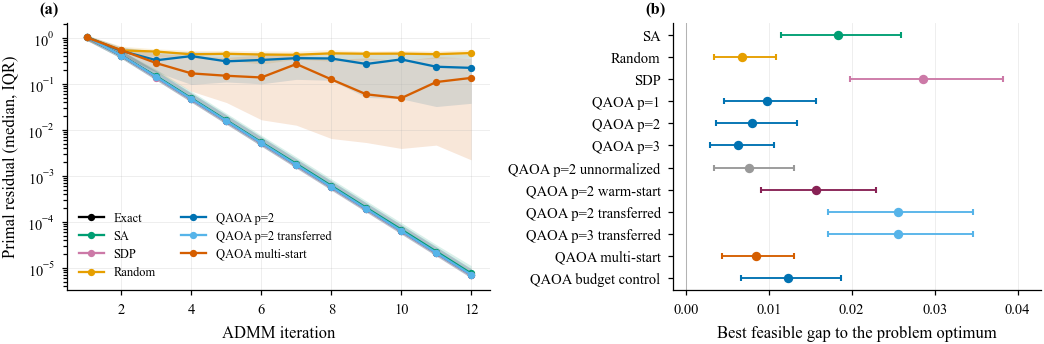

Saved figures/fig01_admm_outcome.png and .pdf


In [45]:
# ADMM-level outcome
it = A["iters"]; F1_ARMS = ["Exact", "SA", "SDP", "Random", "QAOA p=2", "QAOA p=2 transferred", "QAOA multi-start"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(COL2, 2.5), gridspec_kw={"width_ratios": [1.15, 1]})
for a in F1_ARMS:
    g = it[it.arm == a].groupby("iter")["resid"]; x = np.arange(1, K_MAIN + 1)
    a1.fill_between(x, g.quantile(0.25).clip(lower=1e-12), g.quantile(0.75), color=colr(a), alpha=0.15, lw=0)
    a1.plot(x, g.median().clip(lower=1e-12), "o-", color=colr(a), ms=2.5, label=a)
a1.set_yscale("log"); a1.set_xlabel("ADMM iteration"); a1.set_ylabel("Primal residual (median, IQR)")
a1.legend(ncol=2, loc="lower left", fontsize=6); panel_label(a1, "a")
ci_rows(a2, dA, [a for a in ORDER_A if a != "Exact"], "mbo_gap_best_unif", xlabel="Best feasible gap to the problem optimum")
panel_label(a2, "b"); fig.tight_layout(); save_figure(fig, "fig01_admm_outcome")

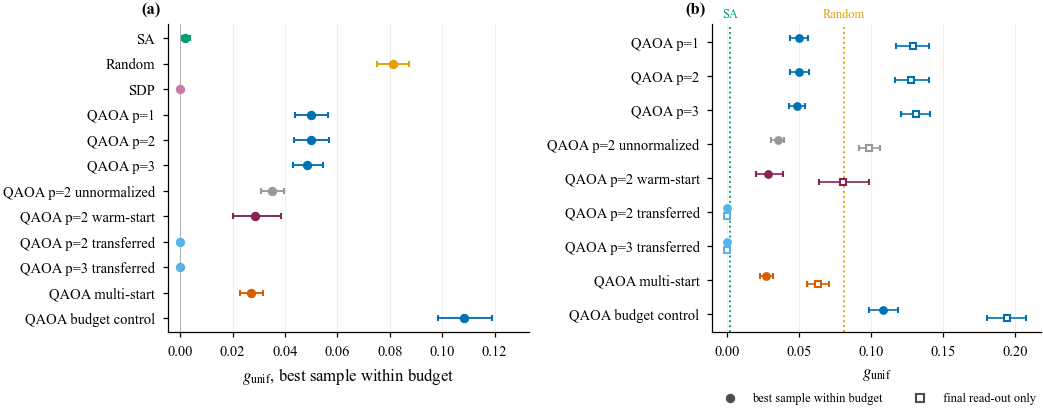

Saved figures/fig02_main_comparison.png and .pdf


In [46]:
# Main comparison under both scoring rules
fig, (a1, a2) = plt.subplots(1, 2, figsize=(COL2, 3.0), gridspec_kw={"width_ratios": [1.1, 1]})
ci_rows(a1, dA, [a for a in ORDER_A if a != "Exact"], "gap_unif", xlabel=r"$g_{\mathrm{unif}}$, best sample within budget")
panel_label(a1, "a")
y = np.arange(len(QAOA_A))[::-1]
for yi, a in zip(y, QAOA_A):
    s = dA[dA.arm == a]
    for metric, mk, off in (("gap_unif", "o", 0.12), ("gap_ro_unif", "s", -0.12)):
        m, lo, hi = bootstrap_ci(s[metric])
        a2.errorbar(m, yi + off, xerr=[[m - lo], [hi - m]], fmt=mk, color=colr(a), mfc="white" if mk == "s" else colr(a), ms=3.2, capsize=1.5, elinewidth=0.8)
for ref in ("Random", "SA"):
    m = dA[dA.arm == ref].gap_unif.mean(); a2.axvline(m, color=colr(ref), ls=":", lw=0.9)
    a2.text(m, len(QAOA_A) - 0.3, ref, color=colr(ref), fontsize=6, ha="center")
a2.set_yticks(y); a2.set_yticklabels(QAOA_A); a2.set_xlabel(r"$g_{\mathrm{unif}}$")
a2.plot([], [], "o", color="0.3", label="best sample within budget"); a2.plot([], [], "s", color="0.3", mfc="white", label="final read-out only")
a2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=6); a2.grid(axis="y", alpha=0); panel_label(a2, "b")
fig.tight_layout(); save_figure(fig, "fig02_main_comparison")

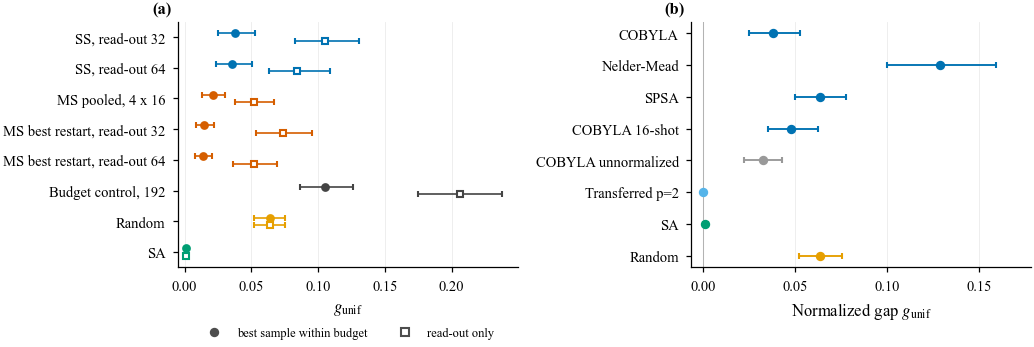

Saved figures/fig03_mechanism_ablation.png and .pdf


In [47]:
# Mechanism decomposition and optimizer ablation
fig, (a1, a2) = plt.subplots(1, 2, figsize=(COL2, 2.6))
arms3 = list(MECH); y = np.arange(len(arms3))[::-1]
for yi, a in zip(y, arms3):
    s = dM[dM.arm == a]
    for metric, mk, off in (("gap_unif", "o", 0.12), ("gap_ro_unif", "s", -0.12)):
        m, lo, hi = bootstrap_ci(s[metric])
        a1.errorbar(m, yi + off, xerr=[[m - lo], [hi - m]], fmt=mk, color=colr(a), mfc="white" if mk == "s" else colr(a), ms=3.2, capsize=1.5, elinewidth=0.8)
a1.set_yticks(y); a1.set_yticklabels(arms3); a1.set_xlabel(r"$g_{\mathrm{unif}}$"); a1.set_xlim(left=-0.005)
a1.plot([], [], "o", color="0.3", label="best sample within budget"); a1.plot([], [], "s", color="0.3", mfc="white", label="read-out only")
a1.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2); a1.grid(axis="y", alpha=0); panel_label(a1, "a")
ci_rows(a2, dB, list(ABL), "gap_unif"); panel_label(a2, "b")
fig.tight_layout(); save_figure(fig, "fig03_mechanism_ablation")

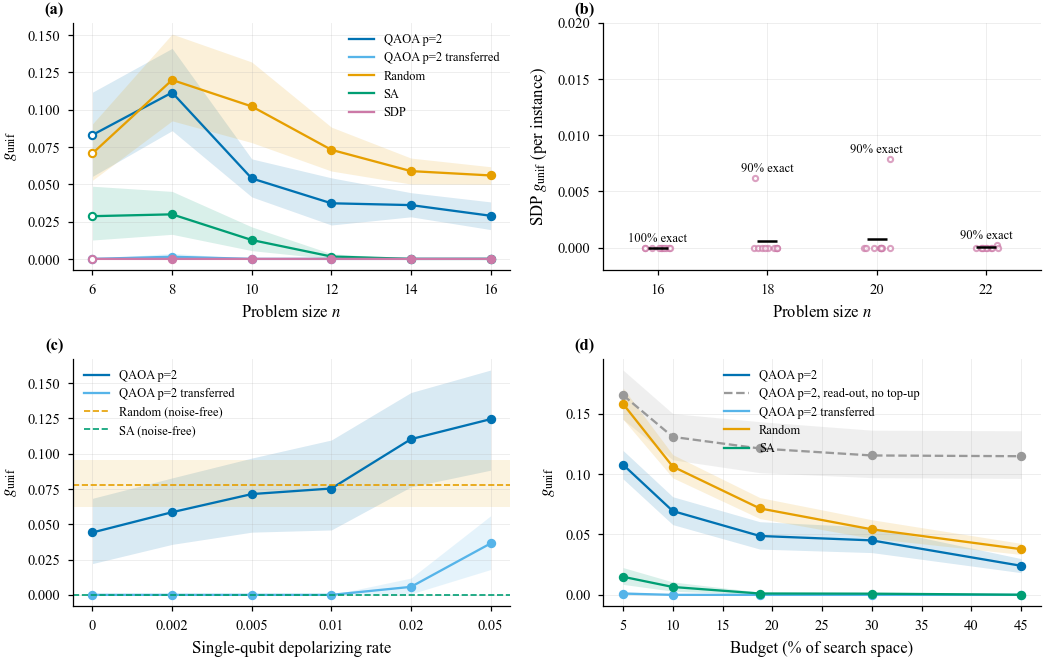

Saved figures/fig04_robustness.png and .pdf


In [48]:
# Robustness: size (fixed fraction), SDP extension, noise, budget
fig, ax = plt.subplots(2, 2, figsize=(COL2, 4.6)); (a1, a2), (a3, a4) = ax
for a in ["QAOA p=2", "QAOA p=2 transferred", "Random", "SA", "SDP"]:
    s = dD[dD.arm == a]; ns = sorted(s.n.unique())
    line_ci(a1, ns, [s[s.n == n_].gap_unif for n_ in ns], a, colr(a), hollow_at=[6])
a1.set_xlabel("Problem size $n$"); a1.set_ylabel(r"$g_{\mathrm{unif}}$"); a1.set_xticks(SIZES); a1.legend(fontsize=6); panel_label(a1, "a")
rng_j = np.random.default_rng(0)
for n_, s in dX.groupby("n"):
    a2.plot(n_ + rng_j.uniform(-0.25, 0.25, len(s)), s.gap_unif, "o", color=C["SDP"], ms=2.5, alpha=0.7, mfc="white")
    a2.plot(n_, s.gap_unif.mean(), "_", color="k", ms=10, mew=1.2)
    a2.annotate(f"{s.hit.mean():.0%} exact", (n_, s.gap_unif.max()), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=6)
a2.set_ylim(-0.002, max(0.02, 1.25 * dX.gap_unif.max())); a2.set_xlim(min(SIZES_SDPX) - 1, max(SIZES_SDPX) + 1)
a2.set_xlabel("Problem size $n$"); a2.set_ylabel(r"SDP $g_{\mathrm{unif}}$ (per instance)"); a2.set_xticks(SIZES_SDPX); panel_label(a2, "b")
xs = np.arange(len(NOISE_LEVELS))
for a in ["QAOA p=2", "QAOA p=2 transferred"]:
    s = dE[dE.arm == a]; line_ci(a3, xs, [s[s.noise == p].gap_unif for p in NOISE_LEVELS], a, colr(a))
for ref in ("Random", "SA"):
    m, lo, hi = bootstrap_ci(dE[dE.arm == ref].gap_unif)
    a3.axhspan(lo, hi, color=colr(ref), alpha=0.12, lw=0); a3.axhline(m, color=colr(ref), ls="--", lw=0.8, label=f"{ref} (noise-free)")
a3.set_xticks(xs); a3.set_xticklabels([f"{p:g}" for p in NOISE_LEVELS]); a3.set_xlabel("Single-qubit depolarizing rate")
a3.set_ylabel(r"$g_{\mathrm{unif}}$"); a3.legend(fontsize=6); panel_label(a3, "c")
fr = np.array(BUDGET_FRACS) * 100
for a, metric, ls, lab in [("QAOA p=2", "gap_unif", "-", "QAOA p=2"), ("QAOA p=2, no top-up", "gap_ro_unif", "--", "QAOA p=2, read-out, no top-up"),
                           ("QAOA p=2 transferred", "gap_unif", "-", "QAOA p=2 transferred"), ("Random", "gap_unif", "-", "Random"), ("SA", "gap_unif", "-", "SA")]:
    s = dF[dF.arm == a]; line_ci(a4, fr, [s[s.frac == f][metric] for f in BUDGET_FRACS], lab, colr(a), ls=ls)
a4.set_xlabel("Budget (% of search space)"); a4.set_ylabel(r"$g_{\mathrm{unif}}$"); a4.legend(fontsize=6); panel_label(a4, "d")
fig.tight_layout(); save_figure(fig, "fig04_robustness")

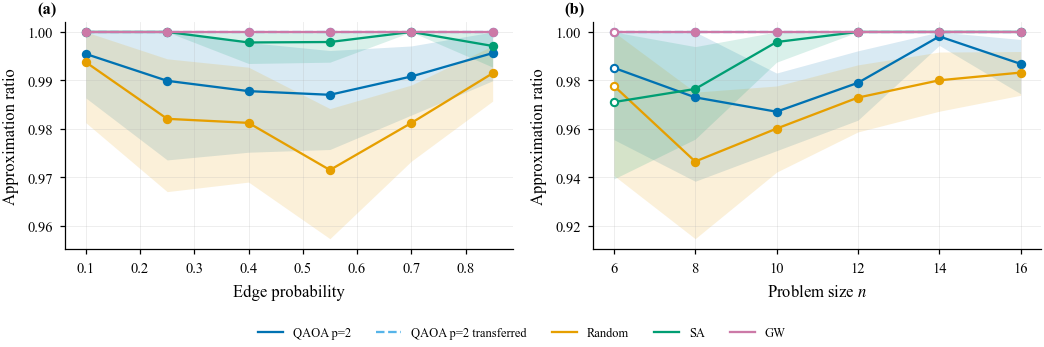

Saved figures/fig05_maxcut.png and .pdf


In [49]:
# MaxCut
fig, (a1, a2) = plt.subplots(1, 2, figsize=(COL2, 2.4))
for a in ["QAOA p=2", "QAOA p=2 transferred", "Random", "SA", "GW"]:
    ls_ = "--" if "transferred" in a else "-"
    s = dGd[dGd.arm == a]; line_ci(a1, DENSITY_SWEEP, [s[s.p_edge == p].approx for p in DENSITY_SWEEP], a, colr(a), ls=ls_)
    s = dGs[dGs.arm == a]; ns = sorted(s.n.unique()); line_ci(a2, ns, [s[s.n == n_].approx for n_ in ns], a, colr(a), ls=ls_, hollow_at=[6])
a1.set_xlabel("Edge probability"); a1.set_ylabel("Approximation ratio"); panel_label(a1, "a")
fig.legend(*a1.get_legend_handles_labels(), loc="lower center", ncol=5, fontsize=6, bbox_to_anchor=(0.5, -0.02))
a2.set_xlabel("Problem size $n$"); a2.set_ylabel("Approximation ratio"); a2.set_xticks(SIZES); panel_label(a2, "b")
fig.tight_layout(rect=[0, 0.07, 1, 1]); save_figure(fig, "fig05_maxcut")

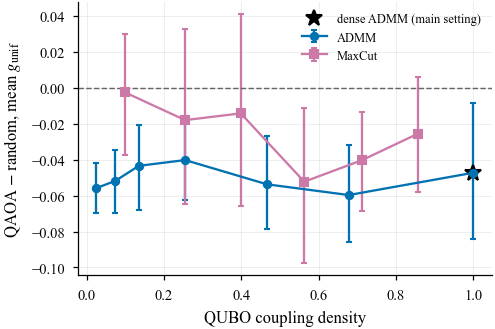

Saved figures/fig06_density.png and .pdf


In [50]:
# Coupling density
fig, ax = plt.subplots(figsize=(COL1, 2.4))
for fam_, mk in (("ADMM", "o"), ("MaxCut", "s")):
    s = dens_tab[dens_tab.family == fam_].sort_values("density")
    ax.errorbar(s.density, s.delta, yerr=[s.delta - s.lo, s.hi - s.delta], fmt=mk + "-", ms=3.5, capsize=1.5,
                color=C["QAOA"] if fam_ == "ADMM" else C["GW"], label=fam_)
dd = dens_tab[(dens_tab.family == "ADMM") & (dens_tab.level == "dense")]
ax.plot(dd.density, dd.delta, "*", color="k", ms=8, label="dense ADMM (main setting)")
ax.axhline(0, color="0.4", lw=0.7, ls="--")
ax.set_xlabel("QUBO coupling density"); ax.set_ylabel(r"QAOA $-$ random, mean $g_{\mathrm{unif}}$"); ax.legend(fontsize=6)
fig.tight_layout(); save_figure(fig, "fig06_density")

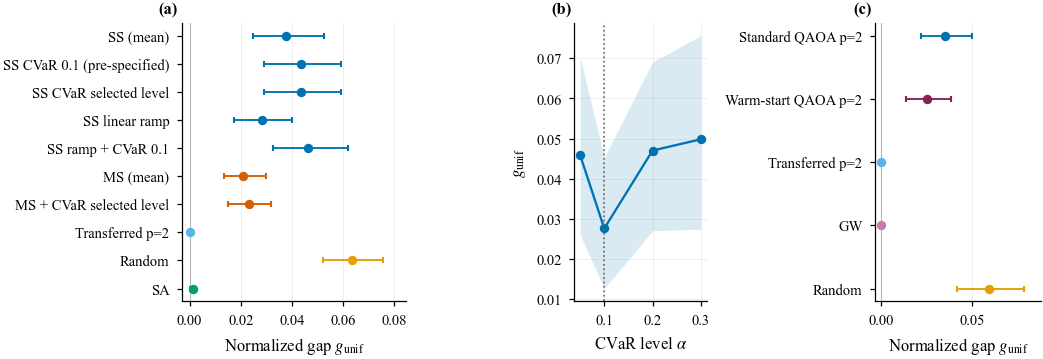

Saved figures/fig07_landscape.png and .pdf


In [51]:
# Landscape mitigation
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(COL2, 2.6), gridspec_kw={"width_ratios": [1.35, 0.8, 1]})
ci_rows(a1, dL, list(LAND), "gap_unif"); panel_label(a1, "a")
sel = SEL["seeds"]; al = [float(a.split()[-1]) for a in sel_arms]
line_ci(a2, al, [sel[sel.arm == a].gap_unif for a in sel_arms], "CVaR, held-out instances", C["QAOA"])
a2.axvline(ALPHA_STAR, color="0.4", ls=":", lw=0.8); a2.set_xlabel(r"CVaR level $\alpha$"); a2.set_ylabel(r"$g_{\mathrm{unif}}$"); panel_label(a2, "b")
ci_rows(a3, dW, list(WS), "gap_unif"); panel_label(a3, "c")
fig.tight_layout(); save_figure(fig, "fig07_landscape")

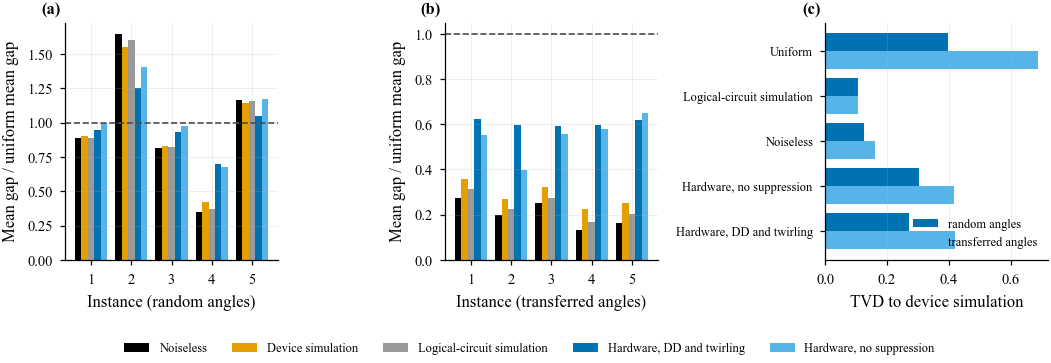

Saved figures/fig08_hardware.png and .pdf


In [52]:
# Hardware validation, n = 8
conds = [c_ for c_ in ["noiseless", "device sim (transpiled)", "noisy sim (logical)", "hardware (suppressed)", "hardware (unsuppressed)"]
         if c_ in set(dH.condition)]
short = {"noiseless": "Noiseless", "device sim (transpiled)": "Device simulation", "noisy sim (logical)": "Logical-circuit simulation",
         "hardware (suppressed)": "Hardware, DD and twirling", "hardware (unsuppressed)": "Hardware, no suppression", "uniform": "Uniform"}
ccol = {"noiseless": "#000000", "device sim (transpiled)": C["Sim"], "noisy sim (logical)": "#999999",
        "hardware (suppressed)": C["HW"], "hardware (unsuppressed)": "#56B4E9"}
fig, axs = plt.subplots(1, 3, figsize=(COL2, 2.5), gridspec_kw={"width_ratios": [1, 1, 1.05]})
for k, ang in enumerate(("random", "transferred")):
    axk = axs[k]; s = dH[dH.angles == ang]; seeds_ = sorted(s.seed.unique()); w = 0.8 / len(conds)
    for j, c_ in enumerate(conds):
        v = s[s.condition == c_].sort_values("seed").mean_gap_rel_uniform.values
        axk.bar(np.arange(len(seeds_)) + (j - (len(conds) - 1) / 2) * w, v, w, color=ccol[c_], label=short[c_])
    axk.axhline(1.0, color="0.3", ls="--", lw=0.8); axk.set_xticks(range(len(seeds_))); axk.set_xticklabels([str(i + 1) for i in seeds_])
    axk.set_ylabel("Mean gap / uniform mean gap"); axk.set_xlabel(f"Instance ({ang} angles)"); panel_label(axk, "ab"[k])
fig.legend(*axs[0].get_legend_handles_labels(), loc="lower center", ncol=len(conds), fontsize=6, bbox_to_anchor=(0.5, -0.02))
if "tvd_vs_device" in dH:
    t_ = dH[dH.condition != "device sim (transpiled)"].groupby(["condition", "angles"]).tvd_vs_device.mean().unstack()
    t_.index = [short.get(i, i) for i in t_.index]; yy = np.arange(len(t_))
    axs[2].barh(yy + 0.2, t_["random"], 0.4, color=C["QAOA"], label="random angles")
    axs[2].barh(yy - 0.2, t_["transferred"], 0.4, color=C["QAOA-T"], label="transferred angles")
    axs[2].set_yticks(yy); axs[2].set_yticklabels(t_.index, fontsize=6); axs[2].set_xlabel("TVD to device simulation")
    axs[2].legend(fontsize=6, loc="lower right"); axs[2].grid(axis="y", alpha=0); panel_label(axs[2], "c")
fig.tight_layout(rect=[0, 0.08, 1, 1]); save_figure(fig, "fig08_hardware")

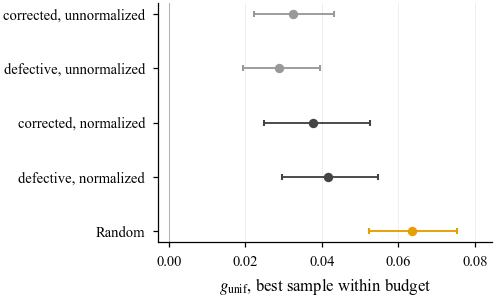

Saved figures/fig09_defect.png and .pdf


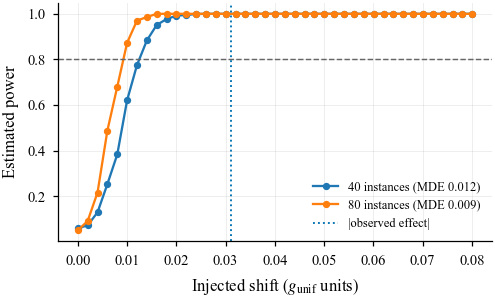

Saved figures/fig10_power.png and .pdf


In [53]:
# Hamiltonian defect
fig, ax = plt.subplots(figsize=(COL1, 2.2))
ci_rows(ax, dJ, ["corrected, unnormalized", "defective, unnormalized", "corrected, normalized", "defective, normalized", "Random"],
        "gap_unif", xlabel=r"$g_{\mathrm{unif}}$, best sample within budget")
fig.tight_layout(); save_figure(fig, "fig09_defect")

# Sensitivity
fig, ax = plt.subplots(figsize=(COL1, 2.2))
for nt, pw in POWER.items():
    ax.plot(MDE_GRID, pw, "o-", ms=2.5, label=f"{nt} instances (MDE {interp_mde(MDE_GRID, pw):.3f})")
ax.axhline(0.8, color="0.4", ls="--", lw=0.7); ax.axvline(abs(np.mean(mde_diffs)), color=C["QAOA"], ls=":", lw=0.9, label="|observed effect|")
ax.set_xlabel(r"Injected shift ($g_{\mathrm{unif}}$ units)"); ax.set_ylabel("Estimated power"); ax.legend(fontsize=6)
fig.tight_layout(); save_figure(fig, "fig10_power")

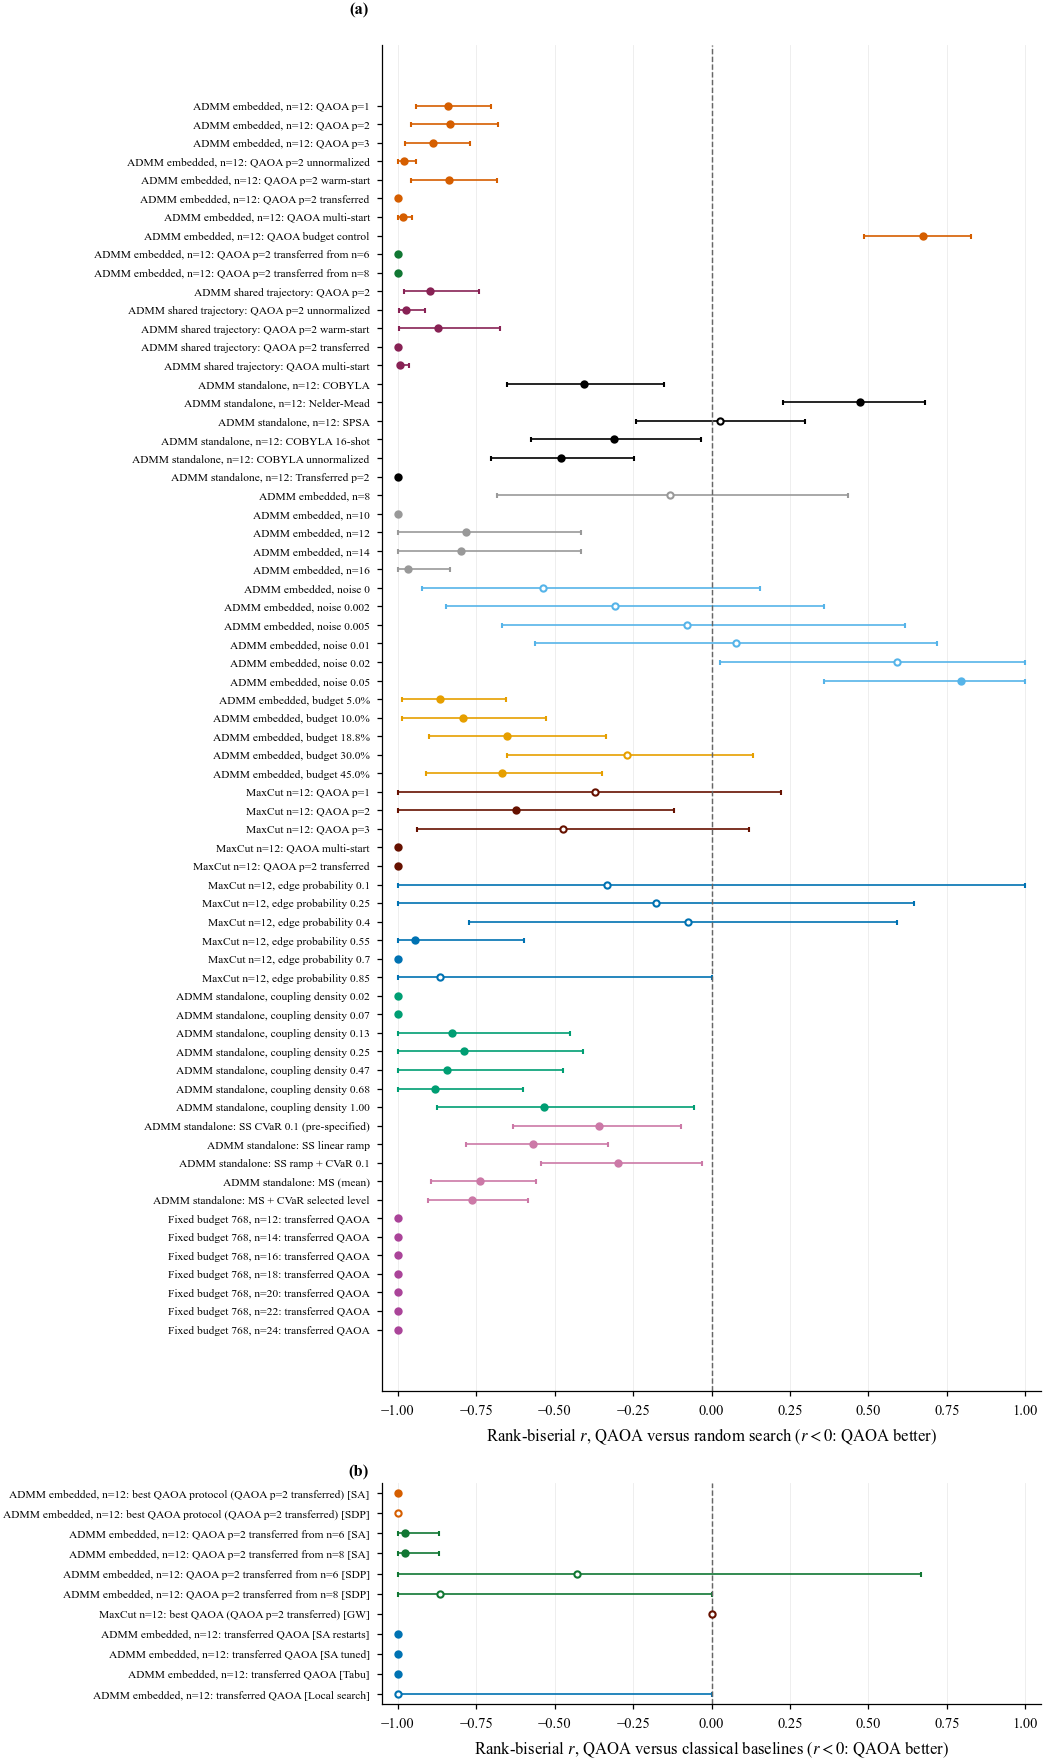

Saved figures/fig11_viability_map.png and .pdf


In [54]:
# Viability map
vr = dV[dV.comparator == "Random"].reset_index(drop=True); vc = dV[dV.comparator != "Random"].reset_index(drop=True)
h_ = 0.14 * (len(vr) + len(vc)) + 1.0
fig, (a1, a2) = plt.subplots(2, 1, figsize=(COL2, h_), gridspec_kw={"height_ratios": [max(len(vr), 1), max(len(vc), 1)]})
_pal = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#882255", "#999999", "#000000", "#117733", "#AA4499", "#661100"]
gcol = {g: _pal[i % len(_pal)] for i, g in enumerate(sorted(dV.group.unique()))}
for axk, s, ttl in ((a1, vr, "versus random search"), (a2, vc, "versus classical baselines")):
    y = np.arange(len(s))[::-1]
    for yi, (_, t) in zip(y, s.iterrows()):
        axk.errorbar(t.r, yi, xerr=[[t.r - t.r_lo], [t.r_hi - t.r]], fmt="o", ms=3, color=gcol[t.group],
                     mfc=gcol[t.group] if t.P < 0.05 else "white", capsize=1.2, elinewidth=0.8)
    axk.set_yticks(y); axk.set_yticklabels([f"{t.setting} [{t.comparator}]" if s is vc else t.setting for _, t in s.iterrows()], fontsize=5.5)
    axk.axvline(0, color="0.4", ls="--", lw=0.7); axk.set_xlim(-1.05, 1.05); axk.grid(axis="y", alpha=0)
    axk.set_xlabel(f"Rank-biserial $r$, QAOA {ttl} ($r<0$: QAOA better)")
panel_label(a1, "a"); panel_label(a2, "b")
fig.tight_layout(); save_figure(fig, "fig11_viability_map")

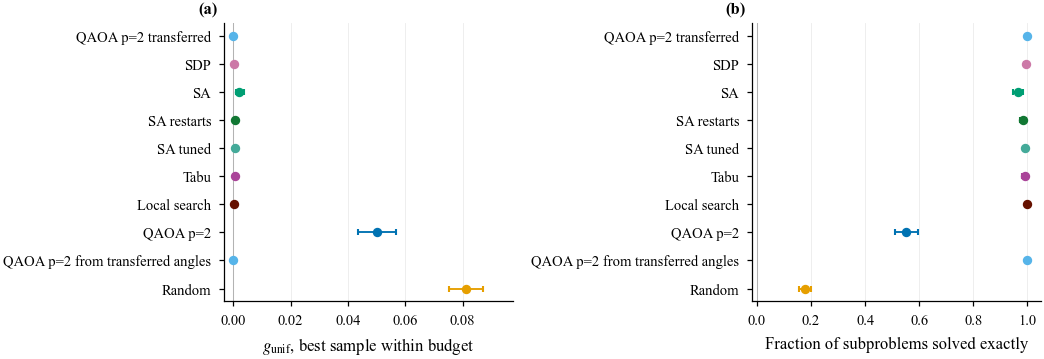

Saved figures/fig12_baselines.png and .pdf


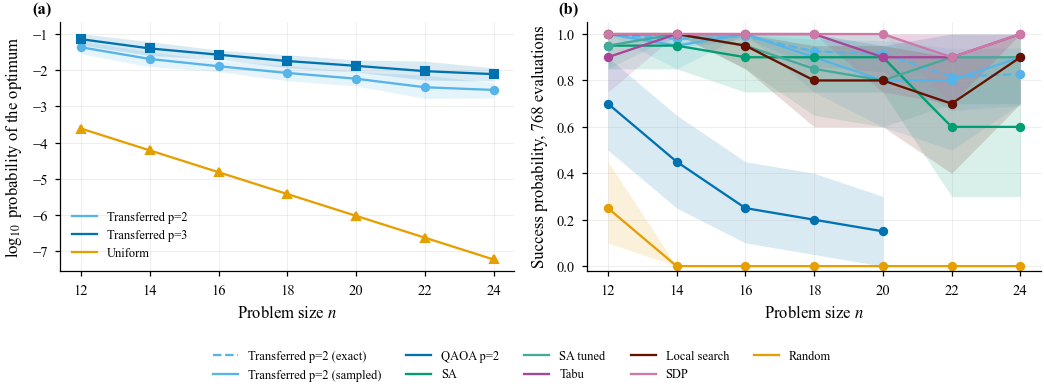

Saved figures/fig13_fixed_budget.png and .pdf


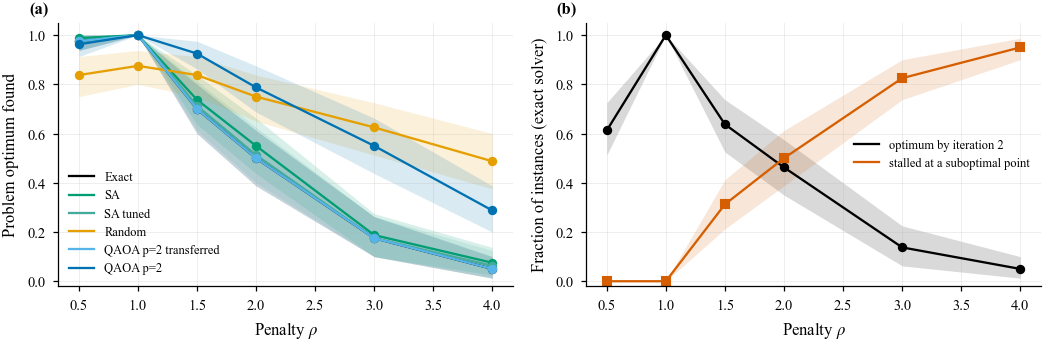

Saved figures/fig14_penalty.png and .pdf


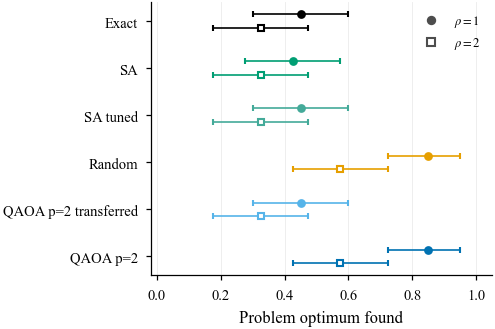

Saved figures/fig15_general_family.png and .pdf


In [55]:
# Stronger baselines
fig, (a1, a2) = plt.subplots(1, 2, figsize=(COL2, 2.6))
ci_rows(a1, dR, ORDER_R, "gap_unif", xlabel=r"$g_{\mathrm{unif}}$, best sample within budget"); panel_label(a1, "a")
ci_rows(a2, dR, ORDER_R, "hit", xlabel="Fraction of subproblems solved exactly", xlim=(-0.02, 1.05)); panel_label(a2, "b")
fig.tight_layout(); save_figure(fig, "fig12_baselines")

# Fixed absolute budget
fig, (a1, a2) = plt.subplots(1, 2, figsize=(COL2, 2.7))
for nm_, cl, mk in (("Transferred p=2", C["QAOA-T"], "o"), ("Transferred p=3", C["QAOA"], "s"), ("Uniform", C["Random"], "^")):
    s = dFa[dFa.dist == nm_]; ns = sorted(s.n.unique())
    line_ci(a1, ns, [np.log10(np.maximum(s[s.n == n_].q, 1e-300)) for n_ in ns], nm_, cl, marker=mk)
a1.set_xlabel("Problem size $n$"); a1.set_ylabel(r"$\log_{10}$ probability of the optimum"); a1.set_xticks(FIX_SIZES); a1.legend(fontsize=6); panel_label(a1, "a")
s = dFa[dFa.dist == "Transferred p=2"]; ns = sorted(s.n.unique())
line_ci(a2, ns, [s[s.n == n_].success_B768 for n_ in ns], "Transferred p=2 (exact)", C["QAOA-T"], ls="--")
for a in ["Transferred p=2", "QAOA p=2", "SA", "SA tuned", "Tabu", "Local search", "SDP", "Random"]:
    s = dFs[dFs.arm == a]; ns = sorted(s.n.unique())
    if len(ns): line_ci(a2, ns, [s[s.n == n_].hit for n_ in ns], a if a != "Transferred p=2" else "Transferred p=2 (sampled)", colr(a if a != "Transferred p=2" else "QAOA p=2 transferred"))
a2.set_xlabel("Problem size $n$"); a2.set_ylabel("Success probability, 768 evaluations"); a2.set_xticks(FIX_SIZES)
a2.set_ylim(-0.02, 1.05); panel_label(a2, "b")
fig.legend(*a2.get_legend_handles_labels(), loc="lower center", ncol=5, fontsize=6, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=[0, 0.12, 1, 1]); save_figure(fig, "fig13_fixed_budget")

# Penalty sweep
fig, (a1, a2) = plt.subplots(1, 2, figsize=(COL2, 2.5))
for a in arms_P:
    s = dP[dP.arm == a]; line_ci(a1, RHOS, [s[s.rho == r_].mbo_opt_found for r_ in RHOS], a, colr(a))
a1.set_xlabel(r"Penalty $\rho$"); a1.set_ylabel("Problem optimum found"); a1.set_ylim(-0.02, 1.05); a1.legend(fontsize=6); panel_label(a1, "a")
line_ci(a2, RHOS, [thm[thm.rho == r_].global_by_iter2 for r_ in RHOS], "optimum by iteration 2", C["Exact"])
line_ci(a2, RHOS, [thm[thm.rho == r_].stalled_suboptimal for r_ in RHOS], "stalled at a suboptimal point", C["Noise"], marker="s")
a2.set_xlabel(r"Penalty $\rho$"); a2.set_ylabel("Fraction of instances (exact solver)"); a2.set_ylim(-0.02, 1.05); a2.legend(fontsize=6); panel_label(a2, "b")
fig.tight_layout(); save_figure(fig, "fig14_penalty")

# General mixed-binary family
fig, ax = plt.subplots(figsize=(COL1, 2.4)); arms_g = list(arms_G); y = np.arange(len(arms_g))[::-1]
for off, r_, mk in ((0.14, 1.0, "o"), (-0.14, 2.0, "s")):
    s = dG[dG.rho == r_]
    for yi, a in zip(y, arms_g):
        m, lo, hi = bootstrap_ci(s[s.arm == a].mbo_opt_found)
        ax.errorbar(m, yi + off, xerr=[[m - lo], [hi - m]], fmt=mk, color=colr(a), mfc="white" if r_ == 2.0 else colr(a), ms=3.2, capsize=1.5, elinewidth=0.8)
ax.plot([], [], "o", color="0.3", label=r"$\rho=1$"); ax.plot([], [], "s", color="0.3", mfc="white", label=r"$\rho=2$")
ax.set_yticks(y); ax.set_yticklabels(arms_g); ax.set_xlabel("Problem optimum found"); ax.set_xlim(-0.02, 1.05); ax.legend(fontsize=6); ax.grid(axis="y", alpha=0)
fig.tight_layout(); save_figure(fig, "fig15_general_family")

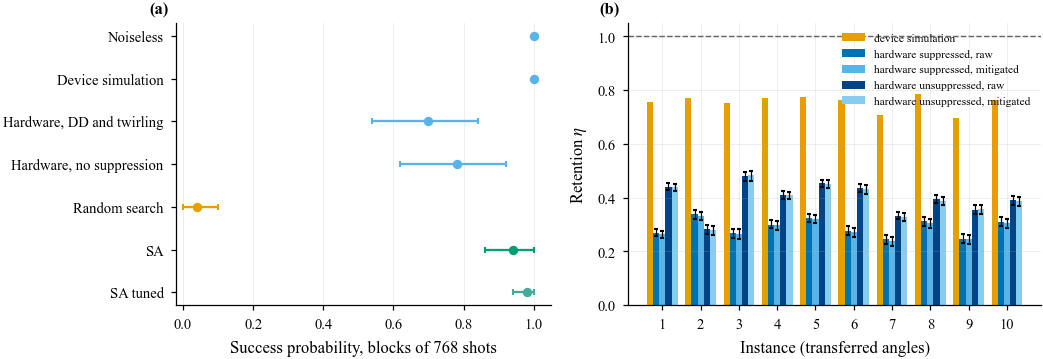

Saved figures/fig16_hardware_n12.png and .pdf


In [56]:
# Hardware at n = 12
if H12 is not None:
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(COL2, 2.6), gridspec_kw={"width_ratios": [1, 1.1]})
    order_ = [c_ for c_ in ["noiseless", "device simulation", "hardware suppressed, raw", "hardware unsuppressed, raw"] if c_ in set(d12.condition)]
    labs_ = {"noiseless": "Noiseless", "device simulation": "Device simulation", "hardware suppressed, raw": "Hardware, DD and twirling",
             "hardware unsuppressed, raw": "Hardware, no suppression", "Random": "Random search", "SA": "SA", "SA tuned": "SA tuned"}
    rows_ = [(labs_[c_], d12[(d12.angles == "transferred") & (d12.condition == c_)].hit, C["QAOA-T"]) for c_ in order_]
    rows_ += [(labs_[c_], d12[d12.condition == c_].hit, colr(c_)) for c_ in ("Random", "SA", "SA tuned")]
    yy = np.arange(len(rows_))[::-1]
    for yi, (lab, v, cl) in zip(yy, rows_):
        m, lo, hi = bootstrap_ci(v); a1.errorbar(m, yi, xerr=[[m - lo], [hi - m]], fmt="o", color=cl, ms=3.5, capsize=1.5)
    a1.set_yticks(yy); a1.set_yticklabels([r[0] for r in rows_]); a1.set_xlim(-0.02, 1.05); a1.grid(axis="y", alpha=0)
    a1.set_xlabel("Success probability, blocks of 768 shots"); panel_label(a1, "a")
    et = e12[e12.angles == "transferred"]; conds_ = list(dict.fromkeys(et.condition)); w = 0.8 / max(len(conds_), 1)
    pal_ = [C["Sim"], C["HW"], "#56B4E9", "#004488", "#88CCEE"]
    for j, c_ in enumerate(conds_):
        s = et[et.condition == c_].sort_values("seed"); xx = np.arange(len(s)) + (j - (len(conds_) - 1) / 2) * w
        err = np.vstack([s.eta - s.eta_lo, s.eta_hi - s.eta]) if s.eta_lo.notna().any() else None
        a2.bar(xx, s.eta, w, color=pal_[j % len(pal_)], label=c_, yerr=err, capsize=1, error_kw={"elinewidth": 0.6})
    a2.axhline(1.0, color="0.4", ls="--", lw=0.7); a2.set_xlabel("Instance (transferred angles)"); a2.set_ylabel(r"Retention $\eta$")
    a2.set_xticks(range(N_HW12)); a2.set_xticklabels([str(i + 1) for i in range(N_HW12)]); a2.legend(fontsize=5.5); panel_label(a2, "b")
    fig.tight_layout(); save_figure(fig, "fig16_hardware_n12")

## 35. Response to review

| Concern | Section | Output |
|---|---|---|
| Budget saturates the problems; scaling hidden by a fixed budget fraction | 26 | `R26_fixed_budget_*.csv`, `R26_embedded_*.csv`, Fig. 13 |
| Weak classical baselines; asymmetric tuning; cost per evaluation | 25, 30 | `R25_*.csv`, `R30_cost.csv`, Fig. 12 |
| ADMM total budget exceeds enumeration; penalty prediction untested | 26, 27 | `R26_embedded_*.csv`, `R27_*.csv`, Fig. 14 |
| Test problem reduces to a QUBO; generality of the theorem | 28 | `R28_general_*.csv`, generalized identity check, Fig. 15 |
| Hardware study does not exercise best-sample scoring | 29 | `R29_*.csv`, `R29_hardware_n12.json`, Fig. 16 |
| Normal approximation with few non-tied pairs; equivalence claims; duplicate tests | 7, 30, 33 | exact tests throughout, `R30_equivalence.csv`, `S25_test_registry.csv` |
| Effects in natural units | 30 | `R30_effects.csv` |
| Internal labels in figures; overlapping ticks | 34 | all figures |